# 多模态 AIGC 图像生成 04：Stable Diffusion 的训练与部署

本篇对应讲义《04-StableDiffusion的训练与部署.pdf》，按原课程顺序整理四部分：

1. 高性能应用服务 HAI 的平台定位、硬件要求与应用场景；
2. 创建 Stable Diffusion 实例，并使用 WebUI 和 JupyterLab；
3. DreamBooth 与 LoRA 两种训练方法；
4. 训练模型的获取、预测和 WebUI 使用方式。

讲义中的宣传页和结束页已省略。训练代码和参数按讲义截图核对整理，原图随对应步骤保留。命令中的 `!`、`$变量`、`{变量}` 来自课程 Jupyter/IPython 环境；代码用于阅读，不能当作独立终端脚本直接执行。

## 一、高性能应用服务 HAI

### 1. Stable Diffusion 的硬件要求

讲义建议优先使用带 NVIDIA 显卡的 Windows 系统；macOS 默认主要依赖 CPU，图形性能、插件支持和模型训练能力有限。课程建议把 Stable Diffusion 部署在云端 GPU 服务器上。

| 项目 | 推荐配置 | 最低配置 | 讲义说明 |
| --- | --- | --- | --- |
| 操作系统 | Windows 10/11、macOS、Linux | 无要求 | 系统本身不是主要瓶颈 |
| CPU | 64 位多核处理器 | 无要求 | 需要配合 GPU 使用 |
| GPU | NVIDIA，RTX 3060 以上算力 | GTX 1660 以上性能显卡 | 推荐显存 8GB 以上，最低 6GB |
| 内存 | 16GB 以上 | 8GB | 影响运行和训练稳定性 |
| 硬盘 | 100GB 以上 | 20GB 以上 | 需要容纳模型、依赖和生成结果 |
| 出图效果 | 约 10–30 秒，可生成 1024×1024 | 约 1–3 分钟，可生成 512×512 | 实际速度取决于硬件和参数 |

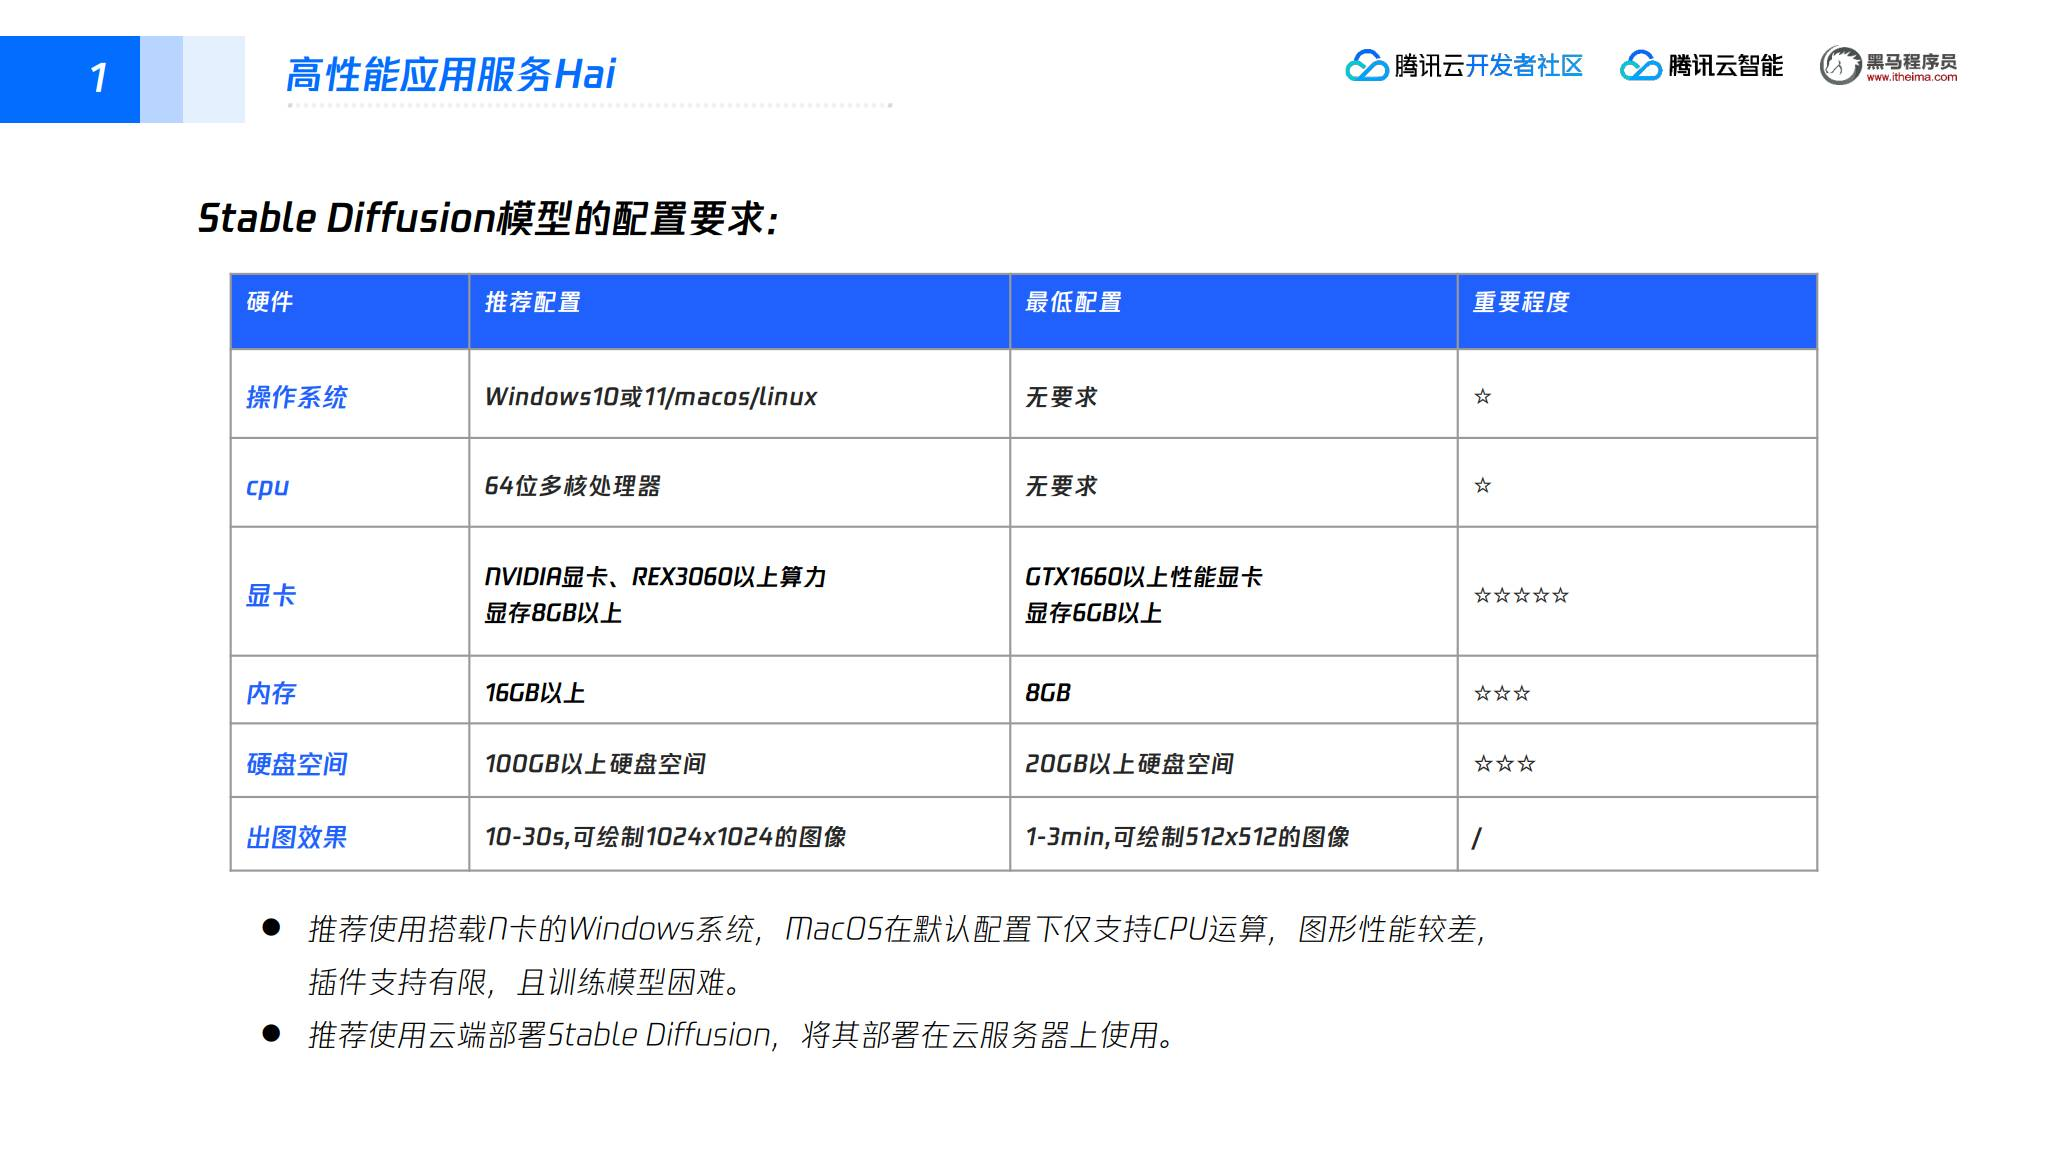

### 2. HAI 的定位

HAI 是面向高性能应用的 GPU 云服务：以应用为中心匹配 GPU 云算力资源，帮助开发者快速部署大模型、AI 作画和数据科学环境。

课程强调其“即开即用”的方式：用户不需要手工完成全部服务器和依赖配置，平台会根据应用推荐算力资源，并提供预装的模型环境。

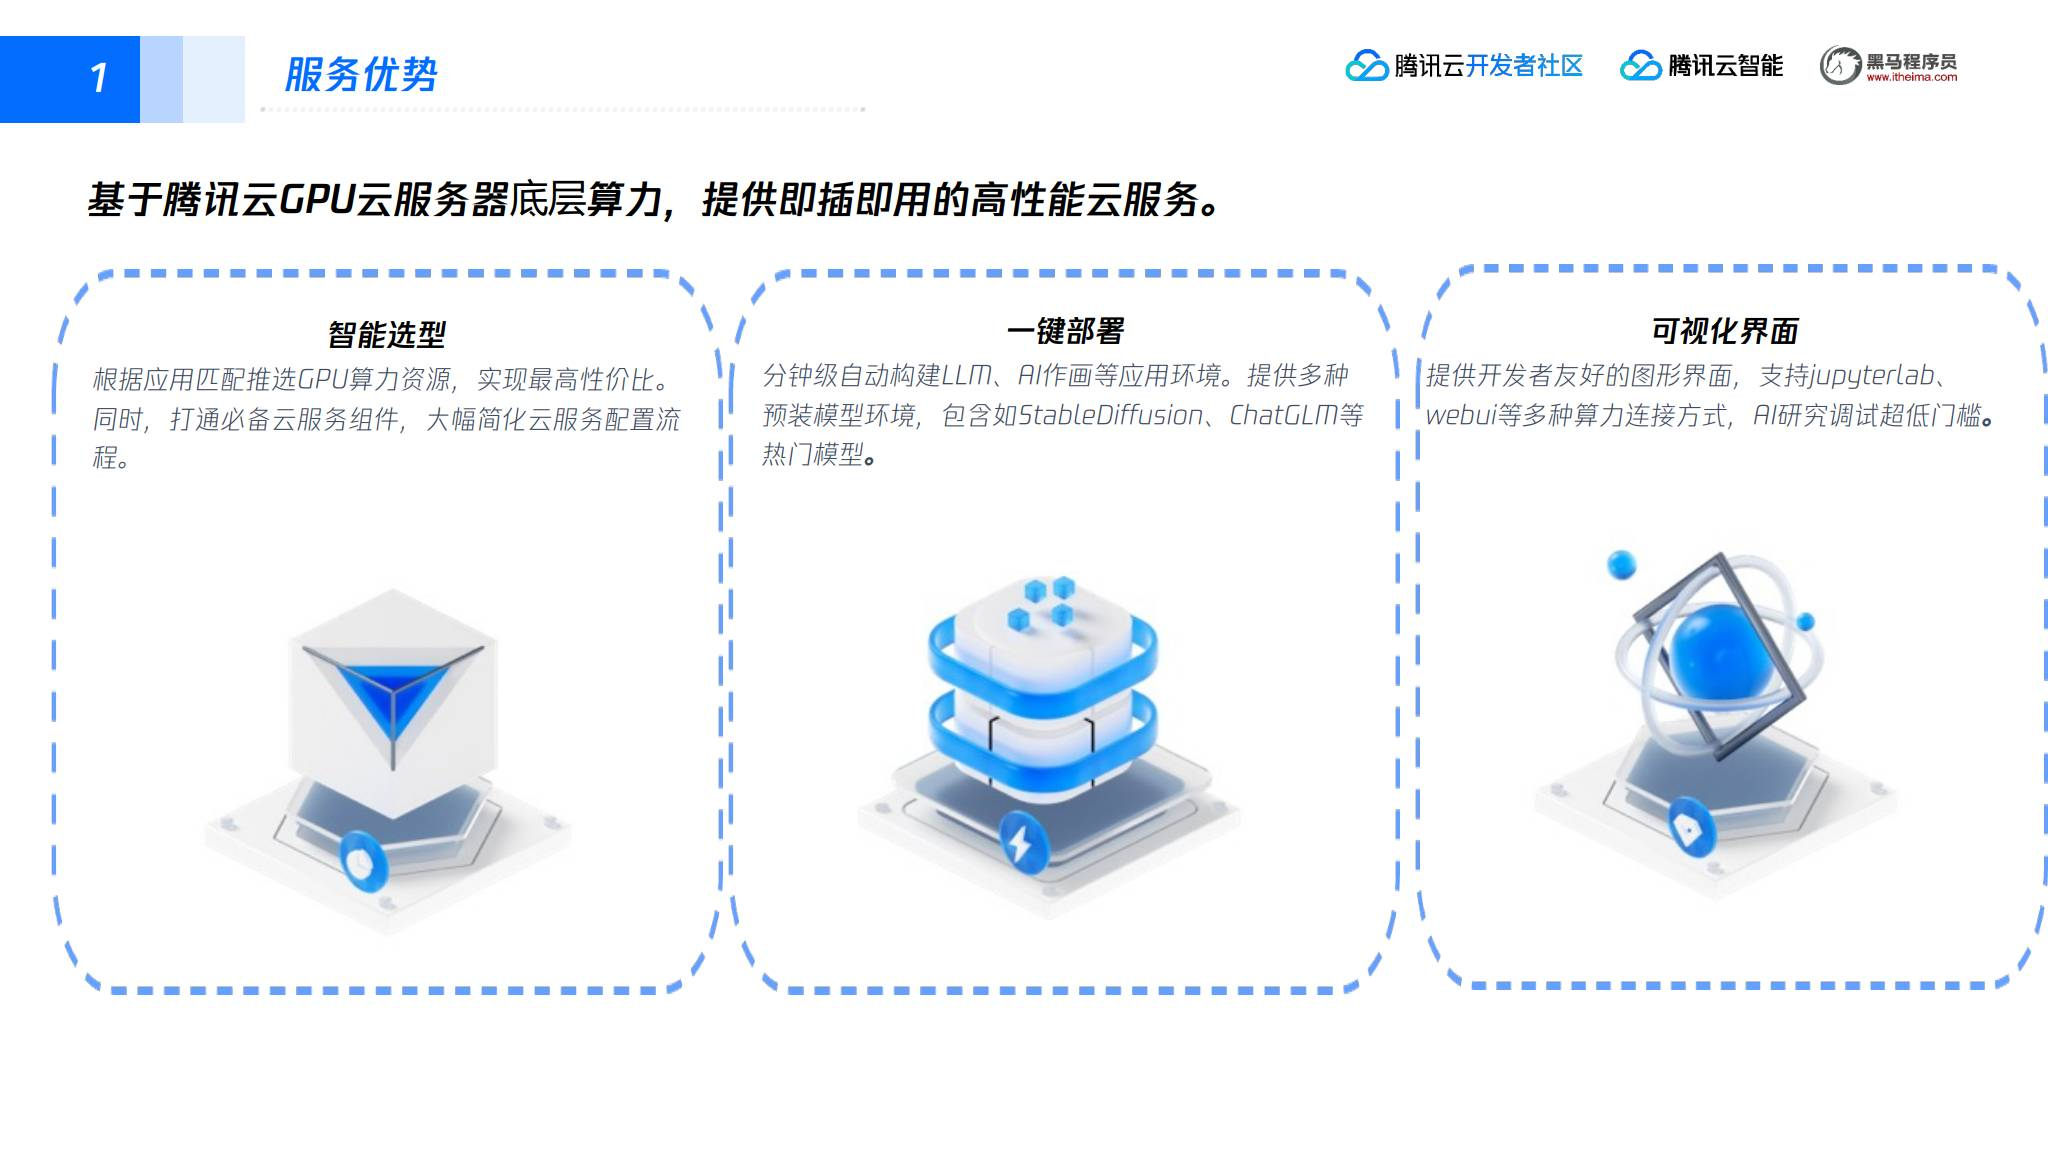

### 3. 应用场景

讲义列出三类典型场景：

- **AI 作画**：基于 Stable Diffusion 开源模型进行创作，覆盖数字媒体、游戏、动画、电影和广告。HAI 解决 GPU 选型、环境配置、模型安装、插件管理等问题。
- **AI 对话和写作**：部署开源大语言模型，创建 Agent 和企业知识库。
- **AI 开发和测试**：面向高校、研究所等科研场景，提供 GPU 资源以及公共模型和数据集存储。

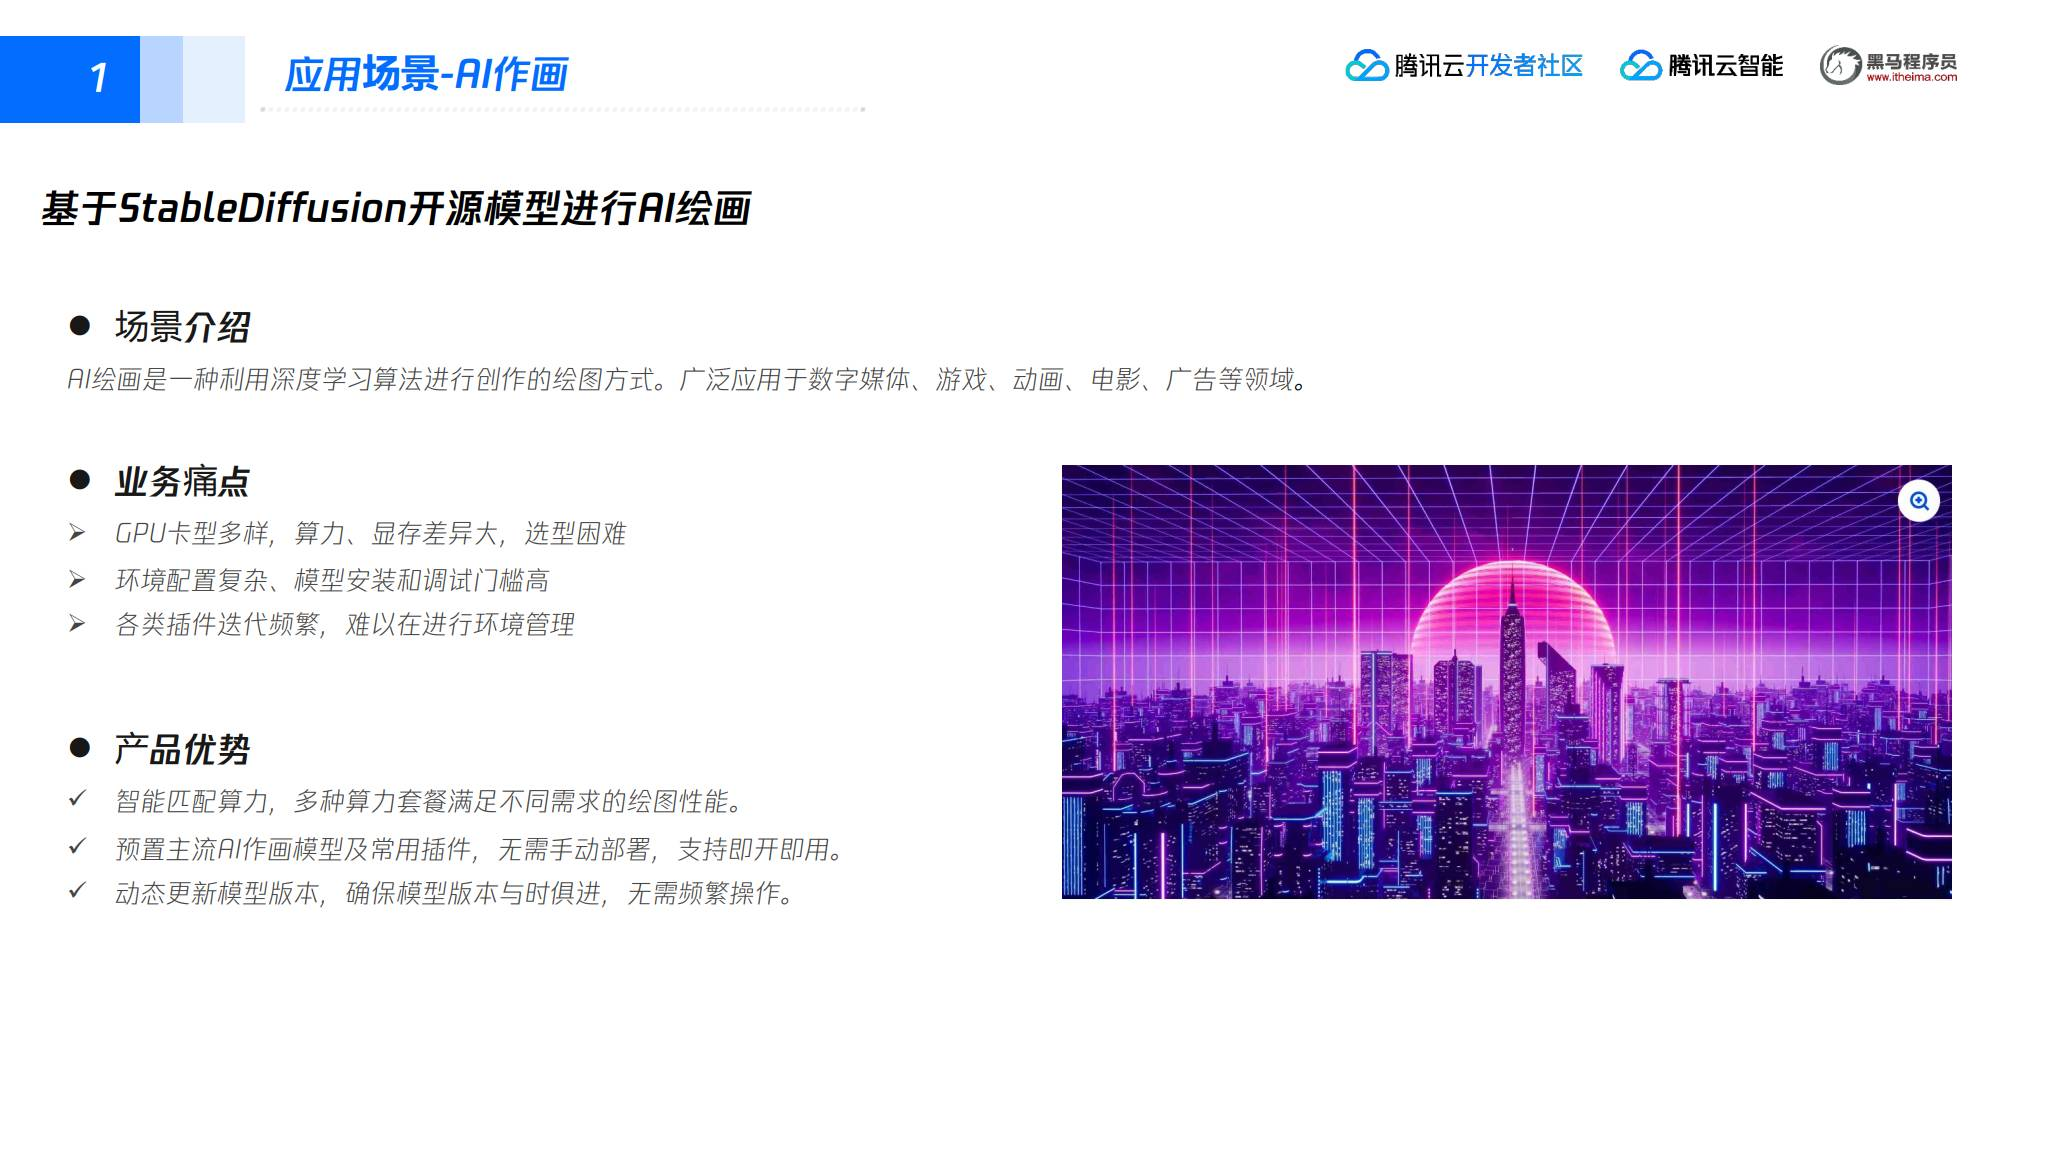

## 二、创建 Stable Diffusion 实例

### 1. 实例使用流程

课程给出的完整流程是：

1. 申请高性能应用服务 HAI；
2. 创建 Stable Diffusion AI 模型服务；
3. 启动 WebUI，进行图像生成和模型推理；
4. 使用 JupyterLab 进行 Stable Diffusion 训练；
5. 完成后销毁 Stable Diffusion AI 模型服务。

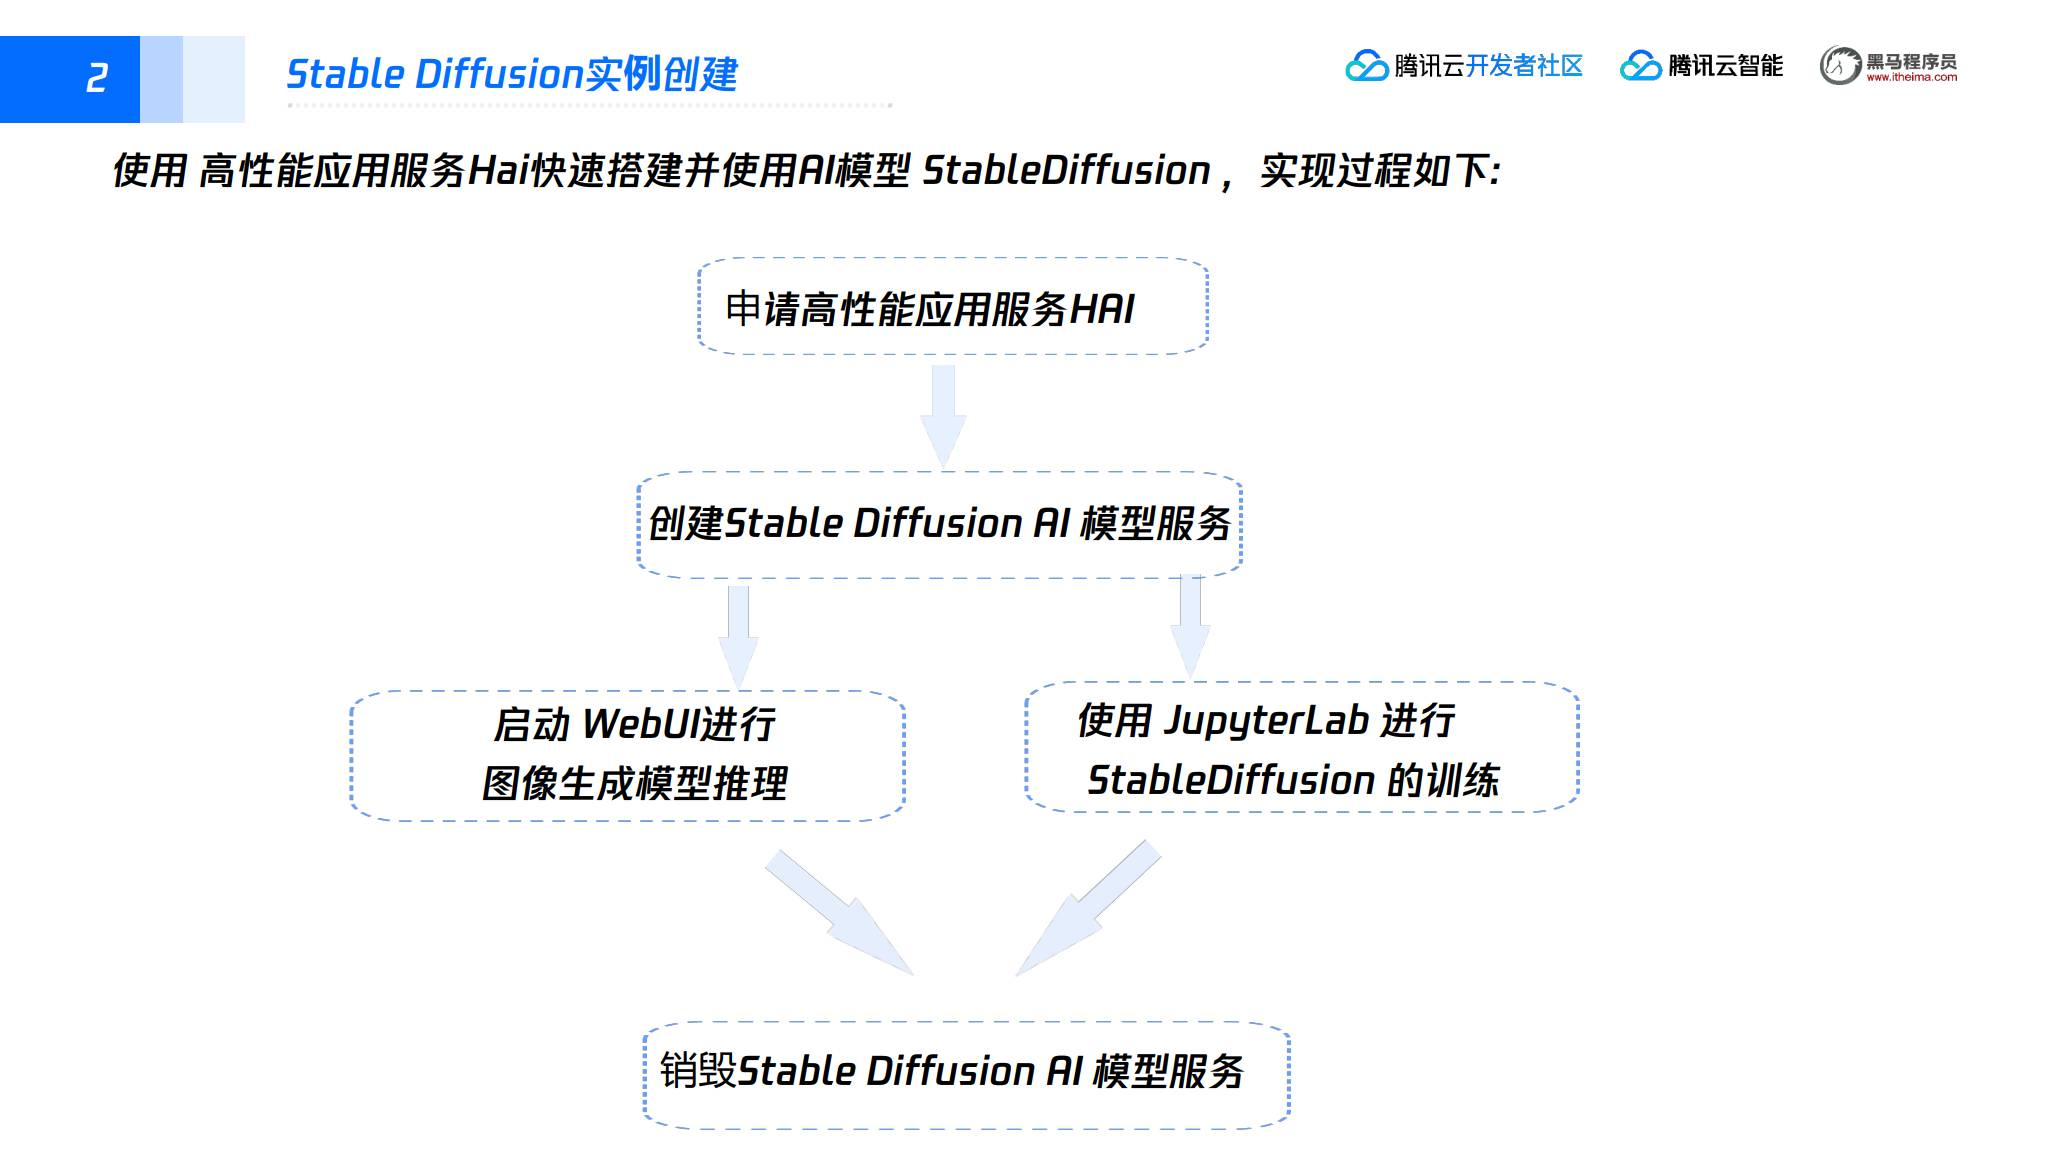

### 2. 创建服务和查看实例

在 HAI 控制台中，课程操作顺序是：

1. 进入高性能应用服务 HAI，点击“立即使用”；
2. 登录 HAI 控制台，点击“新建”；
3. 配置服务器信息并创建实例；
4. 创建完成后查看实例状态和详细信息。

课程资料中的具体配置界面以截图为准，实际可选的 GPU 和服务规格以平台当前页面为准。

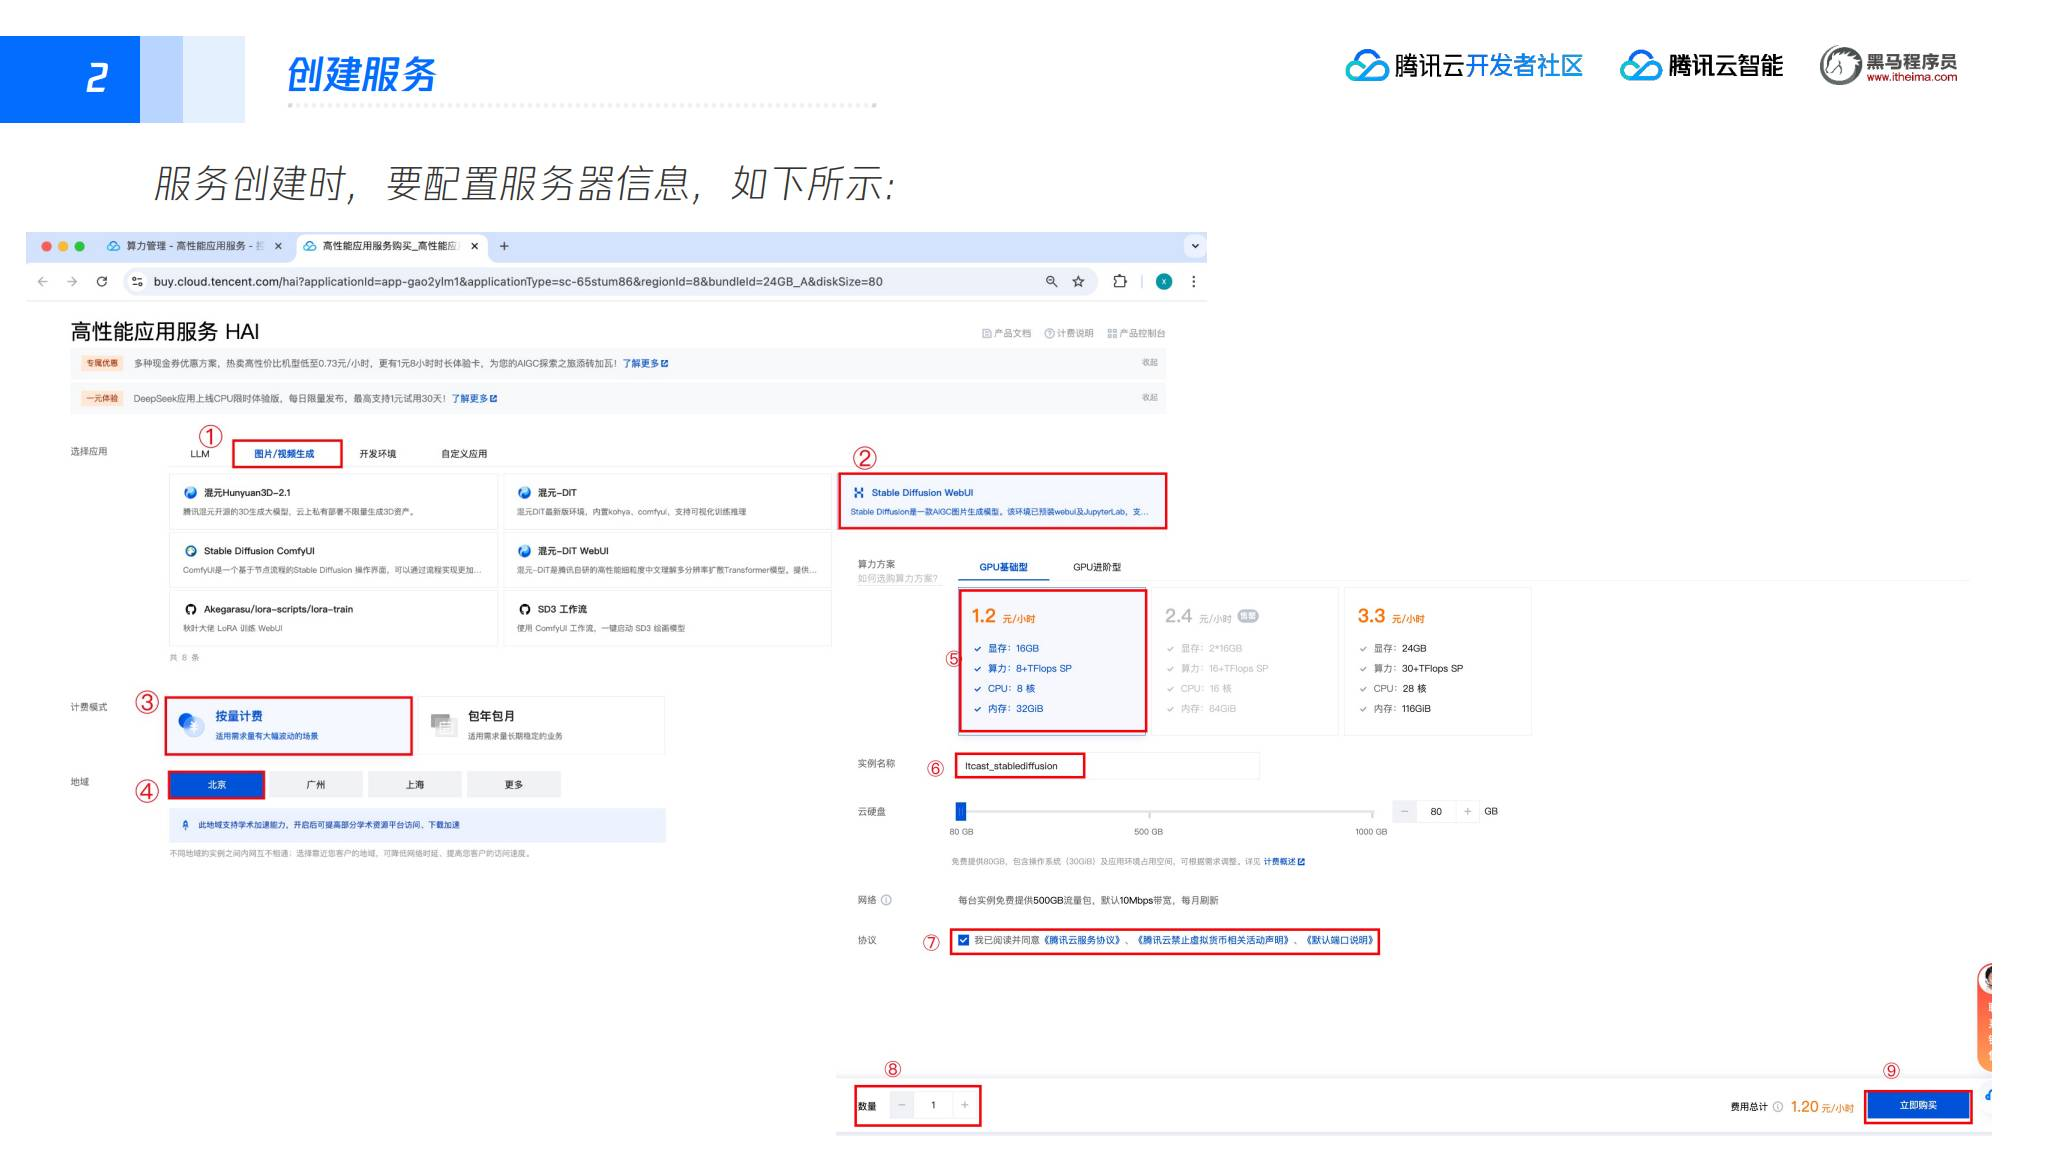

截图中的服务选项顺序为“图片/视频生成 → Stable Diffusion WebUI → 按量计费 → 地域 → 算力方案 → 实例名称 → 协议和数量 → 创建”。示例实例名称为 `Itcast_stablediffusion`，配置展示 16GB 显存、8 核 CPU、32GiB 内存、80GB 云硬盘。

这张部署截图用于介绍 WebUI 实例创建；后面的 DreamBooth 实验标注显存需要 24GB 以上，做训练时应按实验要求选择资源。实例创建成功后，列表应显示“运行中”；实例详情可查看应用、配置环境和连接入口。

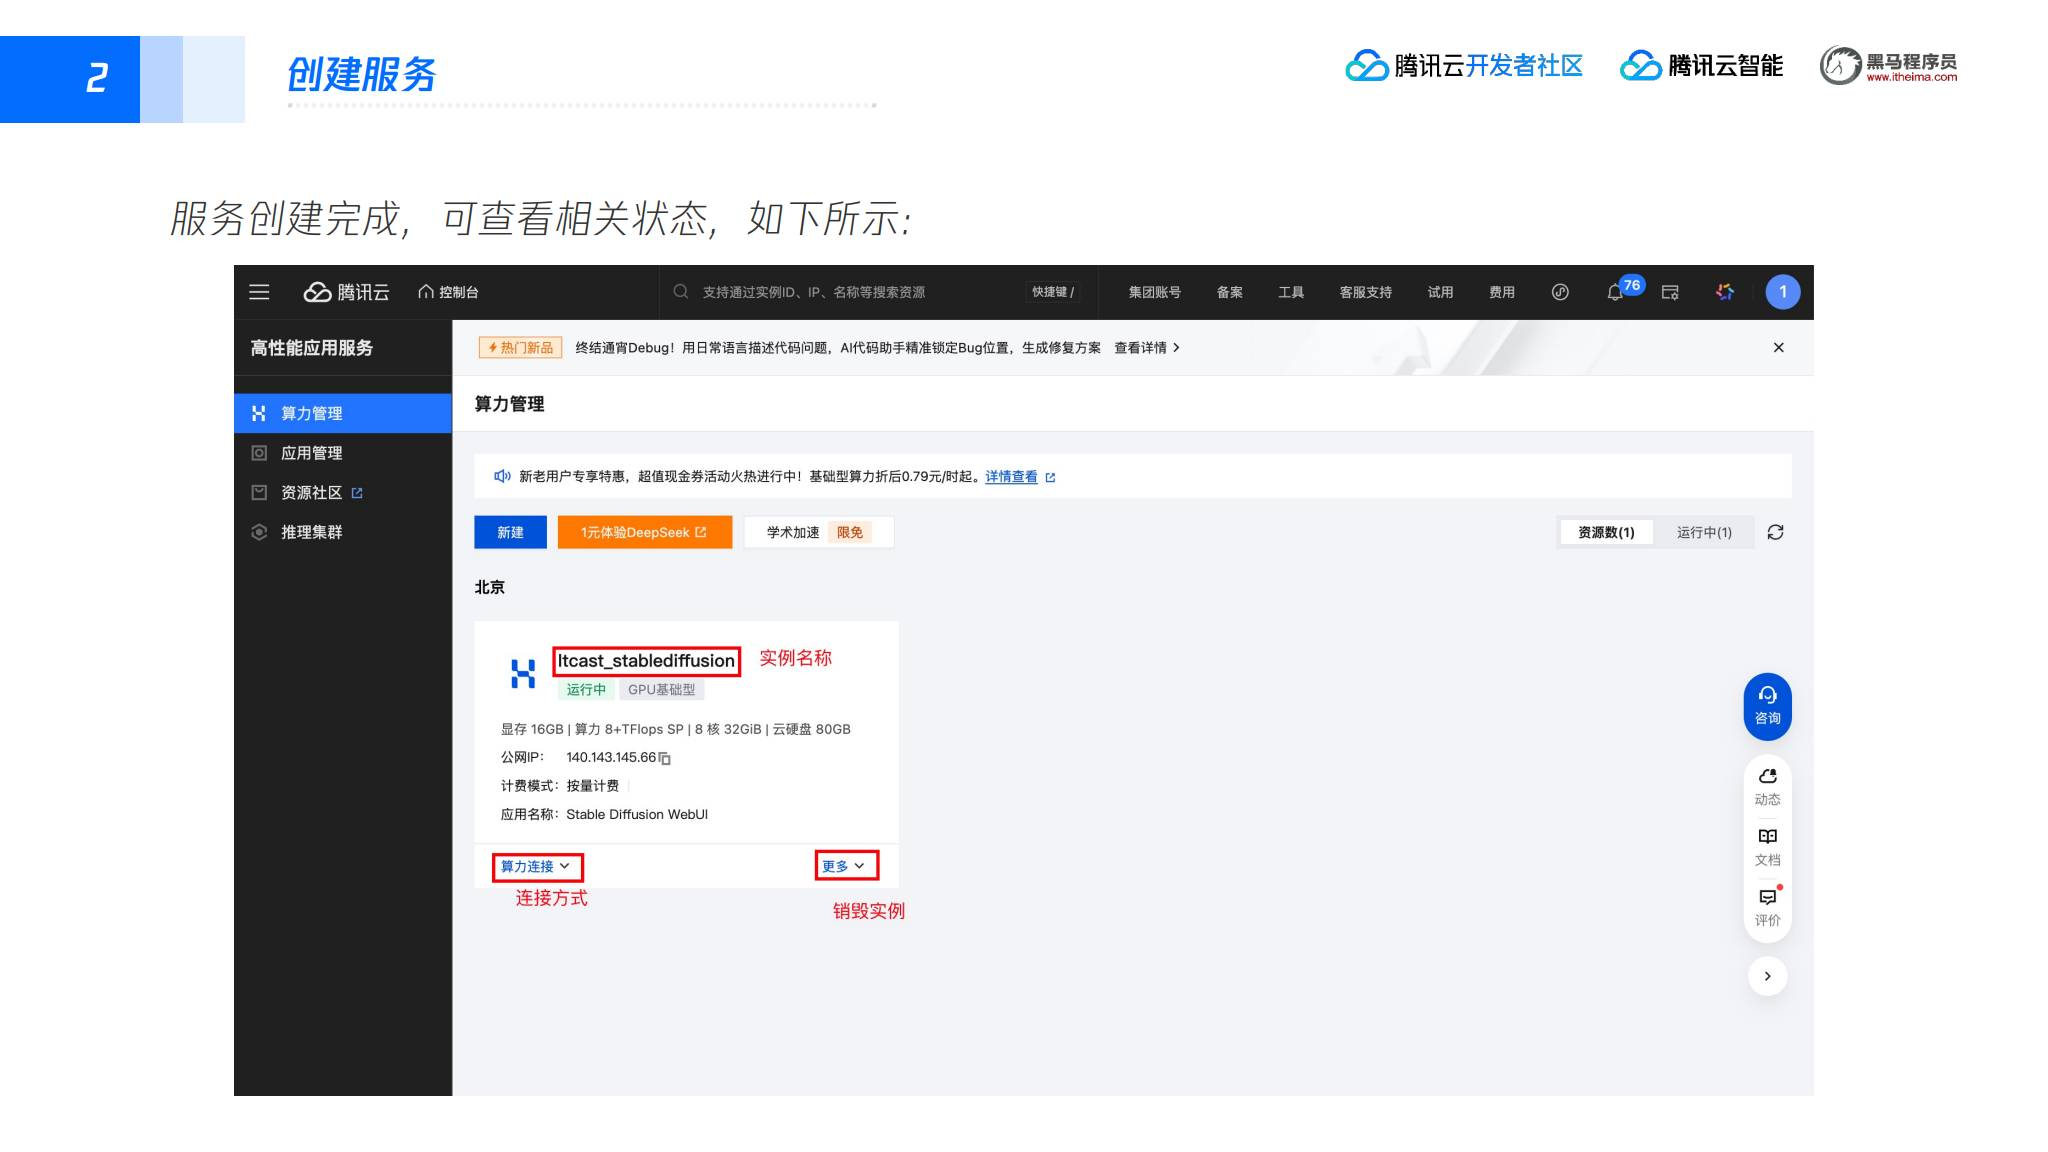

### 3. WebUI 与 JupyterLab

- **WebUI**：用于直接进行 Stable Diffusion 推理和生成图像，课程展示了进入 WebUI 的两种入口和生成图像的界面。
- **JupyterLab**：用于训练 DreamBooth、LoRA 等模型，使用方式与云服务器上的 JupyterLab 类似。

课程建议在开始使用前安装 Python、Git 和 CUDA 等前置应用，以减少报错并提高下载速度。

两种入口对应同一个服务：

1. 在实例列表的“算力连接”菜单中选择 `Gradio WebUI` 或 `JupyterLab`。
2. 点击实例名称进入详情，在右侧“连接算力”面板选择相应入口。

WebUI 成功打开后应看到文生图、提示词和生成按钮；JupyterLab 成功打开后应看到文件浏览器、Notebook 和终端等工作区域。Python 用于运行训练程序，Git 用于获取和更新代码，CUDA 用于 NVIDIA GPU 计算。

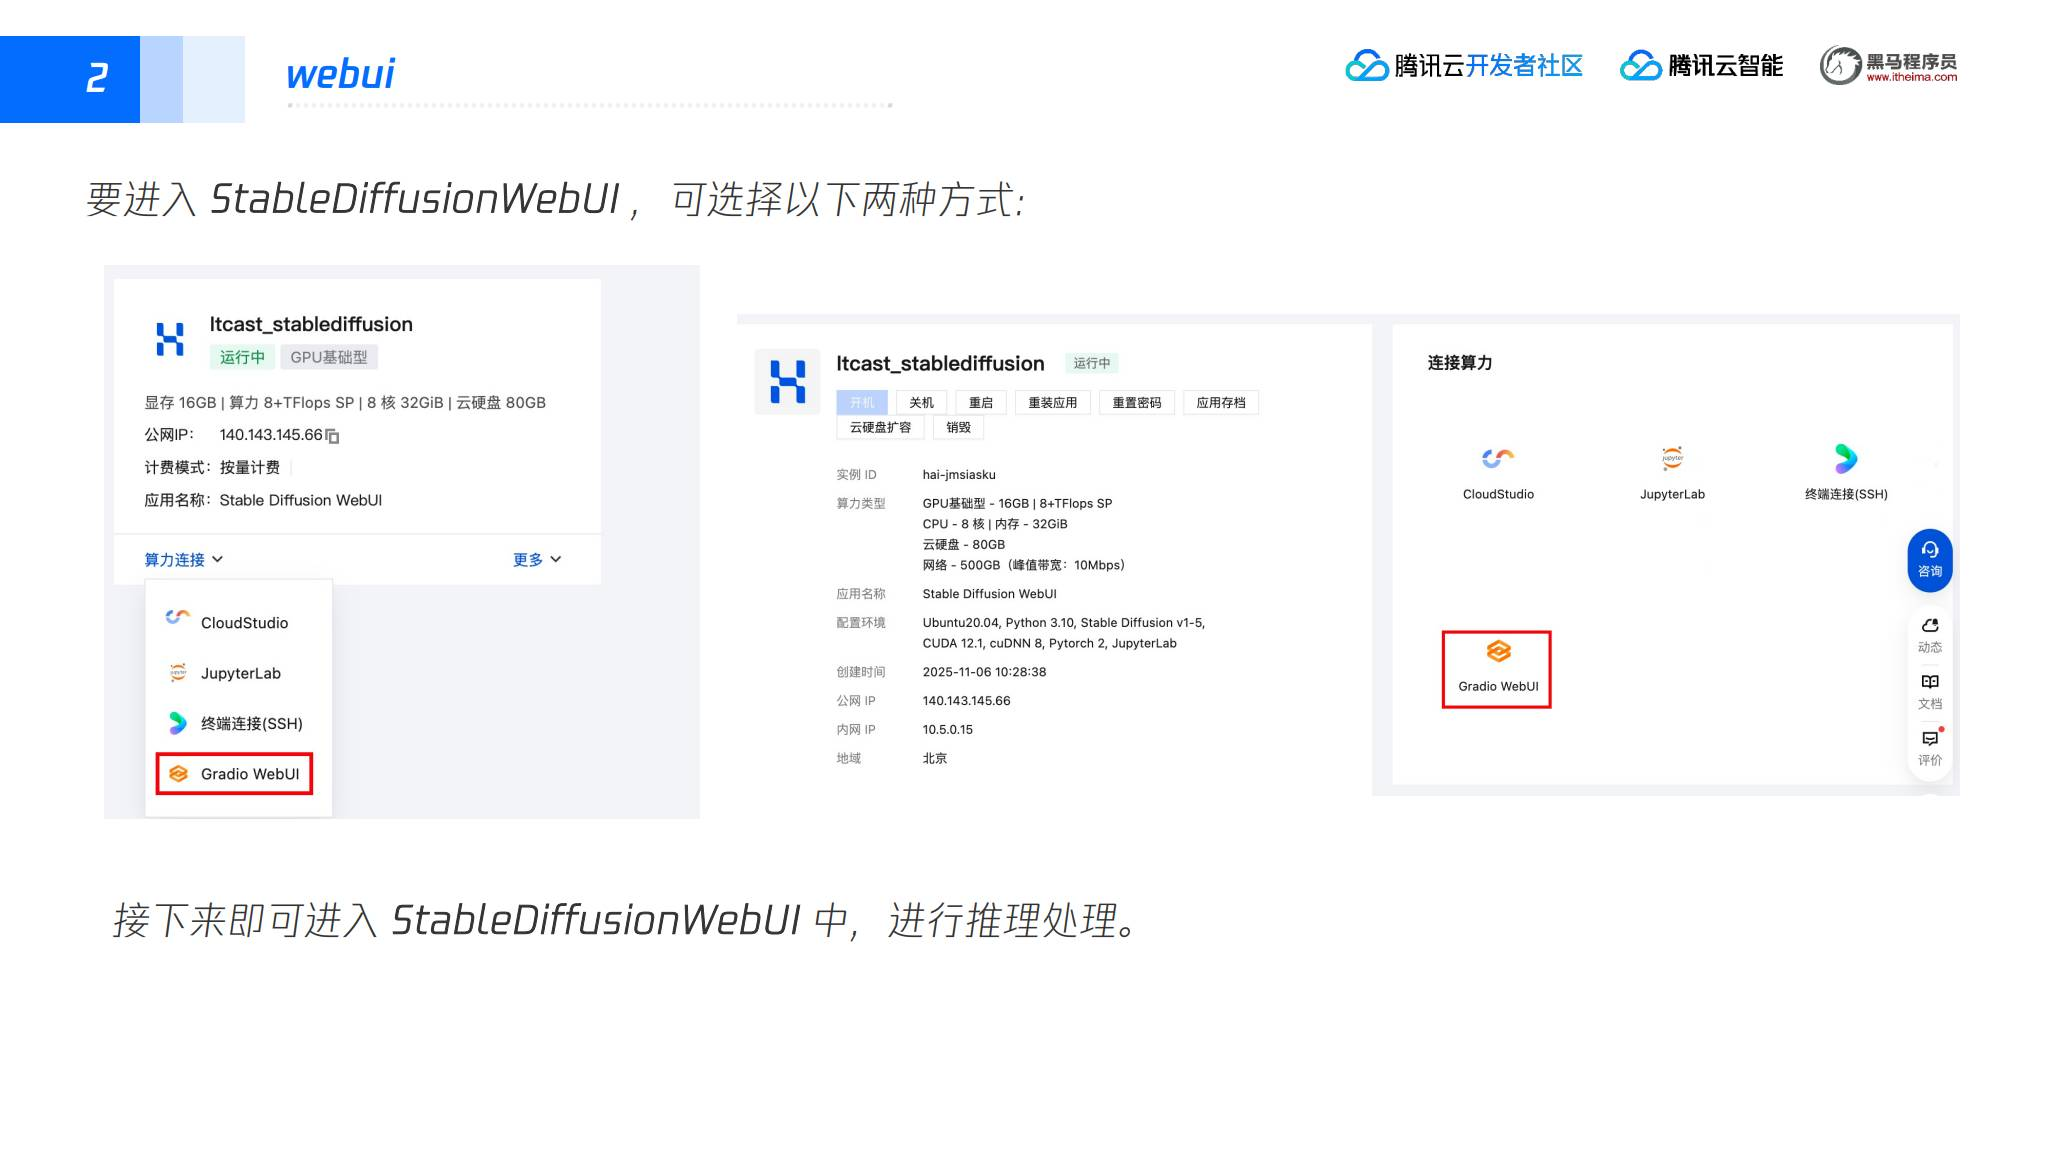

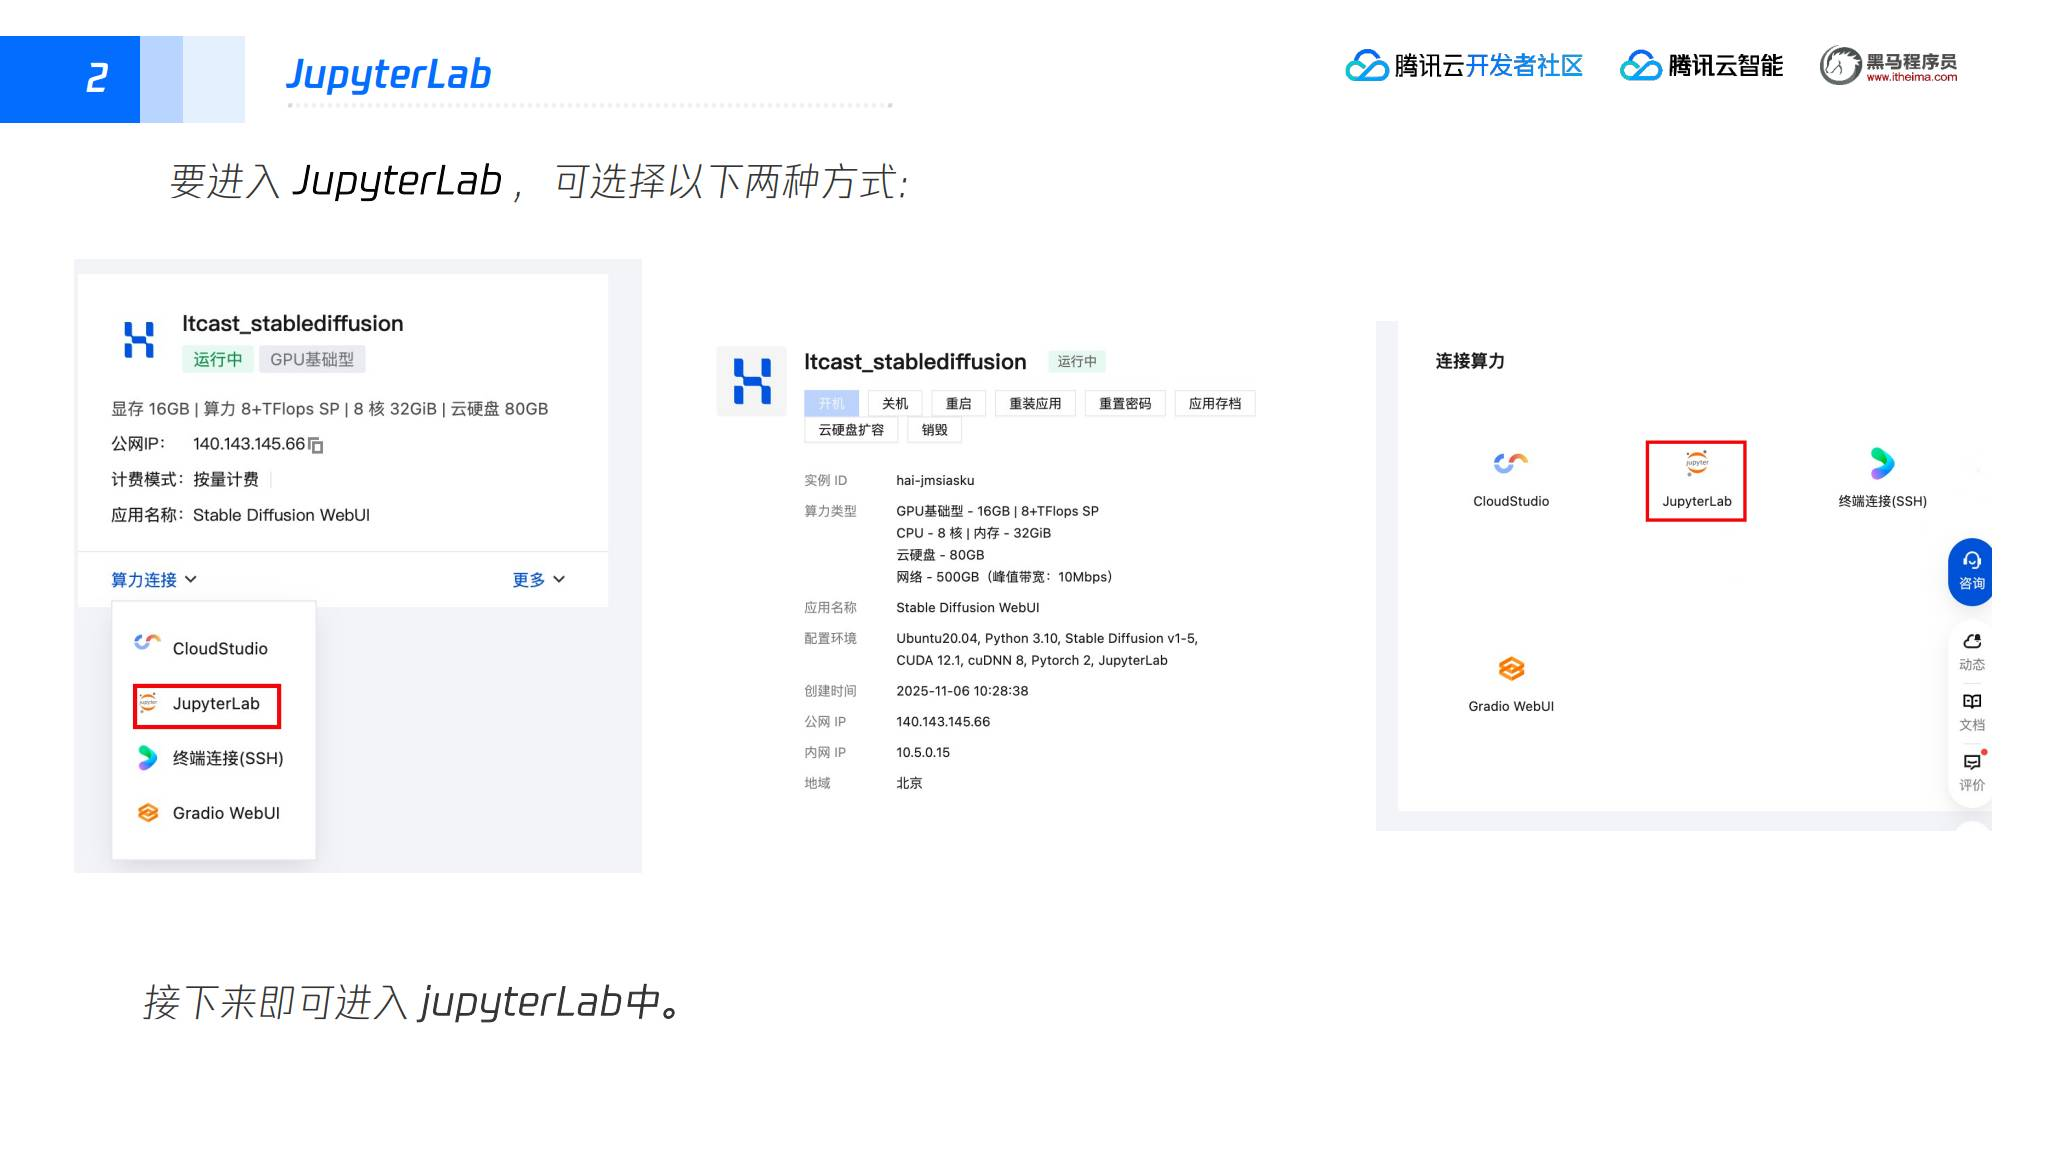

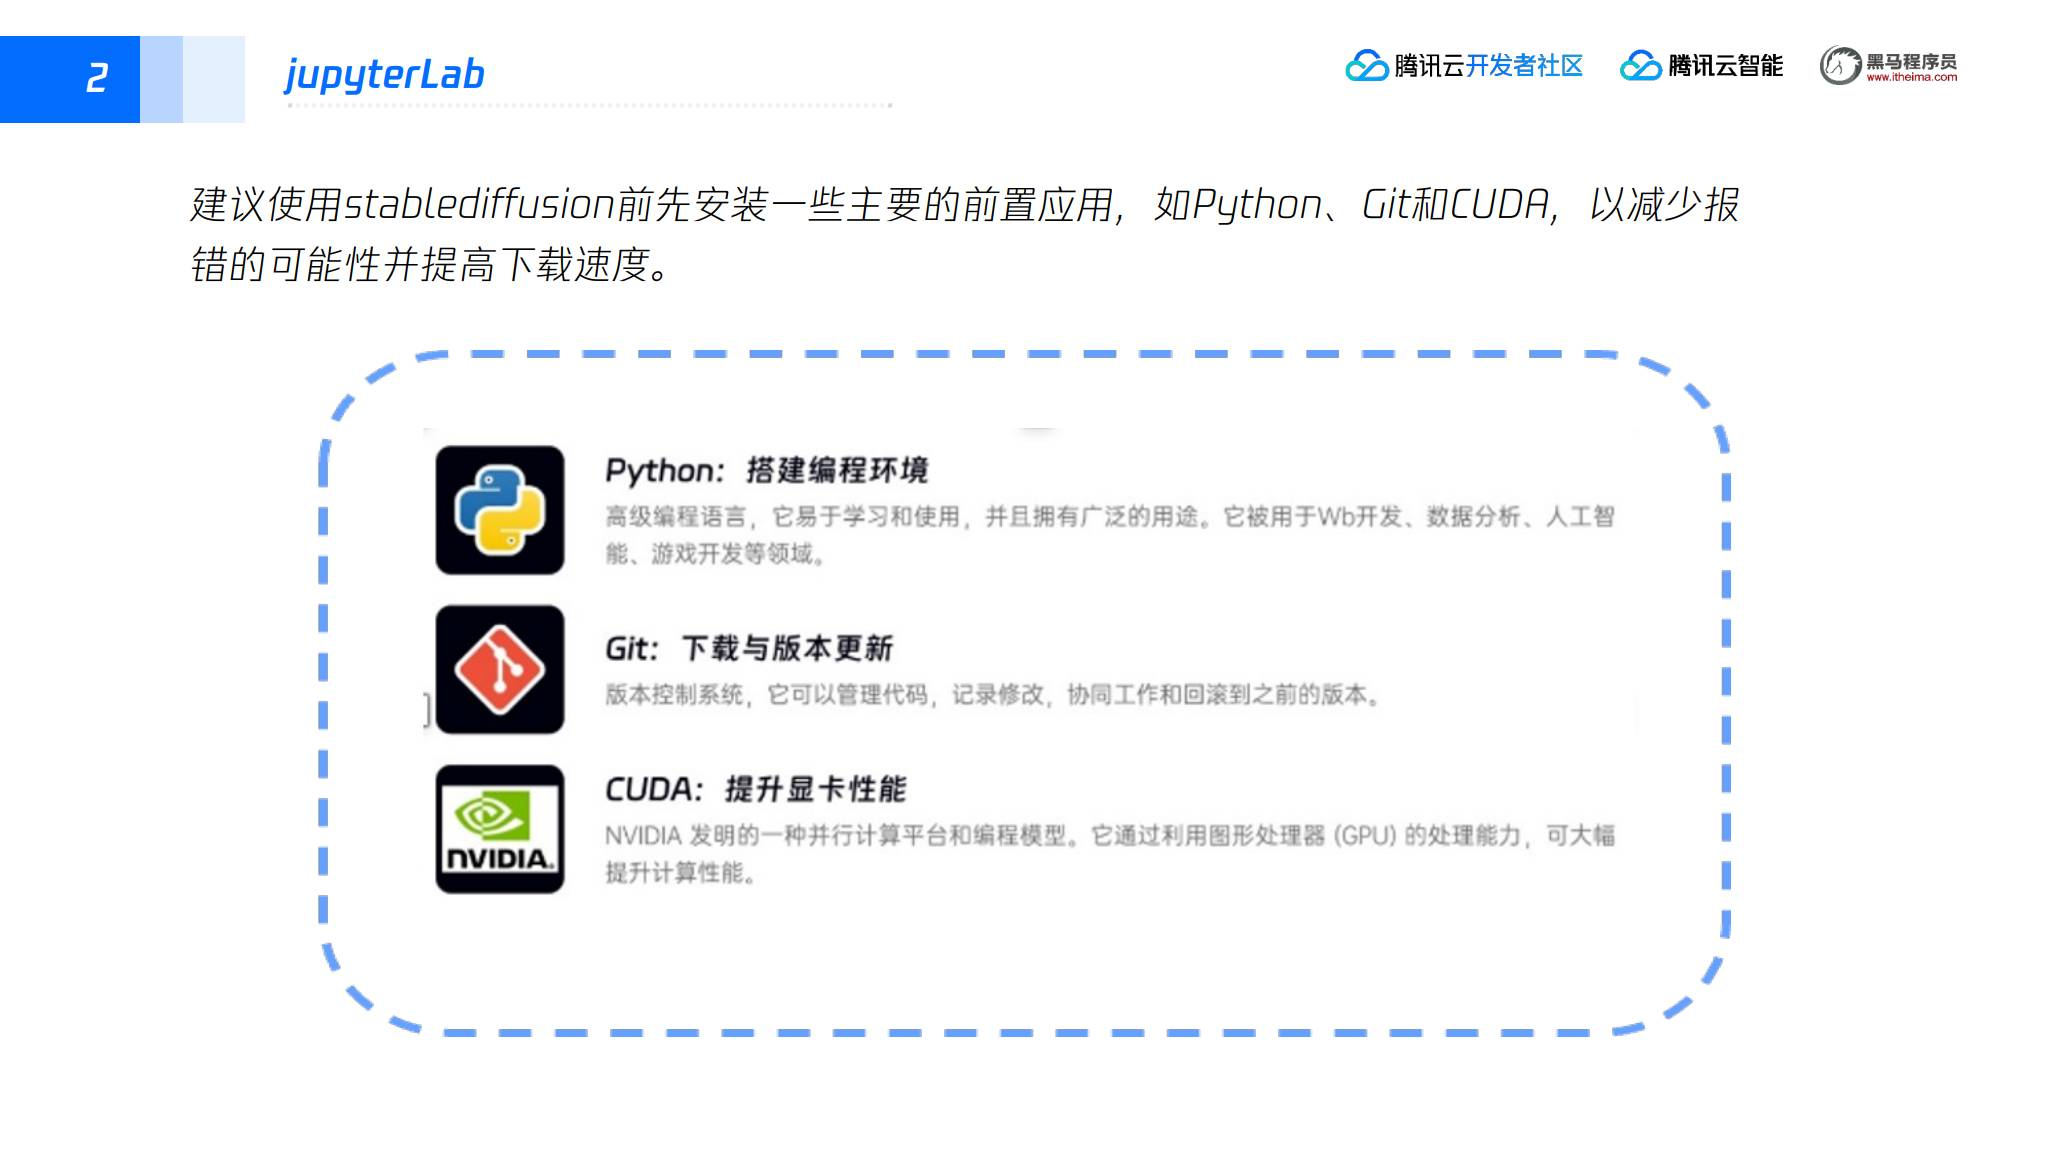

### 4. 使用结束后的实例销毁

课程在实例列表“更多”菜单和详情页展示了“销毁”入口，形成“创建 → 推理或训练 → 销毁”的使用流程。销毁前先保留需要的模型权重和生成结果。这里记录课程操作步骤，不在本机或云平台执行销毁。

## 三、Stable Diffusion 的训练方法

讲义列出四种训练方式：

| 方法 | 作用 | 特点 |
| --- | --- | --- |
| Textual Inversion | 使用文本提示训练模型，根据模型从给定图像中选择最匹配的结果 | 对计算资源要求较低，适合快速生成大量高质量图像 |
| Hypernetwork | 从模型内部找到更多相似内容，使生成结果接近目标内容 | 通常用于训练艺术风格 |
| DreamBooth | 用少量图像微调文本生成图像模型 | 可以把一组图像中的主体或风格迁移到新图像 |
| LoRA | 用少量图像训练，只修改网络中的部分参数 | 训练更快，模型大小适中，资源需求较小 |

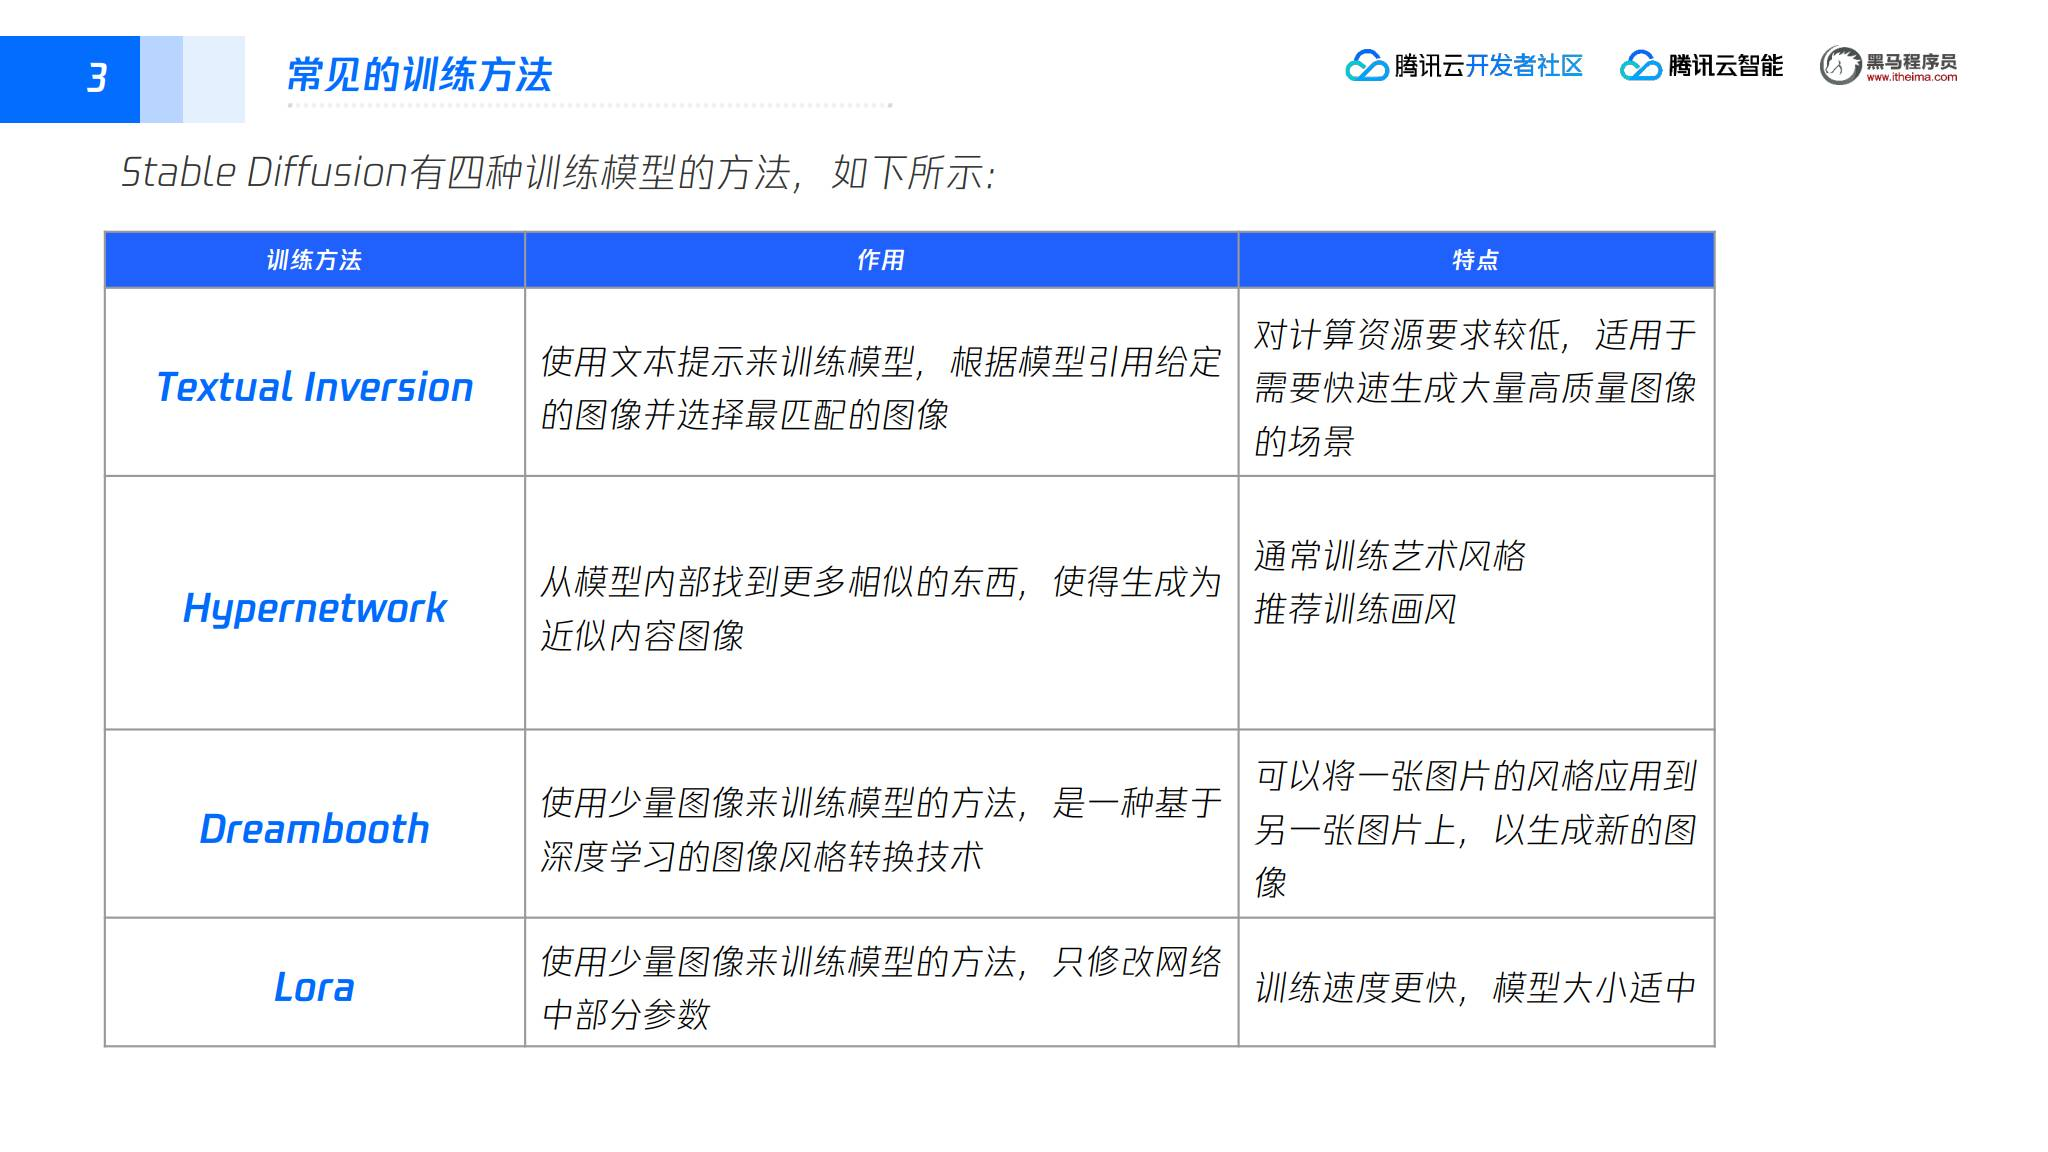

## 四、DreamBooth 训练

### 1. DreamBooth 的思路

DreamBooth 主要对文本生成图片模型进行微调。用户只需要准备少量个性化图片，例如个人照片或宠物照片，就可以训练专属模型。

课程示例先定义一个专属 prompt，例如 `a [V] dog`，其中 `[V]` 是一个罕见、没有既定含义的符号组合。训练时：

1. 文本编码器提取专属 prompt 的文本特征；
2. 图像编码器提取训练图片的特征；
3. 将文本特征和图像特征作为扩散模型输入进行训练；
4. 推理时输入包含该关键词的 prompt，生成对应主体或风格的图片。

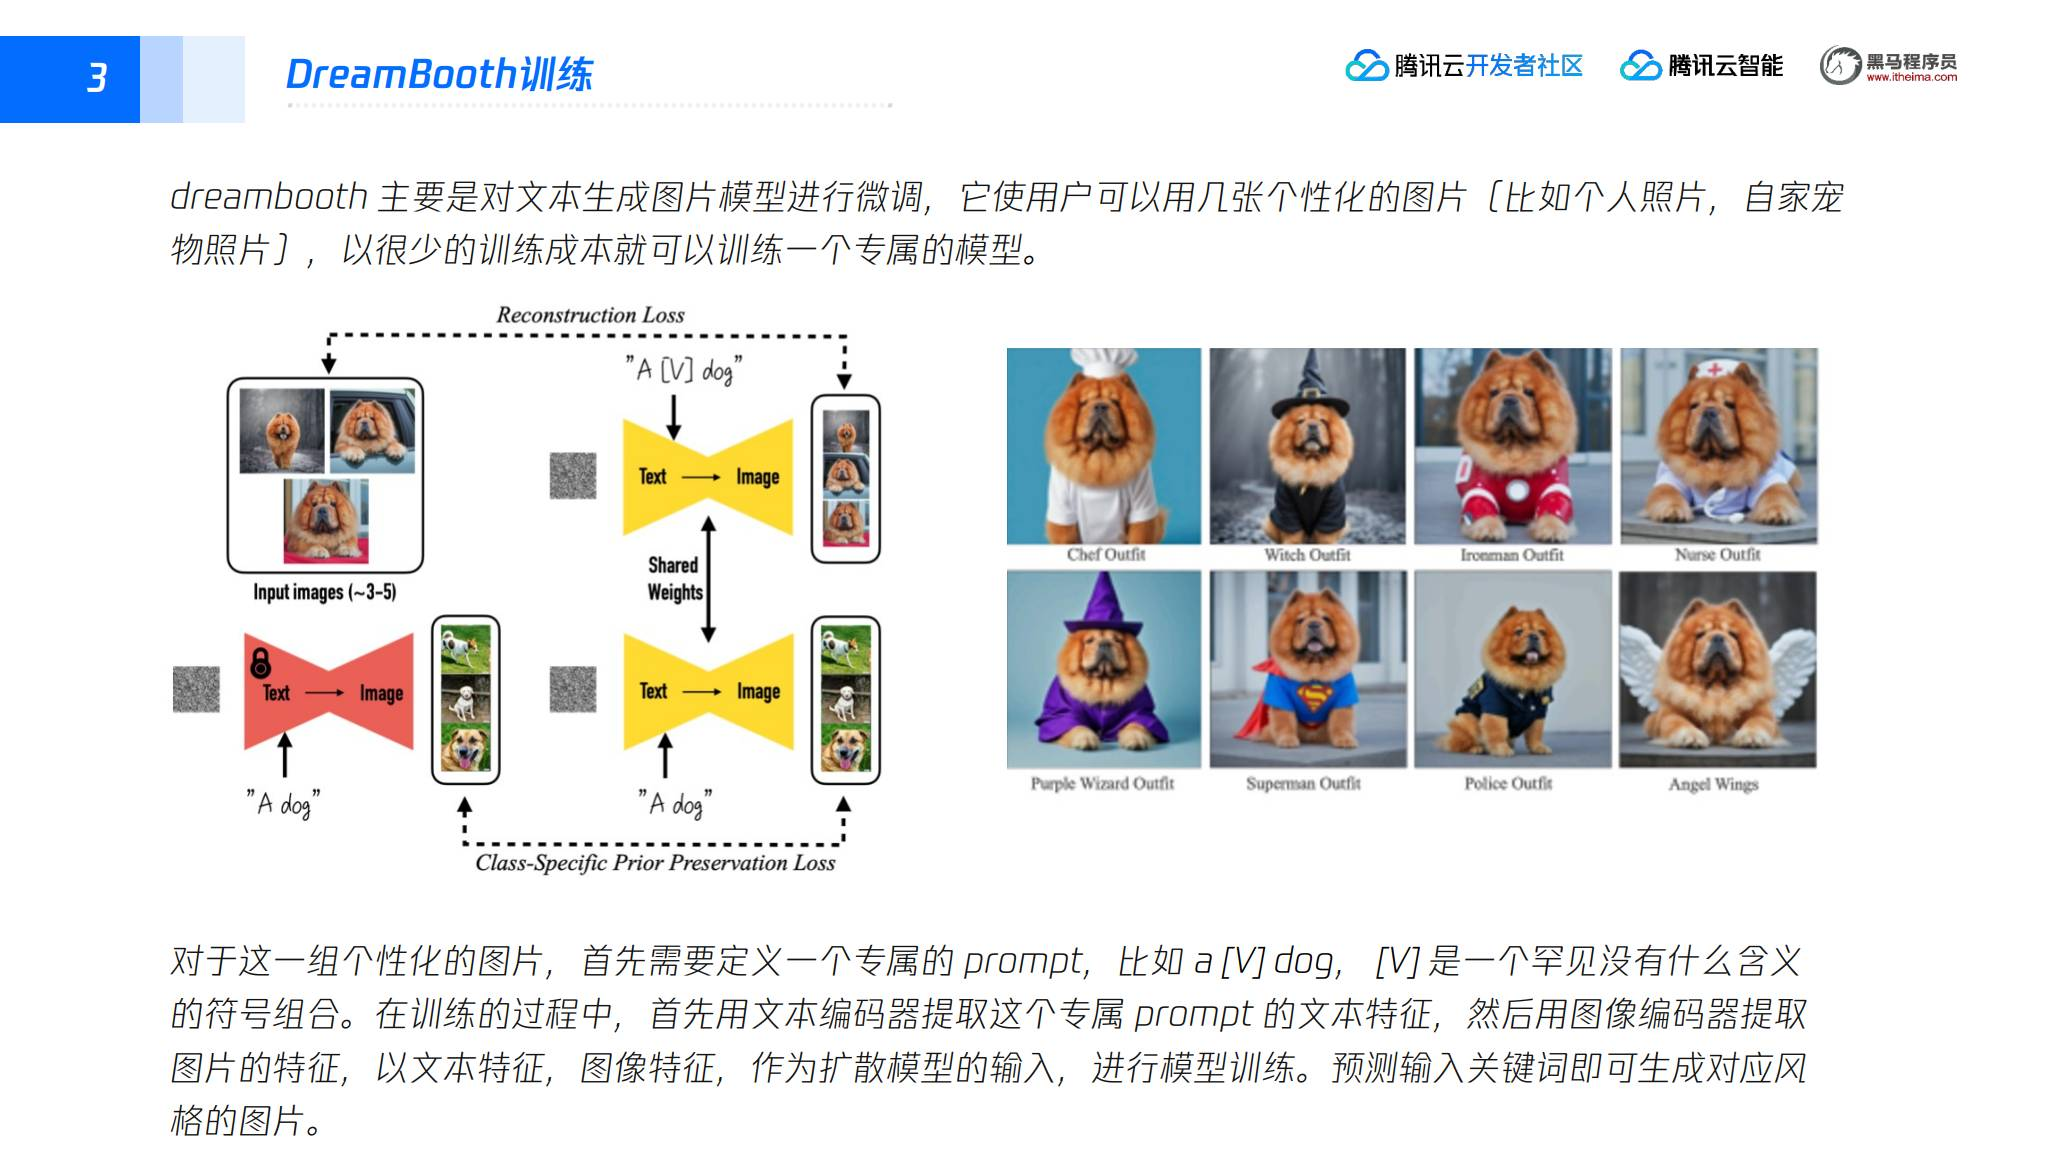

### 2. 实验环境和数据

课程实验基于开源 `diffusers` 代码，在 HAI 的 JupyterLab 中实现，讲义标注显存需要 **24GB 以上**。

格子衫示例数据集包含 **103 张**图片。图片统一处理为 `512×512`，并尽量覆盖不同环境、灯光、发型、表情、姿势和角度，放入训练图片目录。正文写作 `train_images`，目录图和后续 `INSTANCE_DIR` 配置使用 `train-images`；实际目录应与 `INSTANCE_DIR` 完全一致。

DreamBooth 项目各目录的用途如下，Notebook 的工作目录应为项目根目录：

| 文件或目录 | 课程用途 |
| --- | --- |
| `diffusers/` | 开源代码 |
| `generate-images/` | 自动生成的类别图片 |
| `train-images/` | 格子衫训练图片 |
| `weights-sd/`、`weights-hf/` | 源模型及转换后的模型权重 |
| `result/` | 训练输出 |
| `scripts/` | 项目脚本目录 |
| `accelerate.sh` | 写入 Accelerate 配置 |
| `back_convert.py`、`back_convert_alt.py`、`convert_sd2hf.py` | 模型格式转换相关脚本 |
| `dreambooth-gezishan.ipynb` | 训练流程入口 |

目录图列出的转换脚本与后文 `CONVERTER = "convert_v3.py"` 不同，使用配套代码时要核对实际文件；不应仅凭目录图重命名脚本。

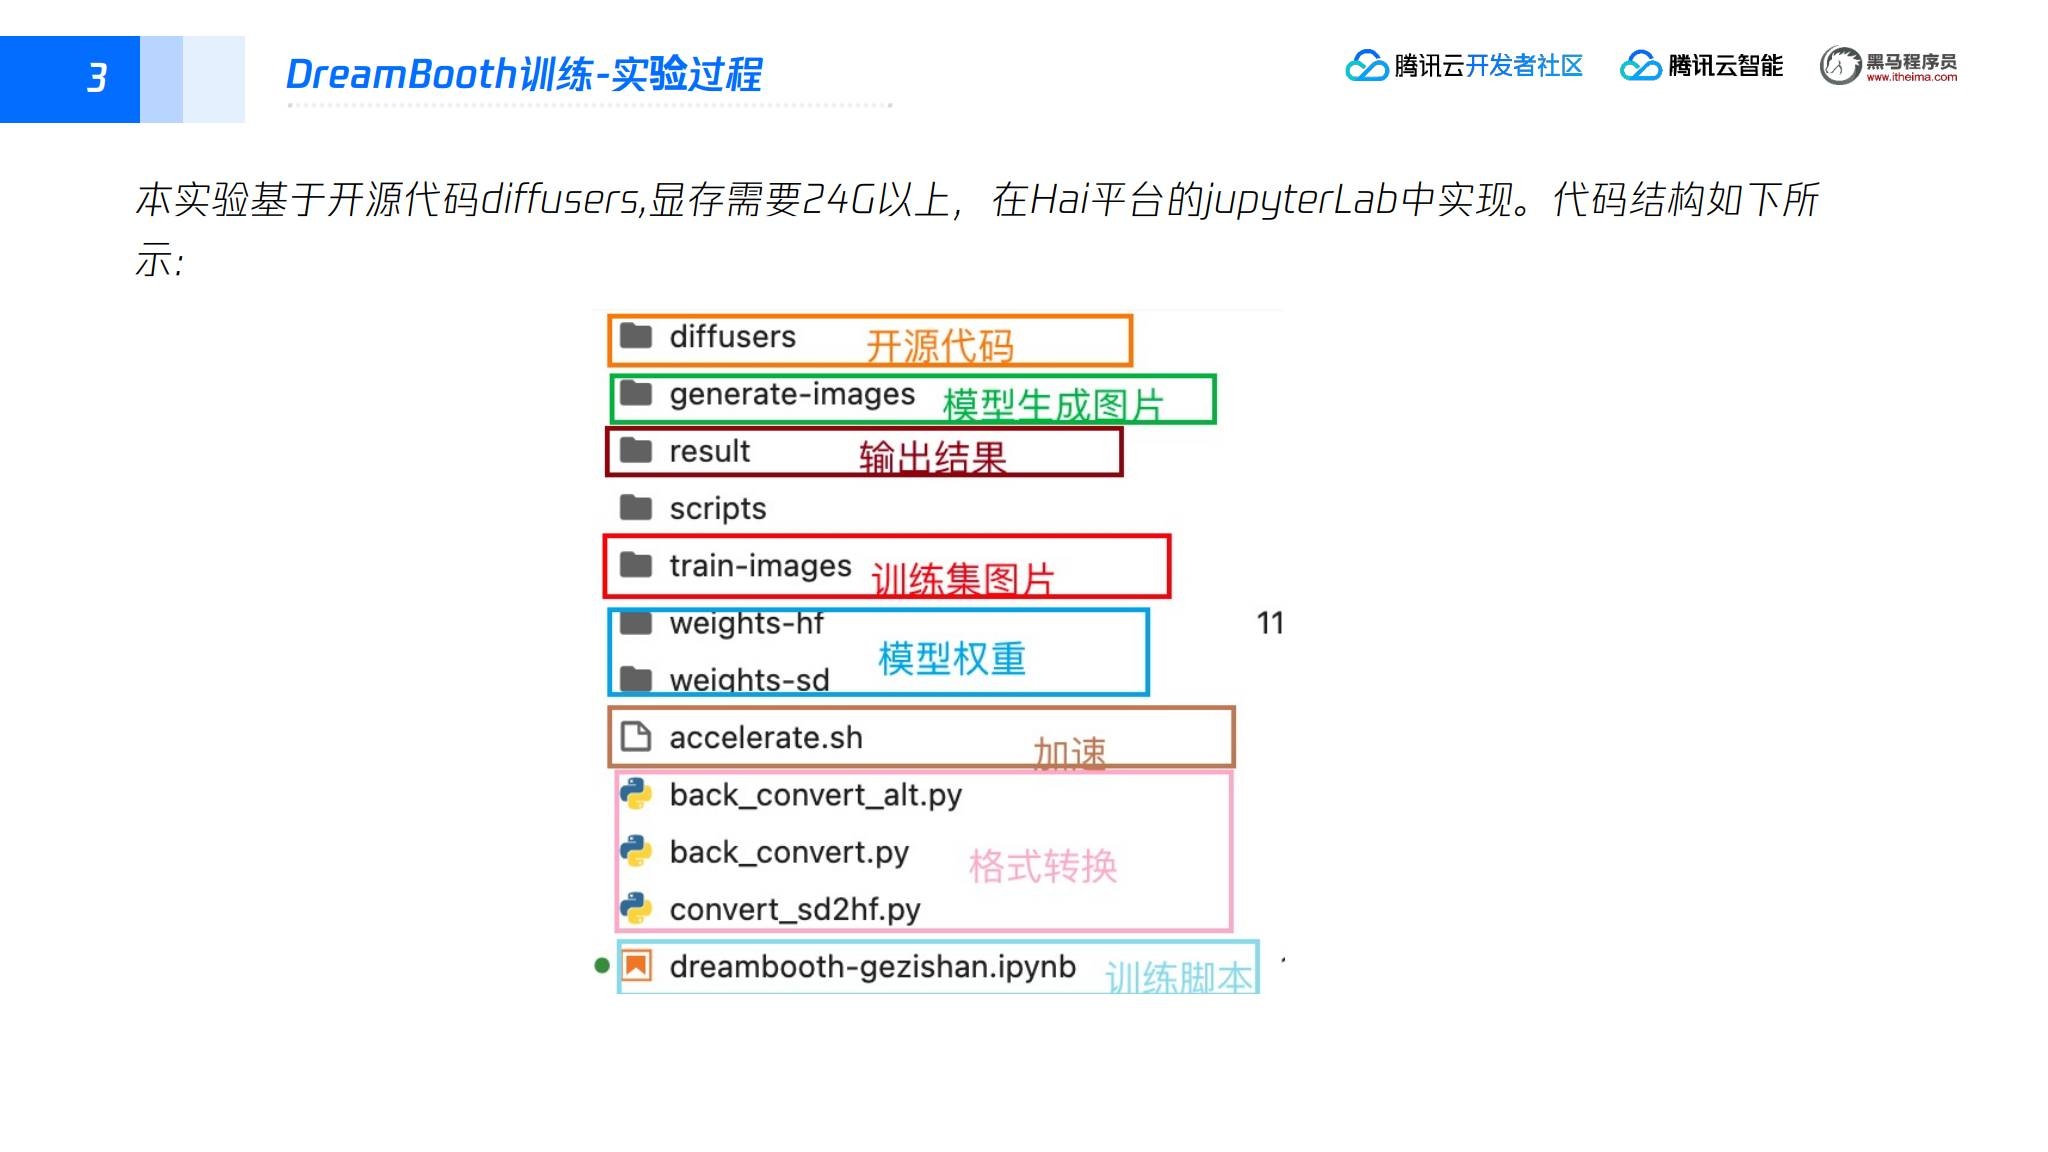

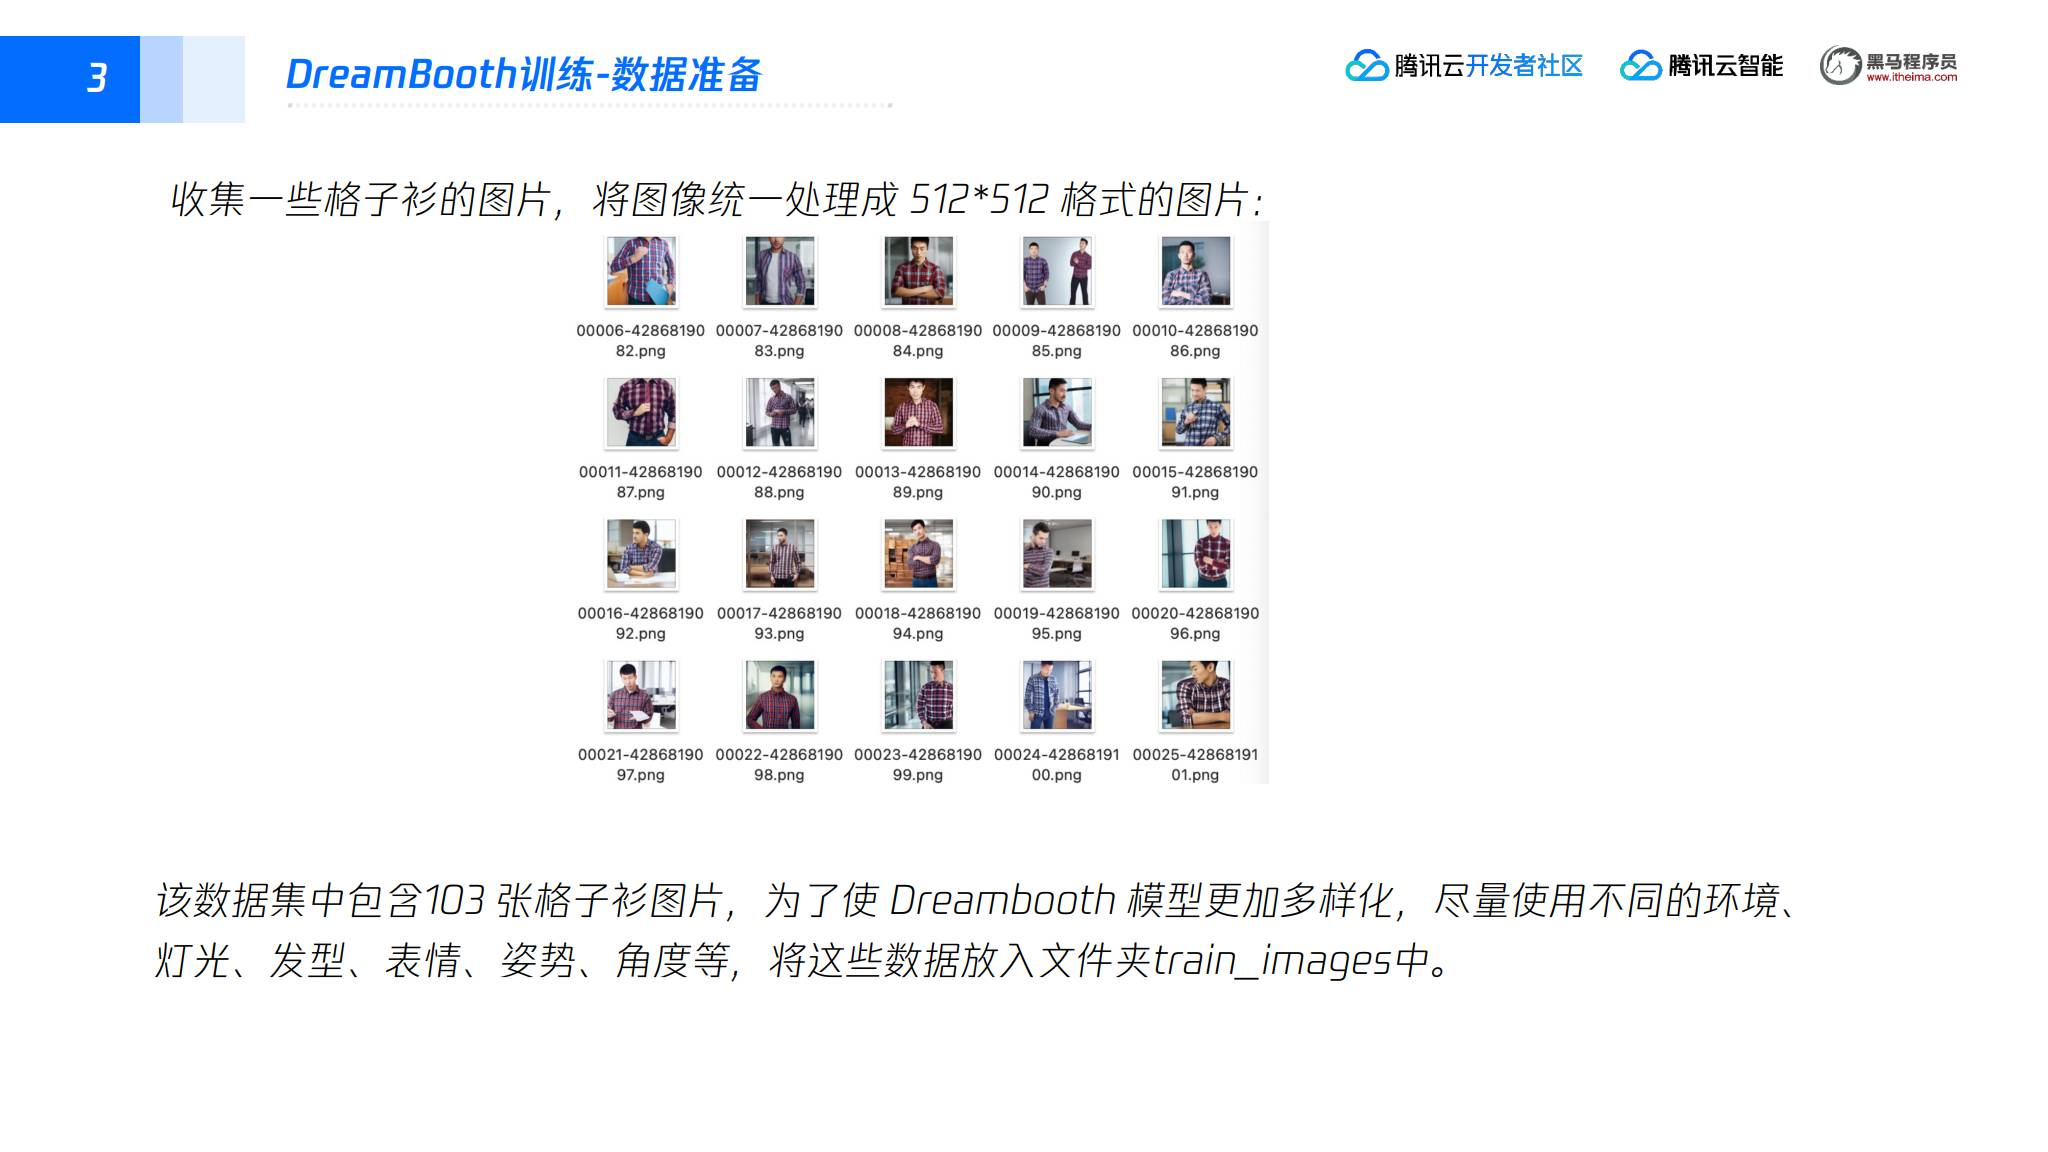

### 3. 训练配置的关键概念

课程在 `dreambooth-gezishan.ipynb` 中依次完成：

- 设置全局变量；
- 将源模型转换为 `diffusers` 模型格式；
- 配置训练 prompt；
- 配置加速器；
- 设置训练参数并启动训练；
- 保存训练权重，并转换为可在 WebUI 使用的 `ckpt` 格式。

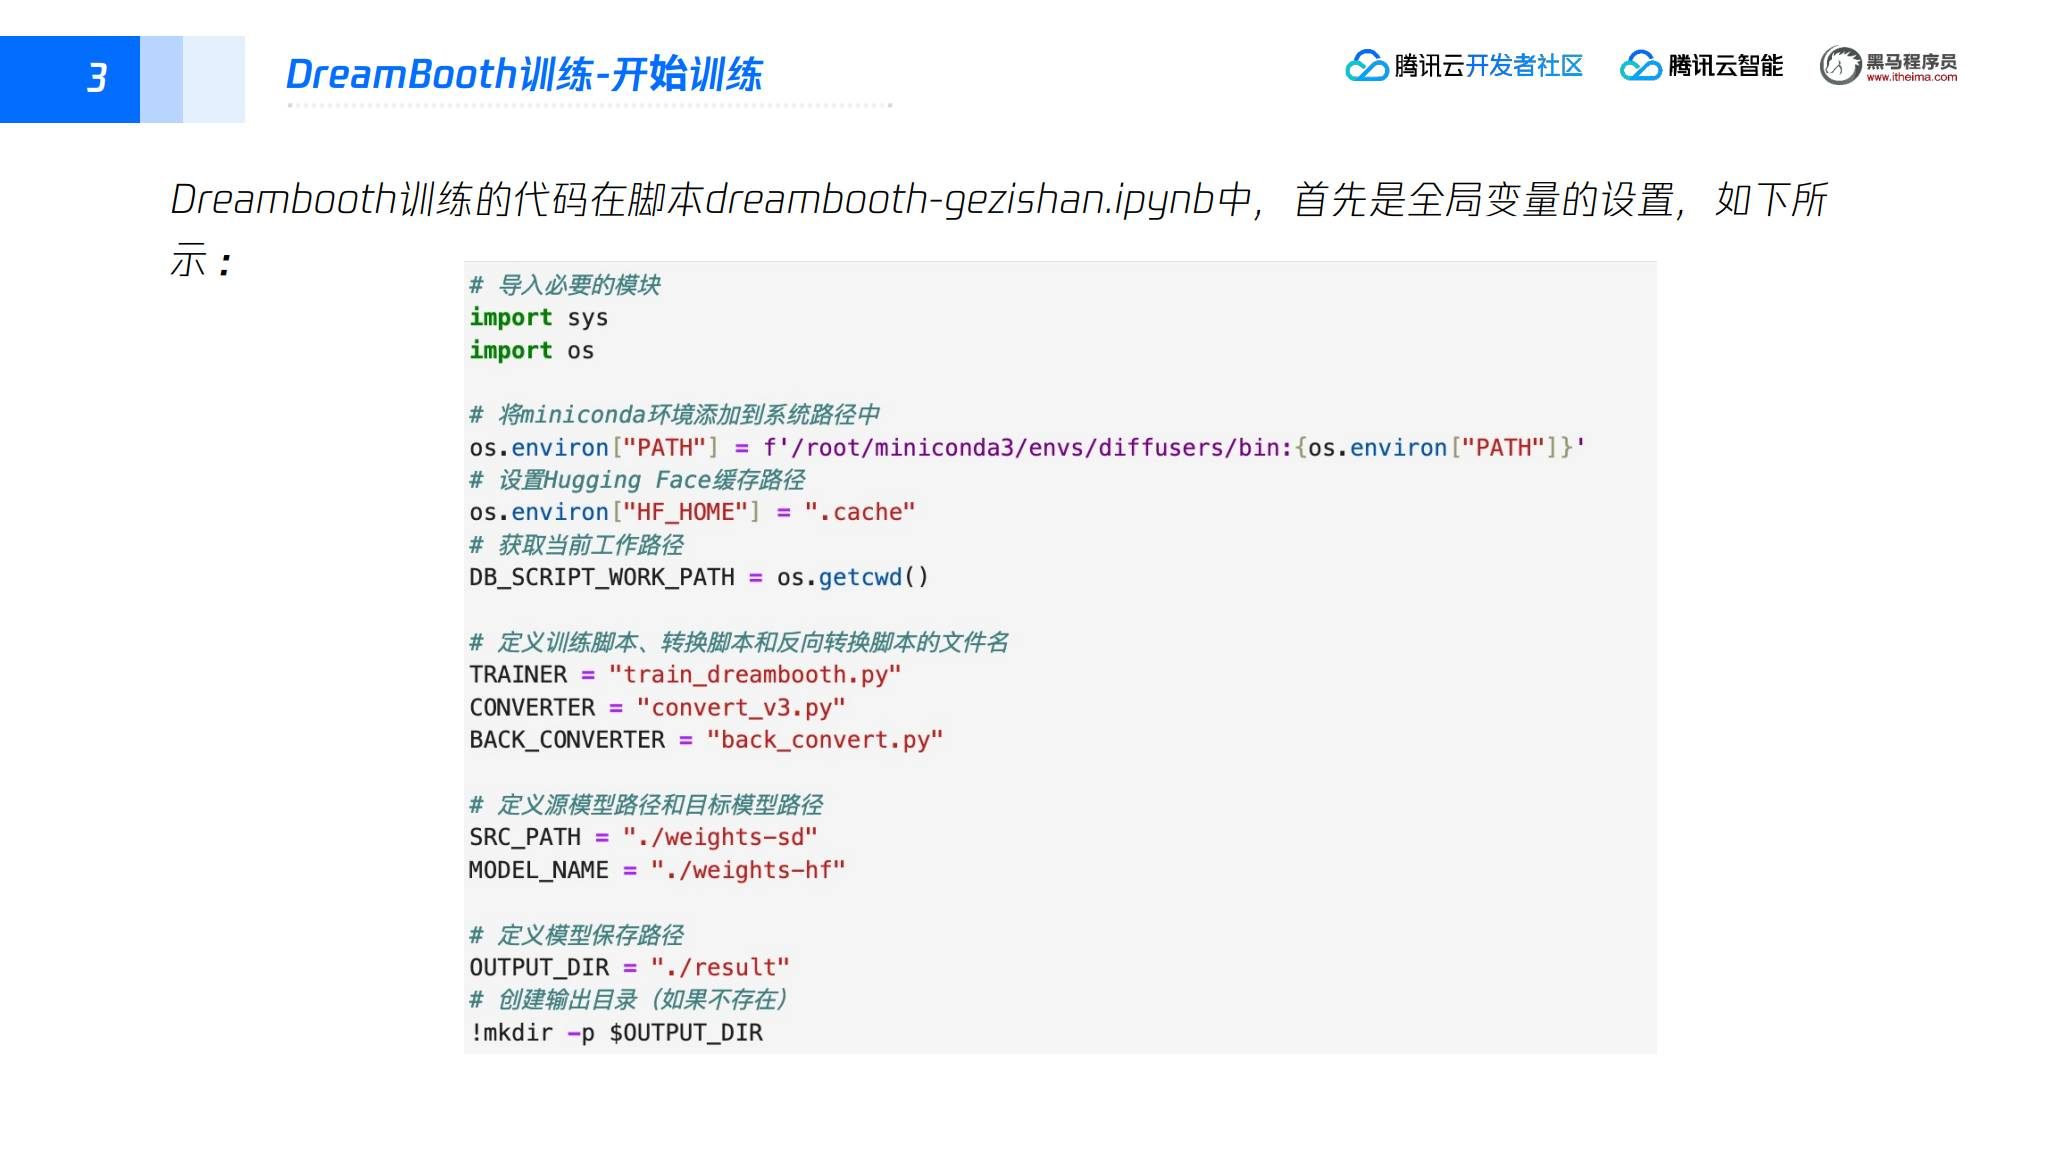

在项目根目录打开 `dreambooth-gezishan.ipynb`。全局变量包括当前工作目录、转换脚本、模型目录和输出目录：

```python
import sys
import os

# 课程云端环境路径；自己的环境应替换为实际解释器目录
os.environ["PATH"] = f"/root/miniconda3/envs/diffusers/bin:{os.environ['PATH']}"
os.environ["HF_HOME"] = ".cache"
DB_SCRIPT_WORK_PATH = os.getcwd()

TRAINER = "train_dreambooth.py"
CONVERTER = "convert_v3.py"
BACK_CONVERTER = "back_convert.py"
SRC_PATH = "./weights-sd"
MODEL_NAME = "./weights-hf"
OUTPUT_DIR = "./result"
!mkdir -p $OUTPUT_DIR
```

`HF_HOME` 指向相对缓存目录；`MODEL_NAME` 是转换后供训练读取的目录；`OUTPUT_DIR` 是训练结果目录。上面 PATH 的 f-string 调整了内外引号，保留原截图设置含义。

源模型格式转换使用课件中独立指定的检查点路径：

```python
SOURCE_CHECKPOINT_PATH = "./model-sd/model.safetensors"
!python $CONVERTER --checkpoint_path $SOURCE_CHECKPOINT_PATH --dump_path $MODEL_NAME
```

转换成功后，目标目录应包含 `scheduler/`、`text_encoder/`、`tokenizer/`、`unet/`、`vae/` 和 `model_index.json`。

**路径核对：** 此处源路径是 `./model-sd/model.safetensors`，前面的 `SRC_PATH` 却是 `./weights-sd`。转换命令实际读取 `SOURCE_CHECKPOINT_PATH`，需要按源文件位置设置它，不能把两个路径视为自动关联。

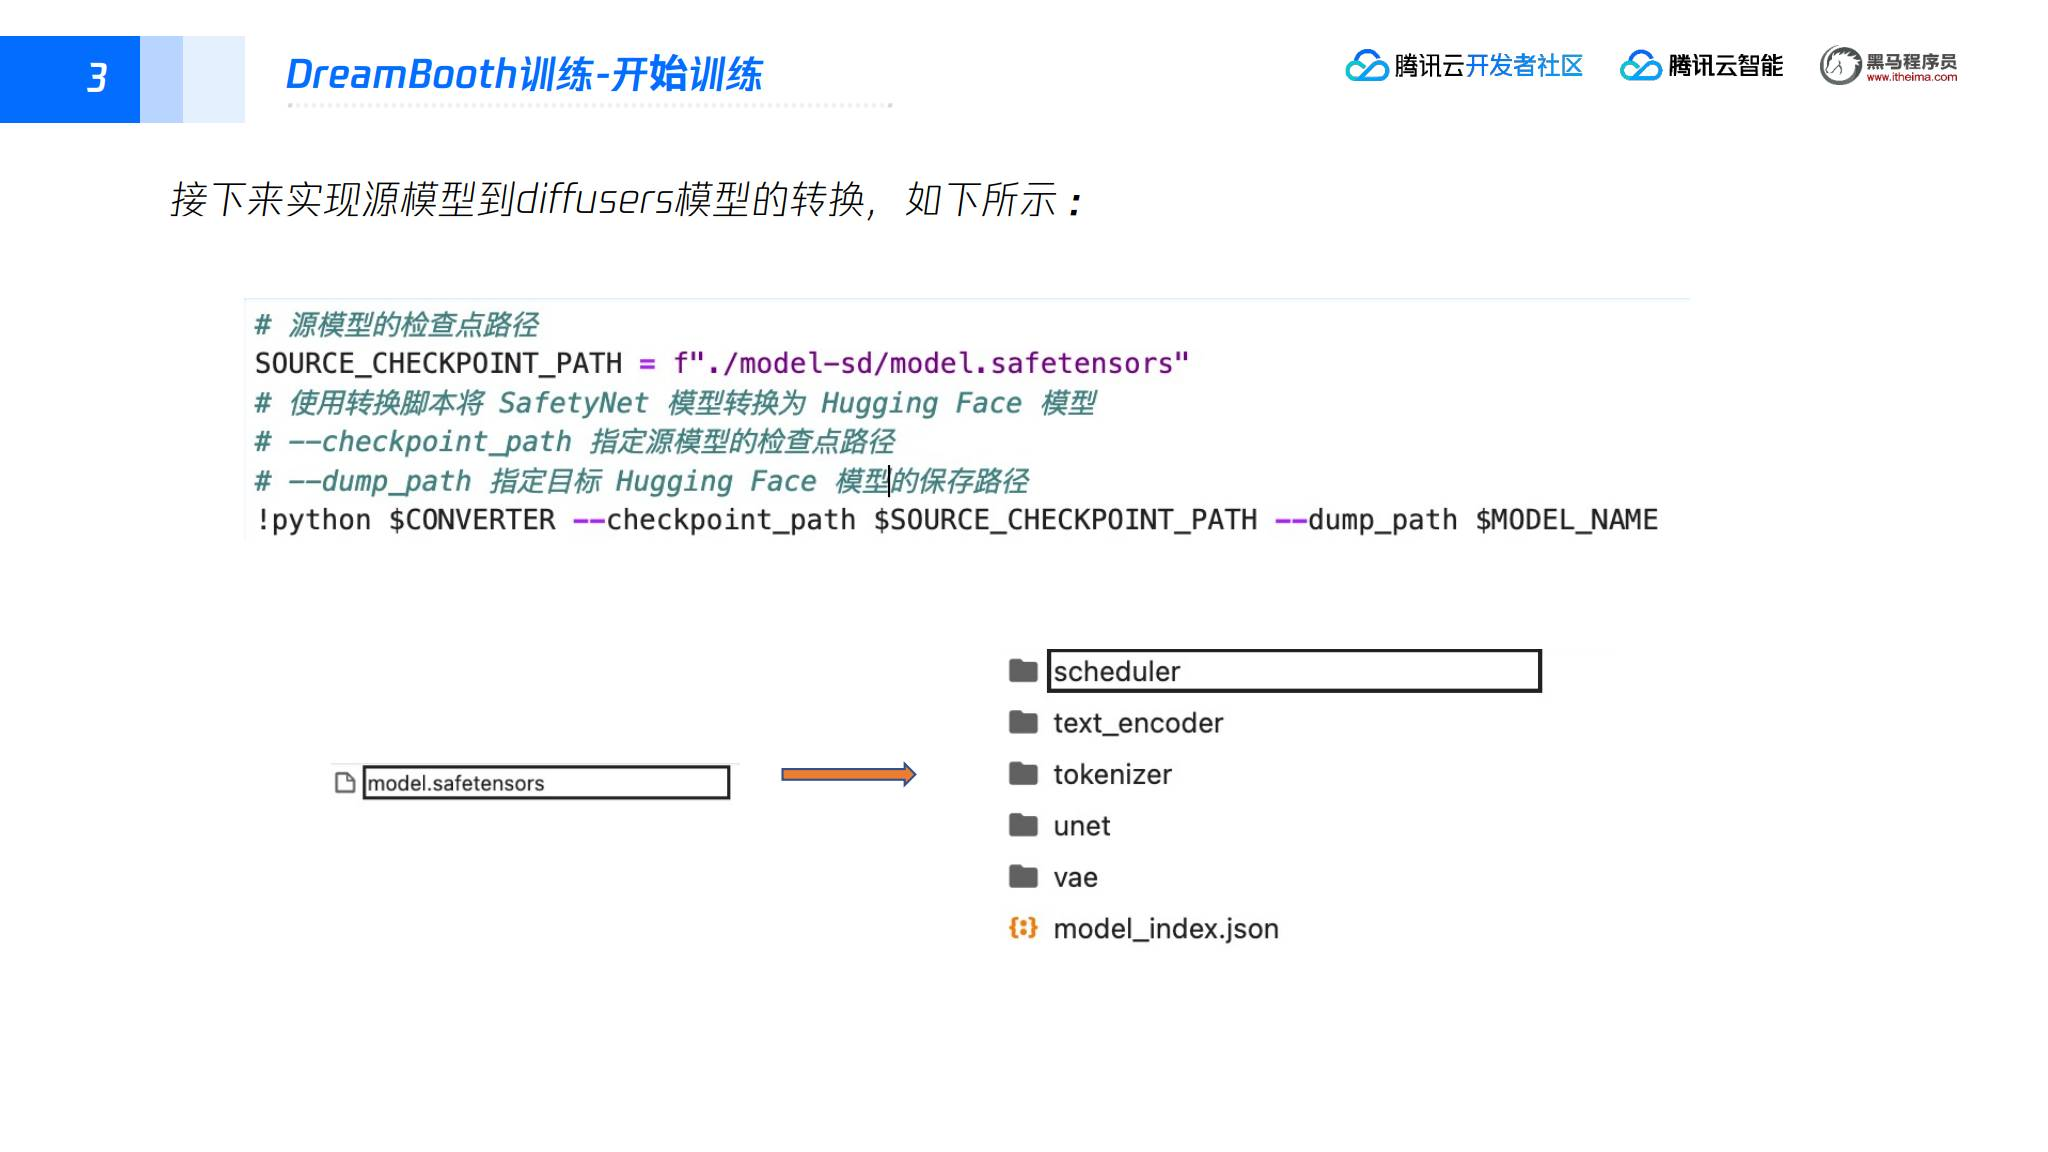

格子衫任务使用的专属关键词是 `Plaidshirtprogrammer`：

- `INSTANCE_PROMPT` 填入 `Plaidshirtprogrammer`；关键词可以自定义，但应该选择一个“不存在的词”；
- `CLASS_PROMPT` 用于让 AI 自动生成图像，不要加入专属关键词；
- 预览图的 prompt 根据希望生成的效果设置。

**关键词核对：** 第 30 页文字和预测界面使用 `Plaidshirtprogrammer`，但训练配置截图写的是 `Plaidshirtprogramer`（少一个 `m`）。推理时应使用实际训练的 `INSTANCE_PROMPT`；下文代码保留截图中的拼写。

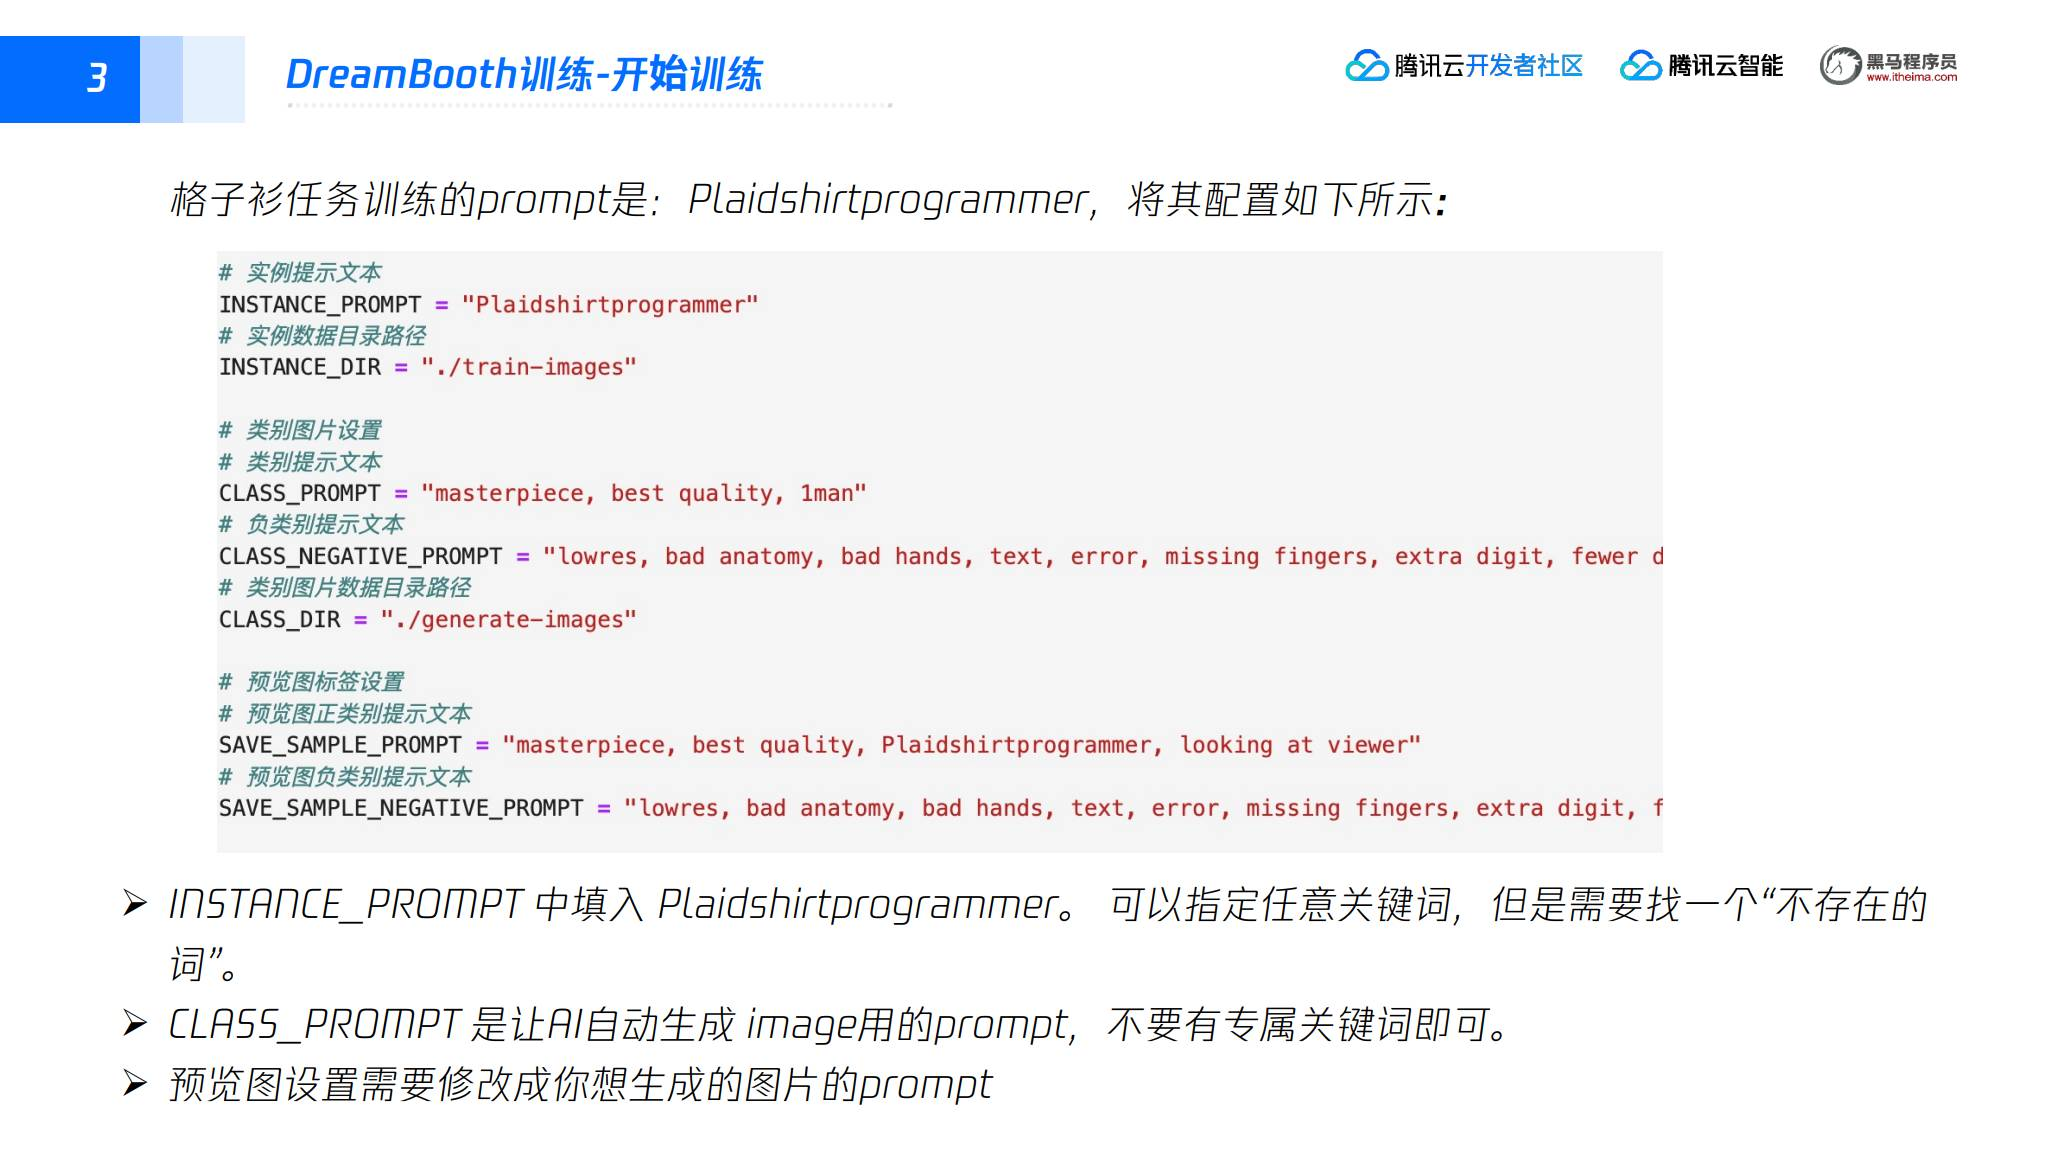

截图中可完整读取的 prompt 配置如下：

```python
INSTANCE_PROMPT = "Plaidshirtprogramer"
INSTANCE_DIR = "./train-images"
CLASS_PROMPT = "masterpiece, best quality, 1man"
CLASS_DIR = "./generate-images"
SAVE_SAMPLE_PROMPT = "masterpiece, best quality, Plaidshirtprogramer, looking at viewer"
```

`CLASS_NEGATIVE_PROMPT` 和 `SAVE_SAMPLE_NEGATIVE_PROMPT` 的长字符串在原截图右侧被截断，本篇保留原图，不补猜字符串尾部。启用先验保持时，类别提示词生成的图片用于保留基础类别能力；预览提示词则用于在训练过程中观察格子衫效果。

### 4. 加速器、训练和输出

先执行 `accelerate.sh` 写入单机、单进程、FP16 的配置，再设置参数、启动训练并检查输出。下面按原截图整理配置和命令；截图没有展示全部条件参数的生成代码，因此训练启动段属于课程 Notebook 的片段。

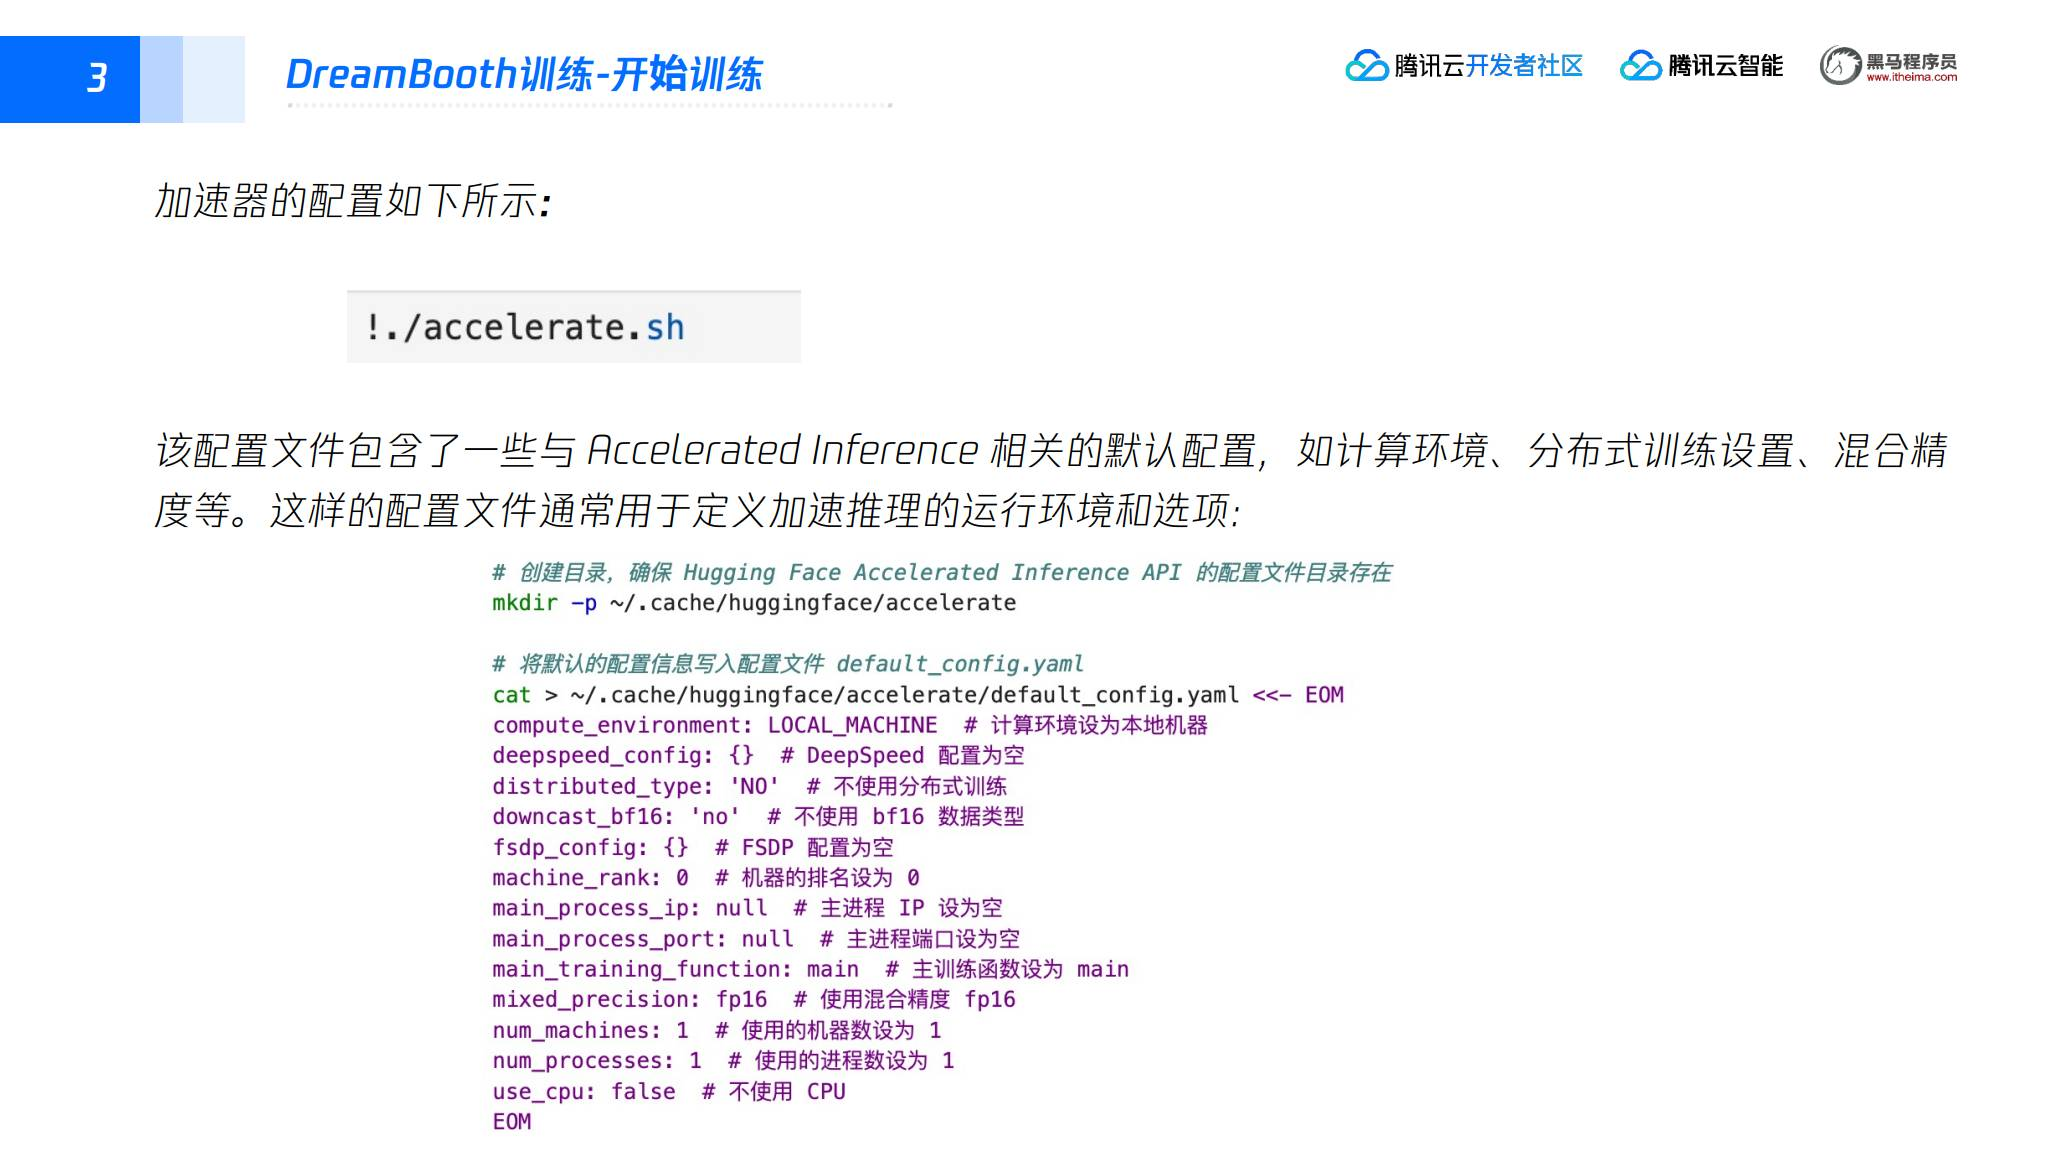

在 DreamBooth 项目根目录的 Notebook 中运行：

```bash
!./accelerate.sh
```

脚本写入 `~/.cache/huggingface/accelerate/default_config.yaml`，截图中的内容为：

```yaml
compute_environment: LOCAL_MACHINE
deepspeed_config: {}
distributed_type: 'NO'
downcast_bf16: 'no'
fsdp_config: {}
machine_rank: 0
main_process_ip: null
main_process_port: null
main_training_function: main
mixed_precision: fp16
num_machines: 1
num_processes: 1
use_cpu: false
```

讲义文字称其为加速推理配置，本实验通过 Accelerate 启动训练；`distributed_type: 'NO'`、`num_processes: 1` 表明示例并没有配置多机训练。

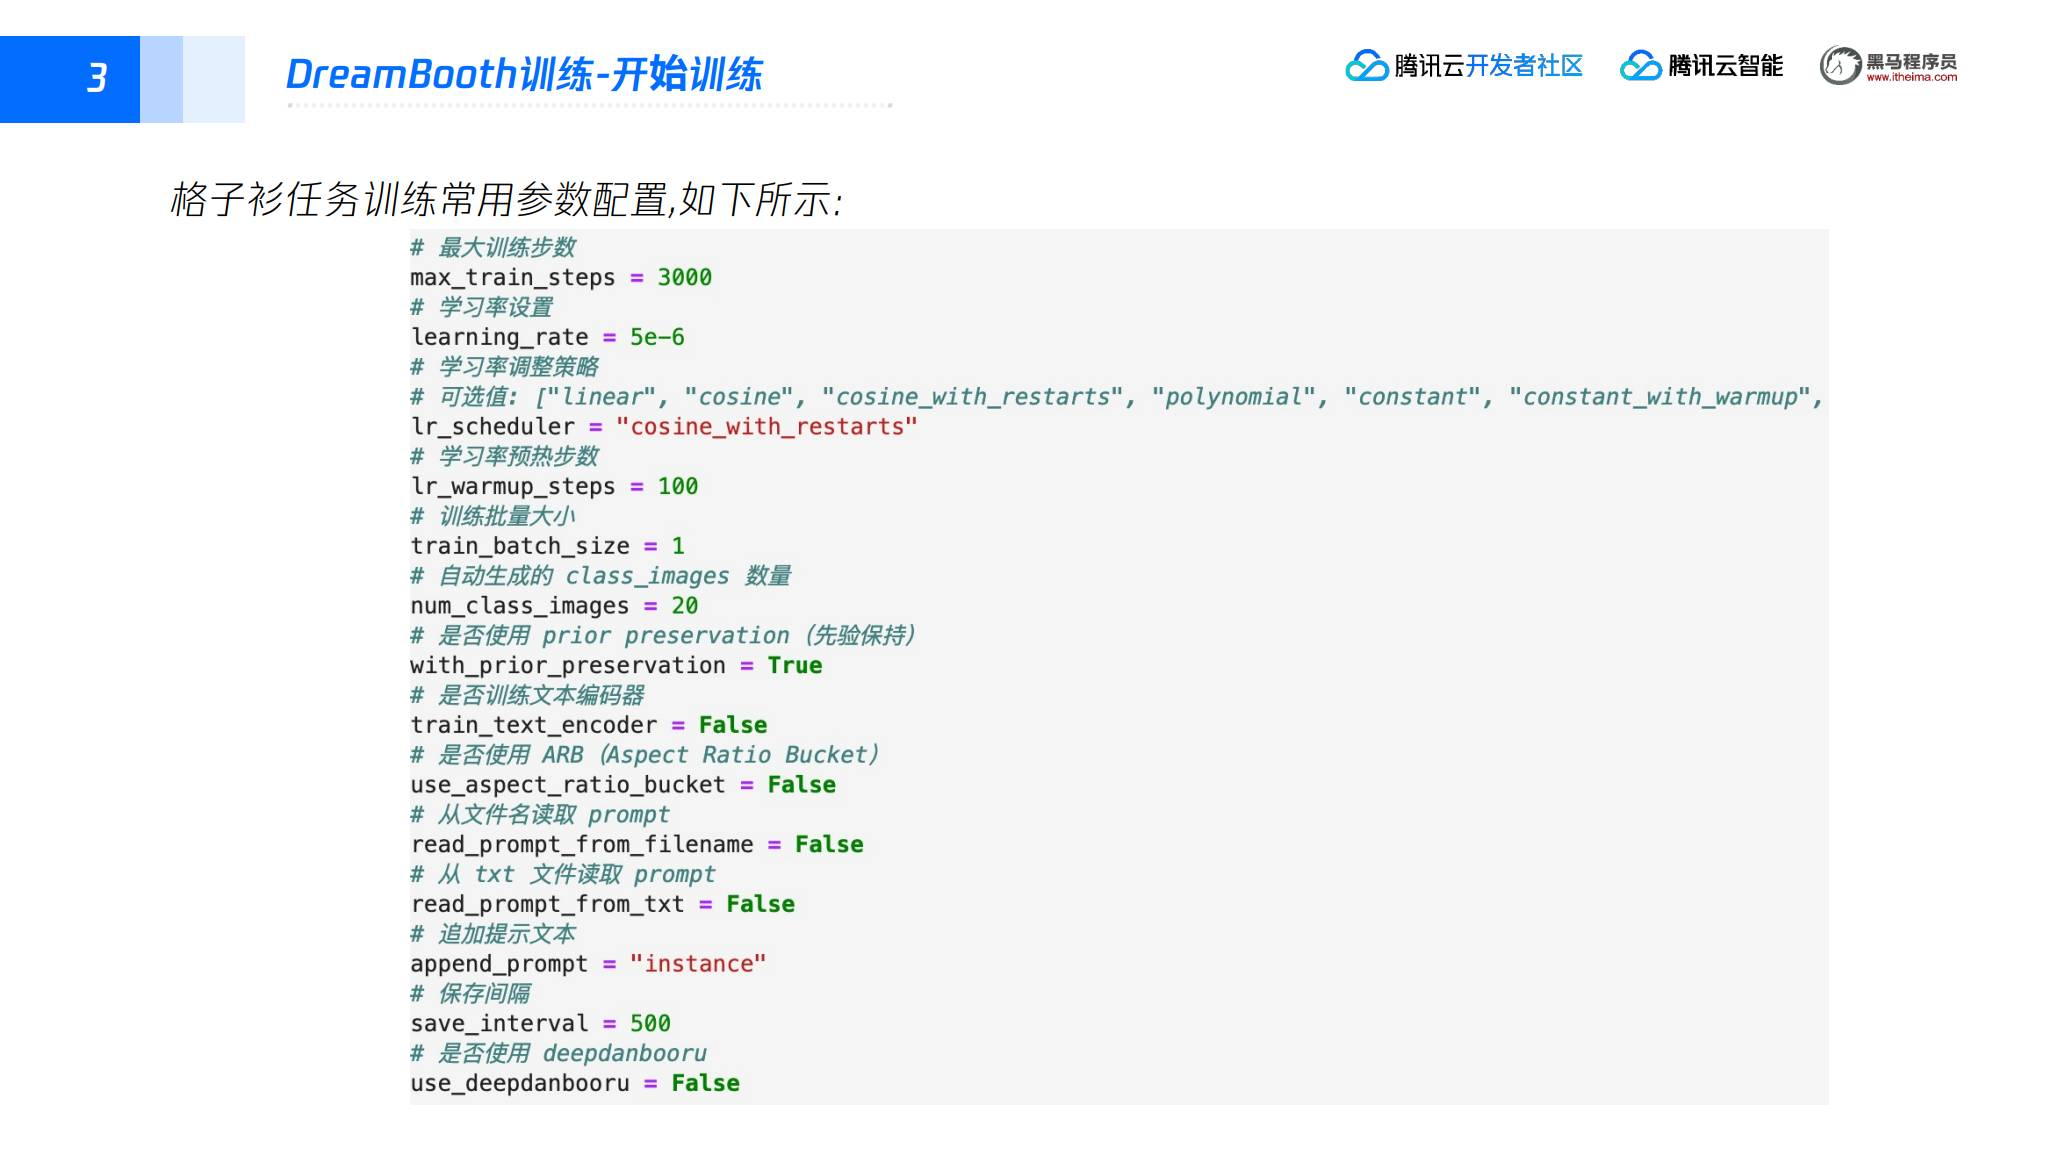

常用训练参数（第 32 页）：

```python
max_train_steps = 3000
learning_rate = 5e-6
lr_scheduler = "cosine_with_restarts"
lr_warmup_steps = 100
train_batch_size = 1
num_class_images = 20
with_prior_preservation = True
train_text_encoder = False
use_aspect_ratio_bucket = False
read_prompt_from_filename = False
read_prompt_from_txt = False
append_prompt = "instance"
save_interval = 500
use_deepdanbooru = False
```

这里训练 3000 步，前 100 步预热；每步处理 1 张图，每 500 步保存一次。实例图使用统一提示词，不从图片文件名或 `.txt` 描述中读取。生成 20 张类别图片，启用先验保持；文本编码器不参与此次训练。

其他参数（第 33 页）：

```python
resolution = 512
gradient_accumulation_steps = 1
seed = 1337
log_interval = 10
clip_skip = 1
sample_batch_size = 4
prior_loss_weight = 1.0
scale_lr = False
scale_lr_sqrt = False
gradient_checkpointing = True
pad_tokens = False
debug_arb = False
debug_prompt = False
use_ema = False
restart_cycle = 1
last_epoch = -1
```

梯度检查点已启用，日志间隔为 10 步，生成预览图的批量为 4；学习率缩放和 EMA 关闭。

**补充核对：** 课件将 `clip_skip` 注释为“跳过梯度剪裁”，后面的 LoRA 图也称其为梯度裁剪。这容易混淆。CLIP skip 实际与计算提示词嵌入时选用的 CLIP 层有关，参见 [Diffusers 官方参数说明](https://huggingface.co/docs/diffusers/api/pipelines/stable_diffusion/text2img)。不同训练脚本的取值约定以配套实现为准，不能把它当作梯度裁剪开关。

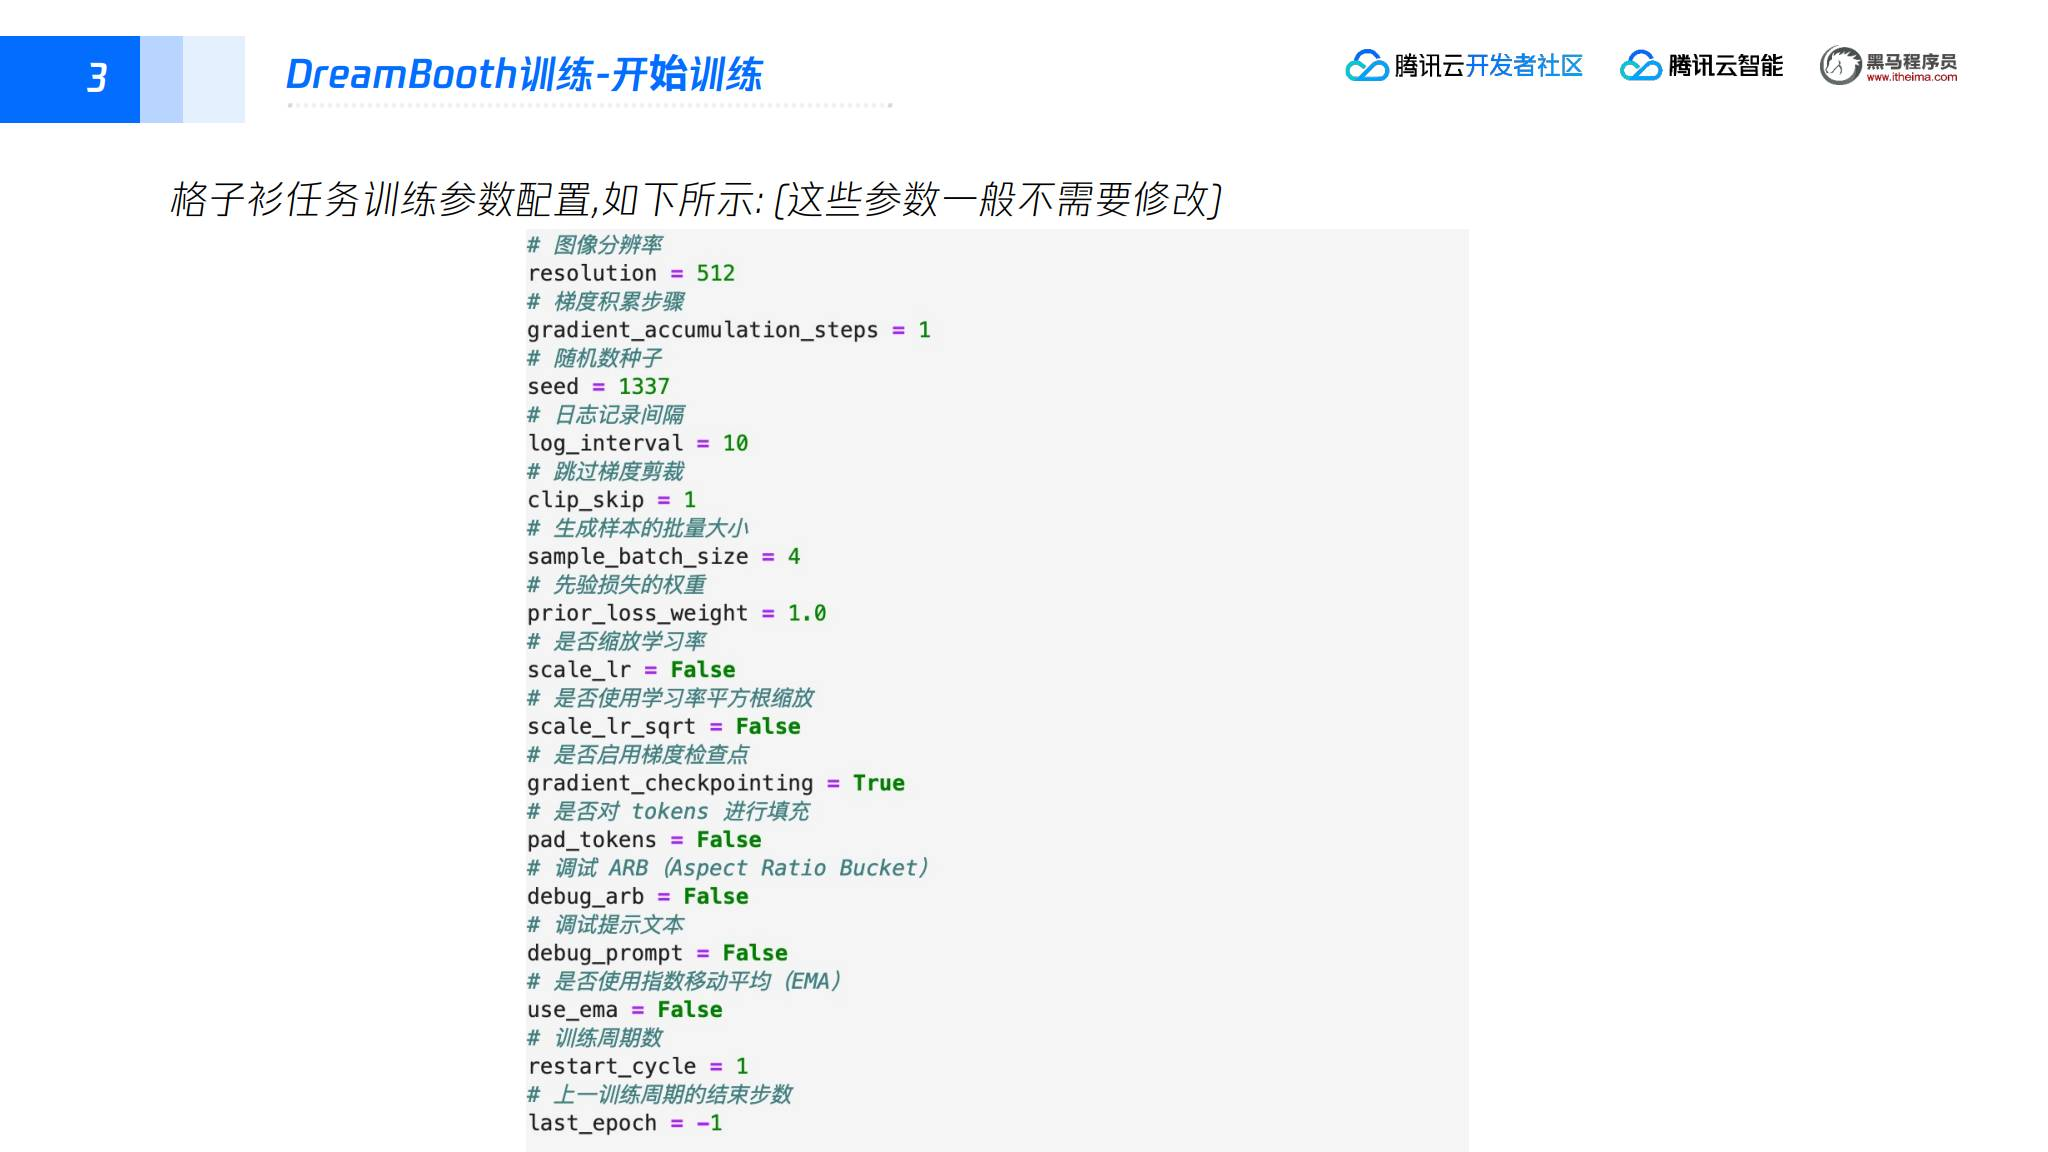

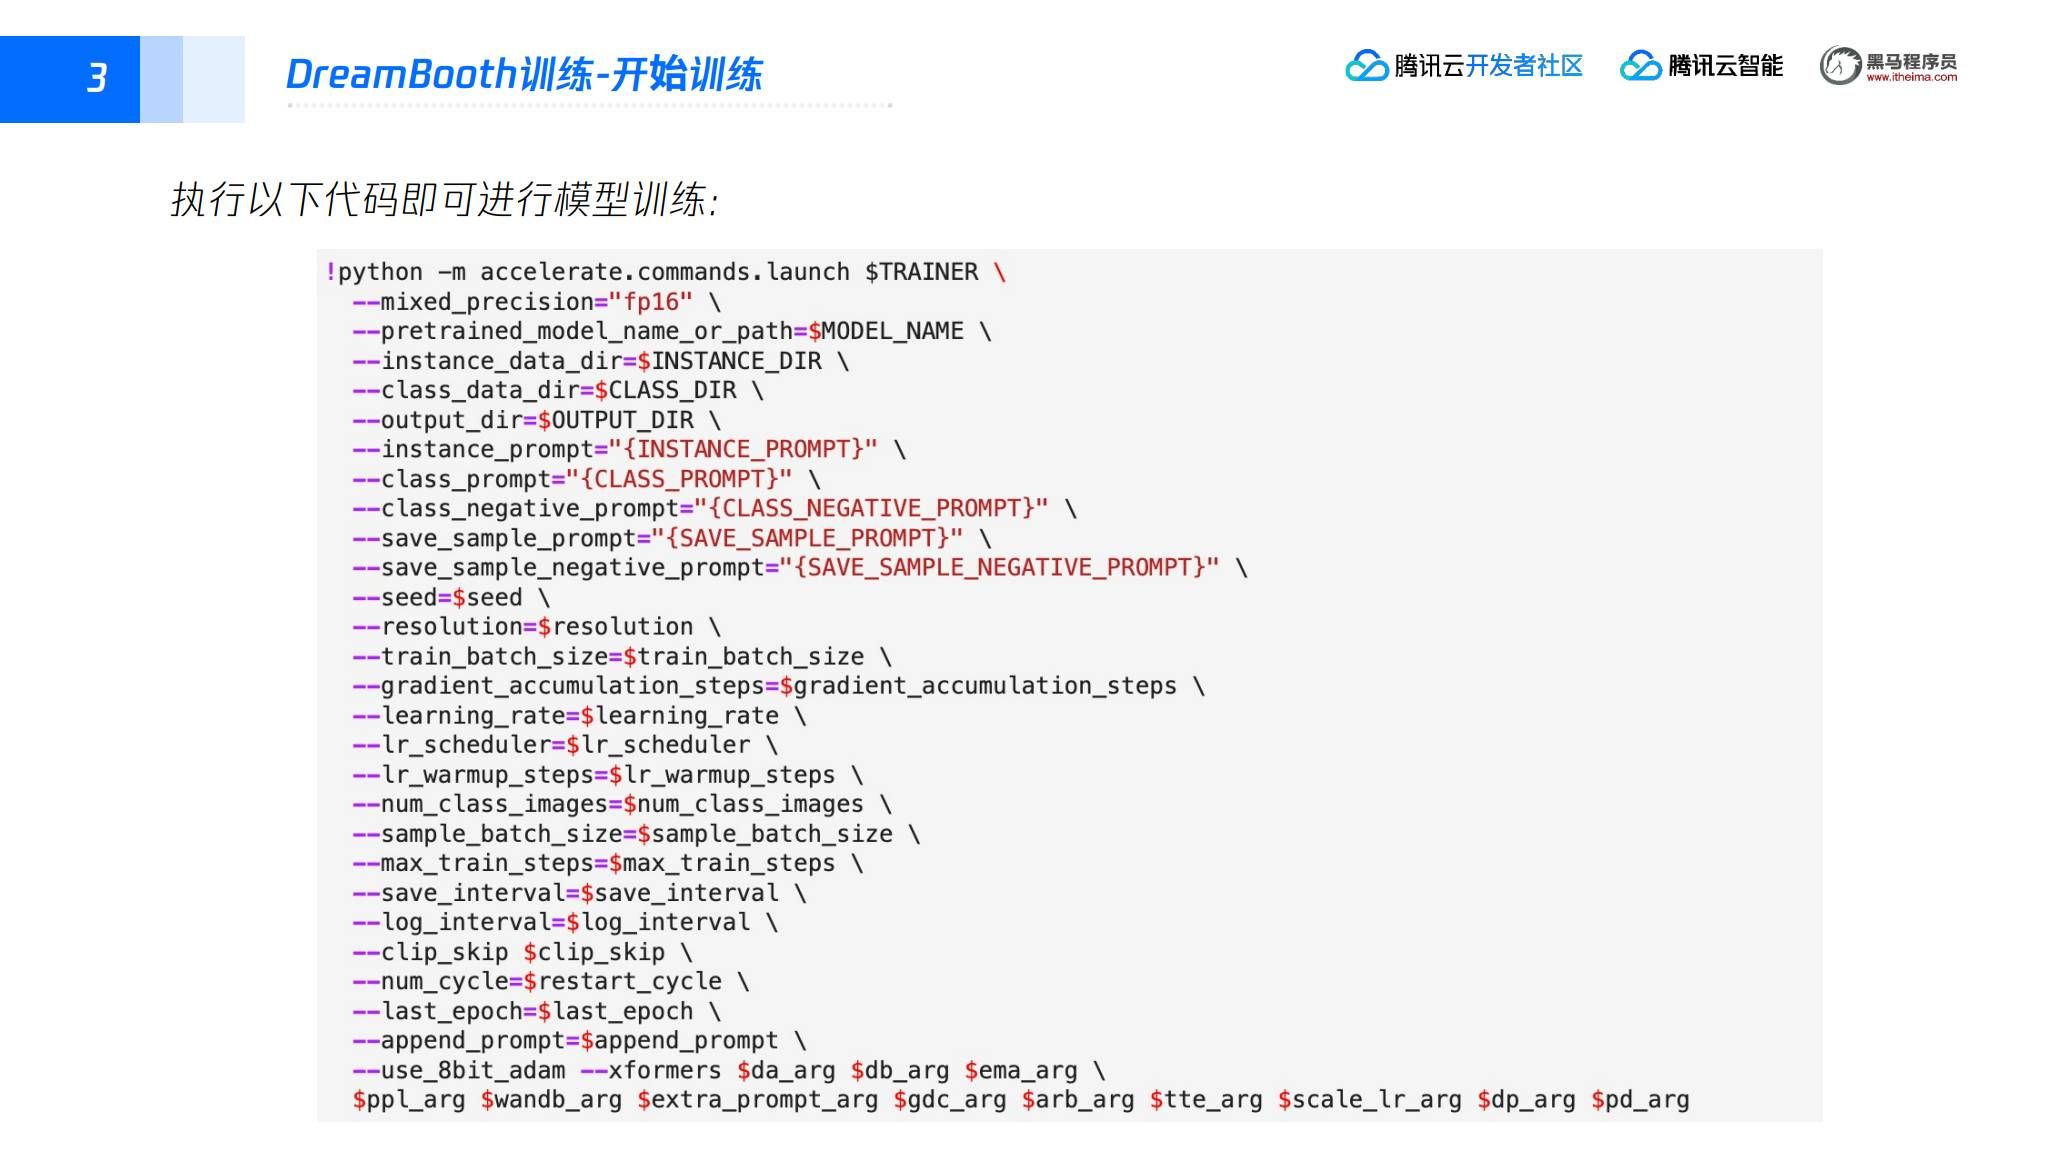

第 34 页训练命令保留了 Notebook 的变量替换语法，需在前面的变量和条件参数已定义后运行：

```python
!python -m accelerate.commands.launch $TRAINER \
    --mixed_precision="fp16" \
    --pretrained_model_name_or_path=$MODEL_NAME \
    --instance_data_dir=$INSTANCE_DIR \
    --class_data_dir=$CLASS_DIR \
    --output_dir=$OUTPUT_DIR \
    --instance_prompt="{INSTANCE_PROMPT}" \
    --class_prompt="{CLASS_PROMPT}" \
    --class_negative_prompt="{CLASS_NEGATIVE_PROMPT}" \
    --save_sample_prompt="{SAVE_SAMPLE_PROMPT}" \
    --save_sample_negative_prompt="{SAVE_SAMPLE_NEGATIVE_PROMPT}" \
    --seed=$seed \
    --resolution=$resolution \
    --train_batch_size=$train_batch_size \
    --gradient_accumulation_steps=$gradient_accumulation_steps \
    --learning_rate=$learning_rate \
    --lr_scheduler=$lr_scheduler \
    --lr_warmup_steps=$lr_warmup_steps \
    --num_class_images=$num_class_images \
    --sample_batch_size=$sample_batch_size \
    --max_train_steps=$max_train_steps \
    --save_interval=$save_interval \
    --log_interval=$log_interval \
    --clip_skip $clip_skip \
    --num_cycle=$restart_cycle \
    --last_epoch=$last_epoch \
    --append_prompt=$append_prompt \
    --use_8bit_adam --xformers $da_arg $db_arg $ema_arg \
    $ppl_arg $wandb_arg $extra_prompt_arg $gdc_arg $arb_arg $tte_arg $scale_lr_arg $dp_arg $pd_arg
```

课件没有展示 `$da_arg` 等条件参数片段如何构造；直接复制这一单元不能得到完整实验。它也包含课程版本专有参数，需配套 `train_dreambooth.py` 使用，不能直接换成任意版本的 Diffusers 示例脚本。

训练日志应持续显示 `Steps`、`epoch`、`loss` 和 `lr`，并出现 `Generating samples`。第 35 页示例到达 `3000/3000`；这是课程运行结果，不是本机执行输出。

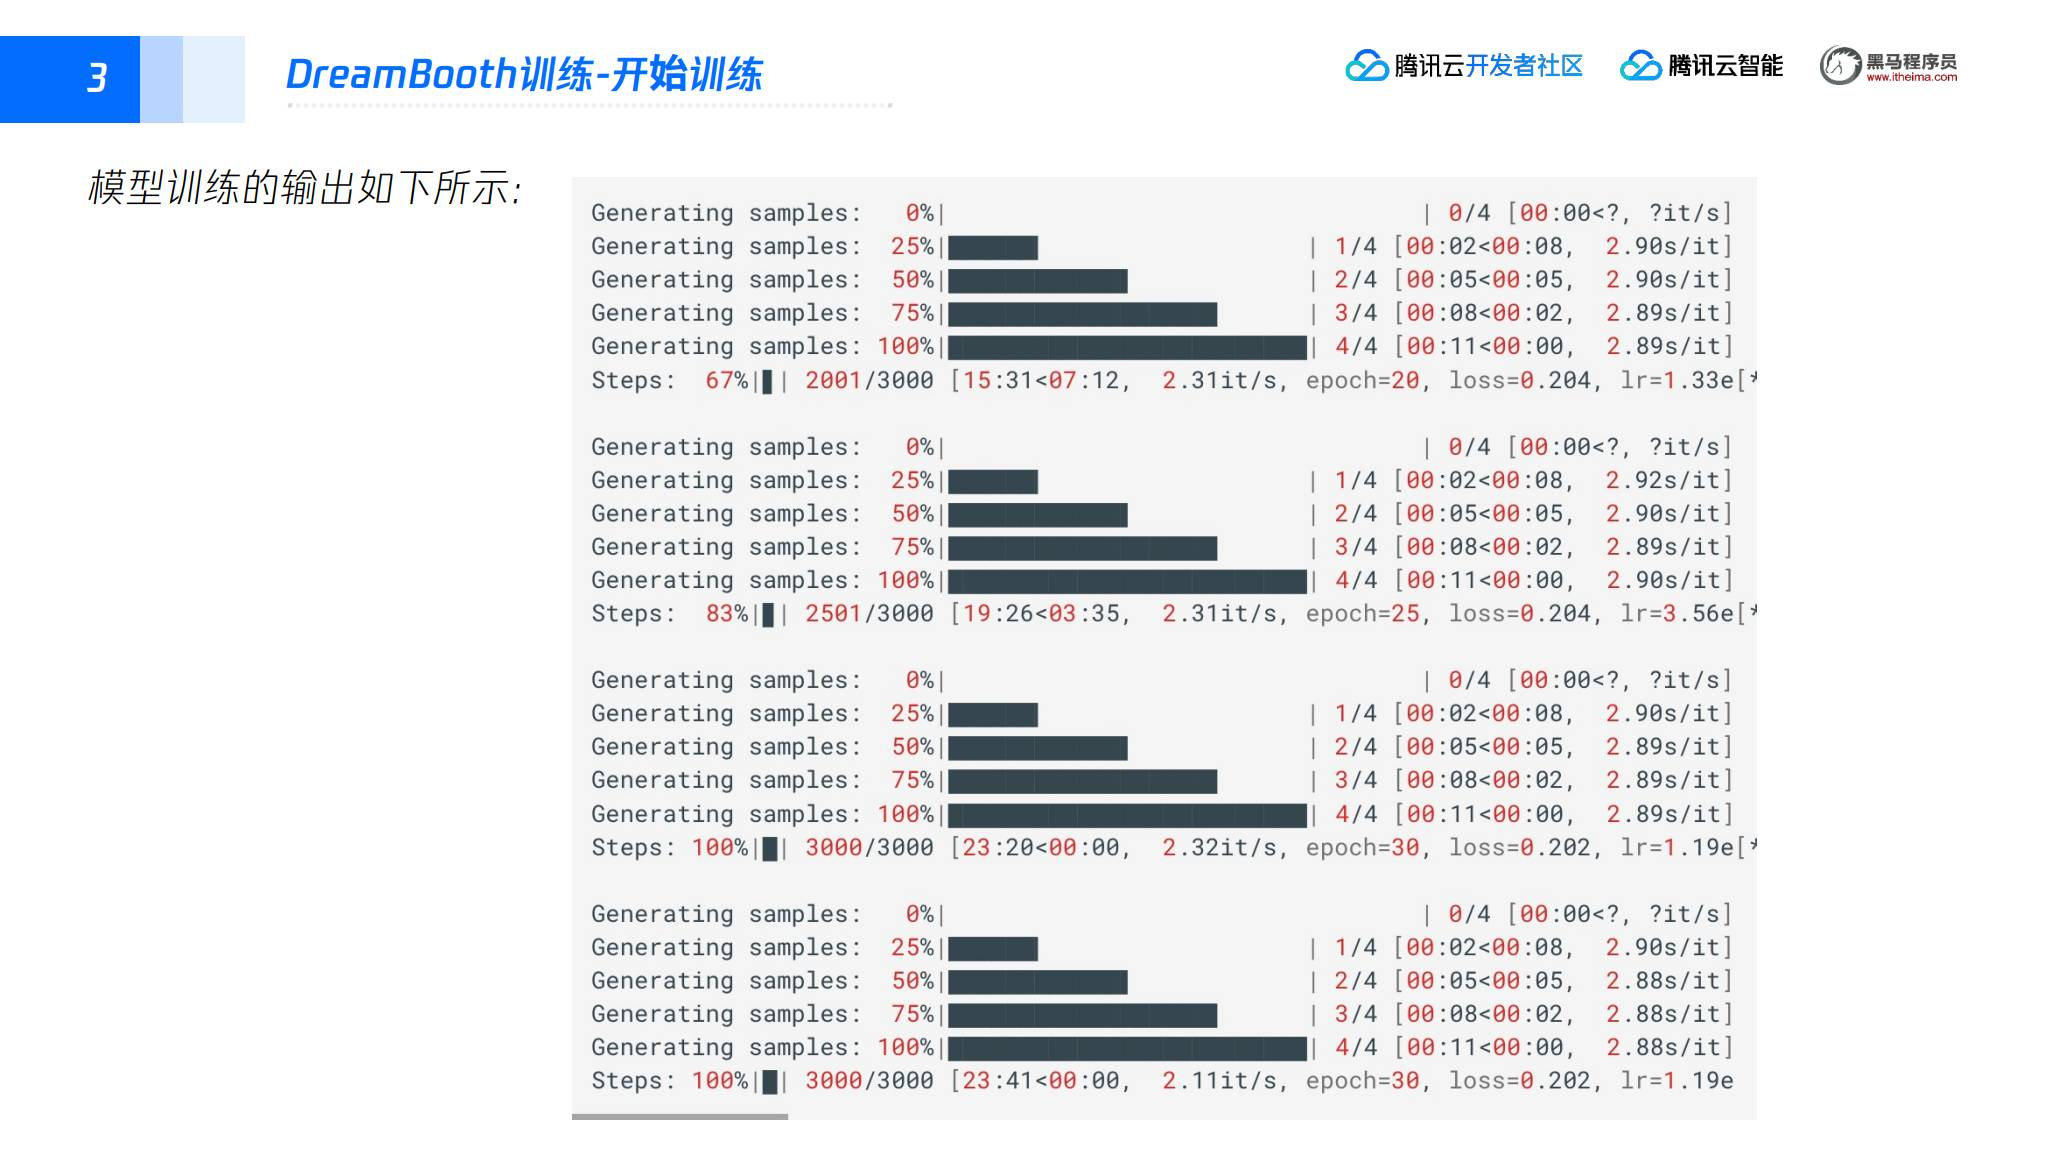

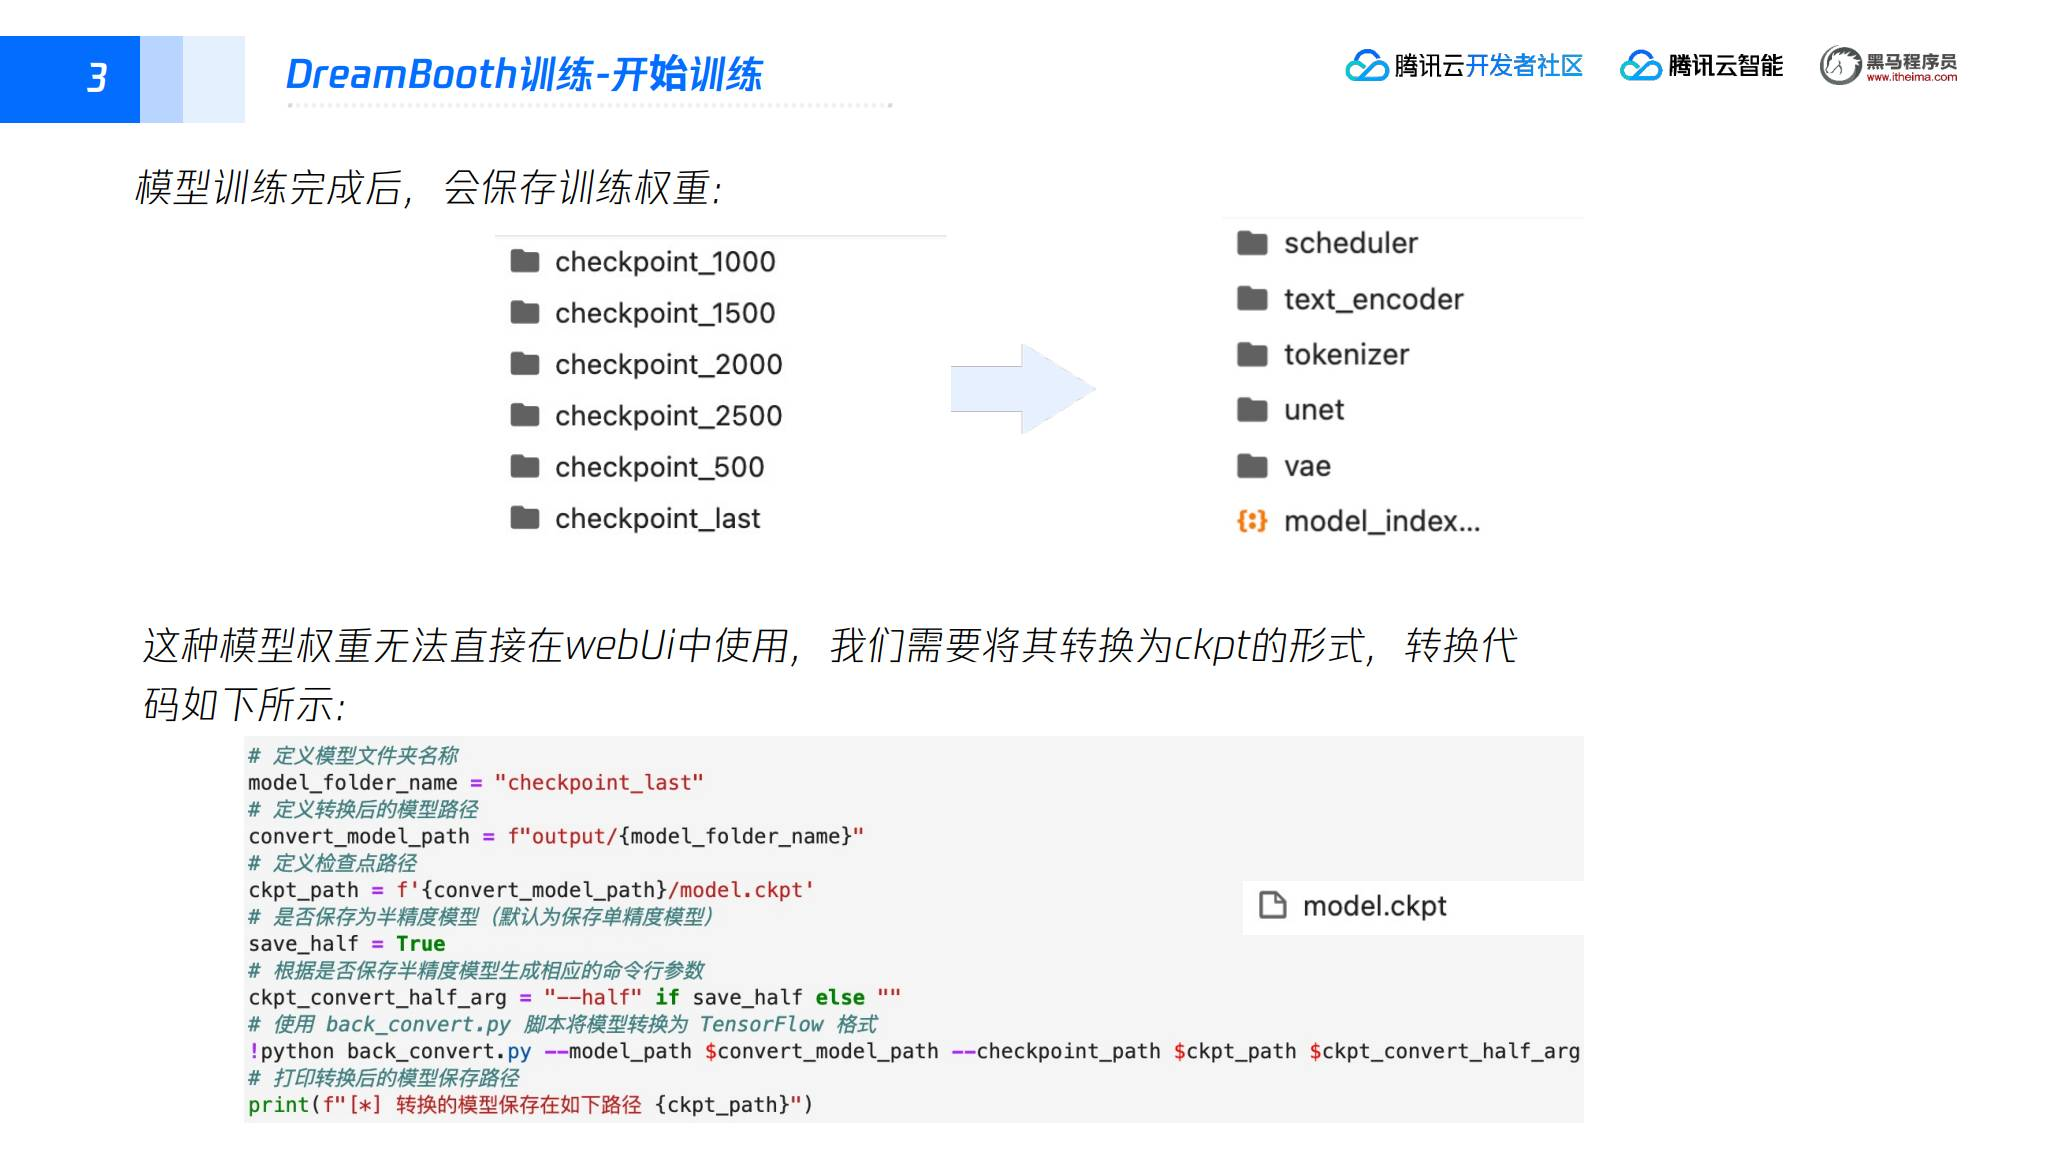

### 5. 保存权重并转换为 WebUI 模型

训练输出包含 `checkpoint_500`、`checkpoint_1000` 等中间结果和 `checkpoint_last`。每个检查点是包含 U-Net、VAE、文本编码器等组件的 Diffusers 目录。转换选择最终目录：

```python
model_folder_name = "checkpoint_last"
convert_model_path = f"output/{model_folder_name}"
ckpt_path = f"{convert_model_path}/model.ckpt"
save_half = True
ckpt_convert_half_arg = "--half" if save_half else ""

!python back_convert.py --model_path $convert_model_path --checkpoint_path $ckpt_path $ckpt_convert_half_arg
print(f"[*] 转换的模型保存在如下路径 {ckpt_path}")
```

**路径核对：** 前面设置 `OUTPUT_DIR = "./result"`，这里却从 `output/checkpoint_last` 读取。若按前面的目录训练，应将这一行调整为 `convert_model_path = os.path.join(OUTPUT_DIR, model_folder_name)`。转换后检查该目录存在 `model.ckpt`，再复制到 WebUI。

第 36 页注释把输出称为 TensorFlow 格式，但本节展示的目标文件是供 SD WebUI 使用的 `.ckpt` 权重；这里按实际文件说明，不把它当作 TensorFlow 模型。

## 五、LoRA 训练

### 1. LoRA 的思路和资源要求

LoRA 的全称是 **Low-Rank Adaptation of Large Language Models**。课程将其用于 Stable Diffusion 的定制化训练：在不修改原始 SD 模型的前提下，用少量数据训练画风、IP 或人物。

讲义用低秩矩阵表示参数增量：

```text
W' = W₀ + BA
```

其中 `W₀` 是预训练 Stable Diffusion 模型参数，`BA` 是 LoRA 学到的低秩矩阵，叠加后得到受 LoRA 影响的模型参数。课程实验基于开源 `kohya_ss`，标注显存需要 **8GB 以上**，适合社区用户和个人开发者。

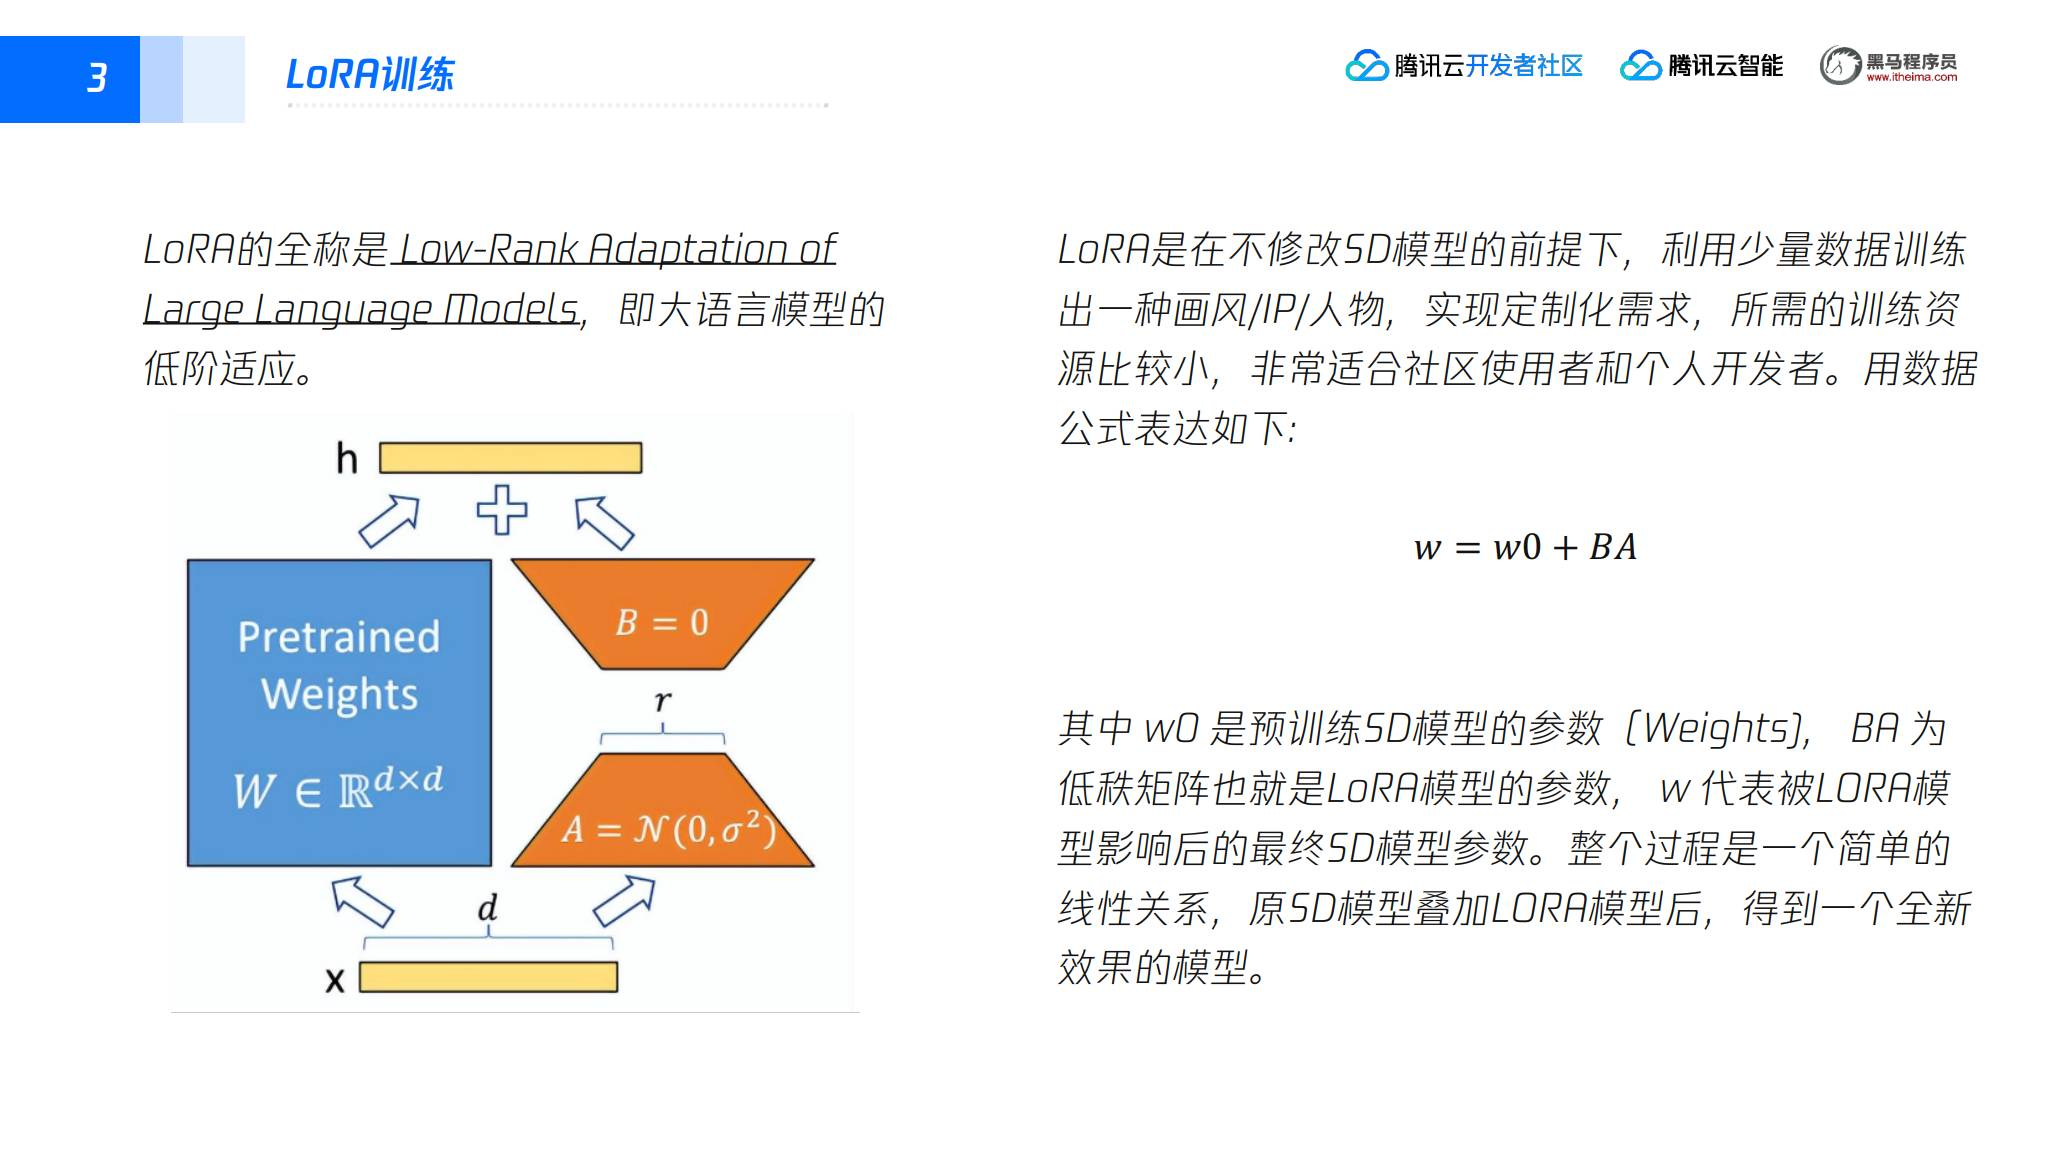

LoRA 实验在项目根目录运行 `train.sh`。目录包括 `sd-scripts/`（训练代码）、`sd-models/`（基础权重）、`train/`（训练数据）、`logs/`（日志）、`output/`（LoRA 输出）和 `huggingface/`（相关工具）。

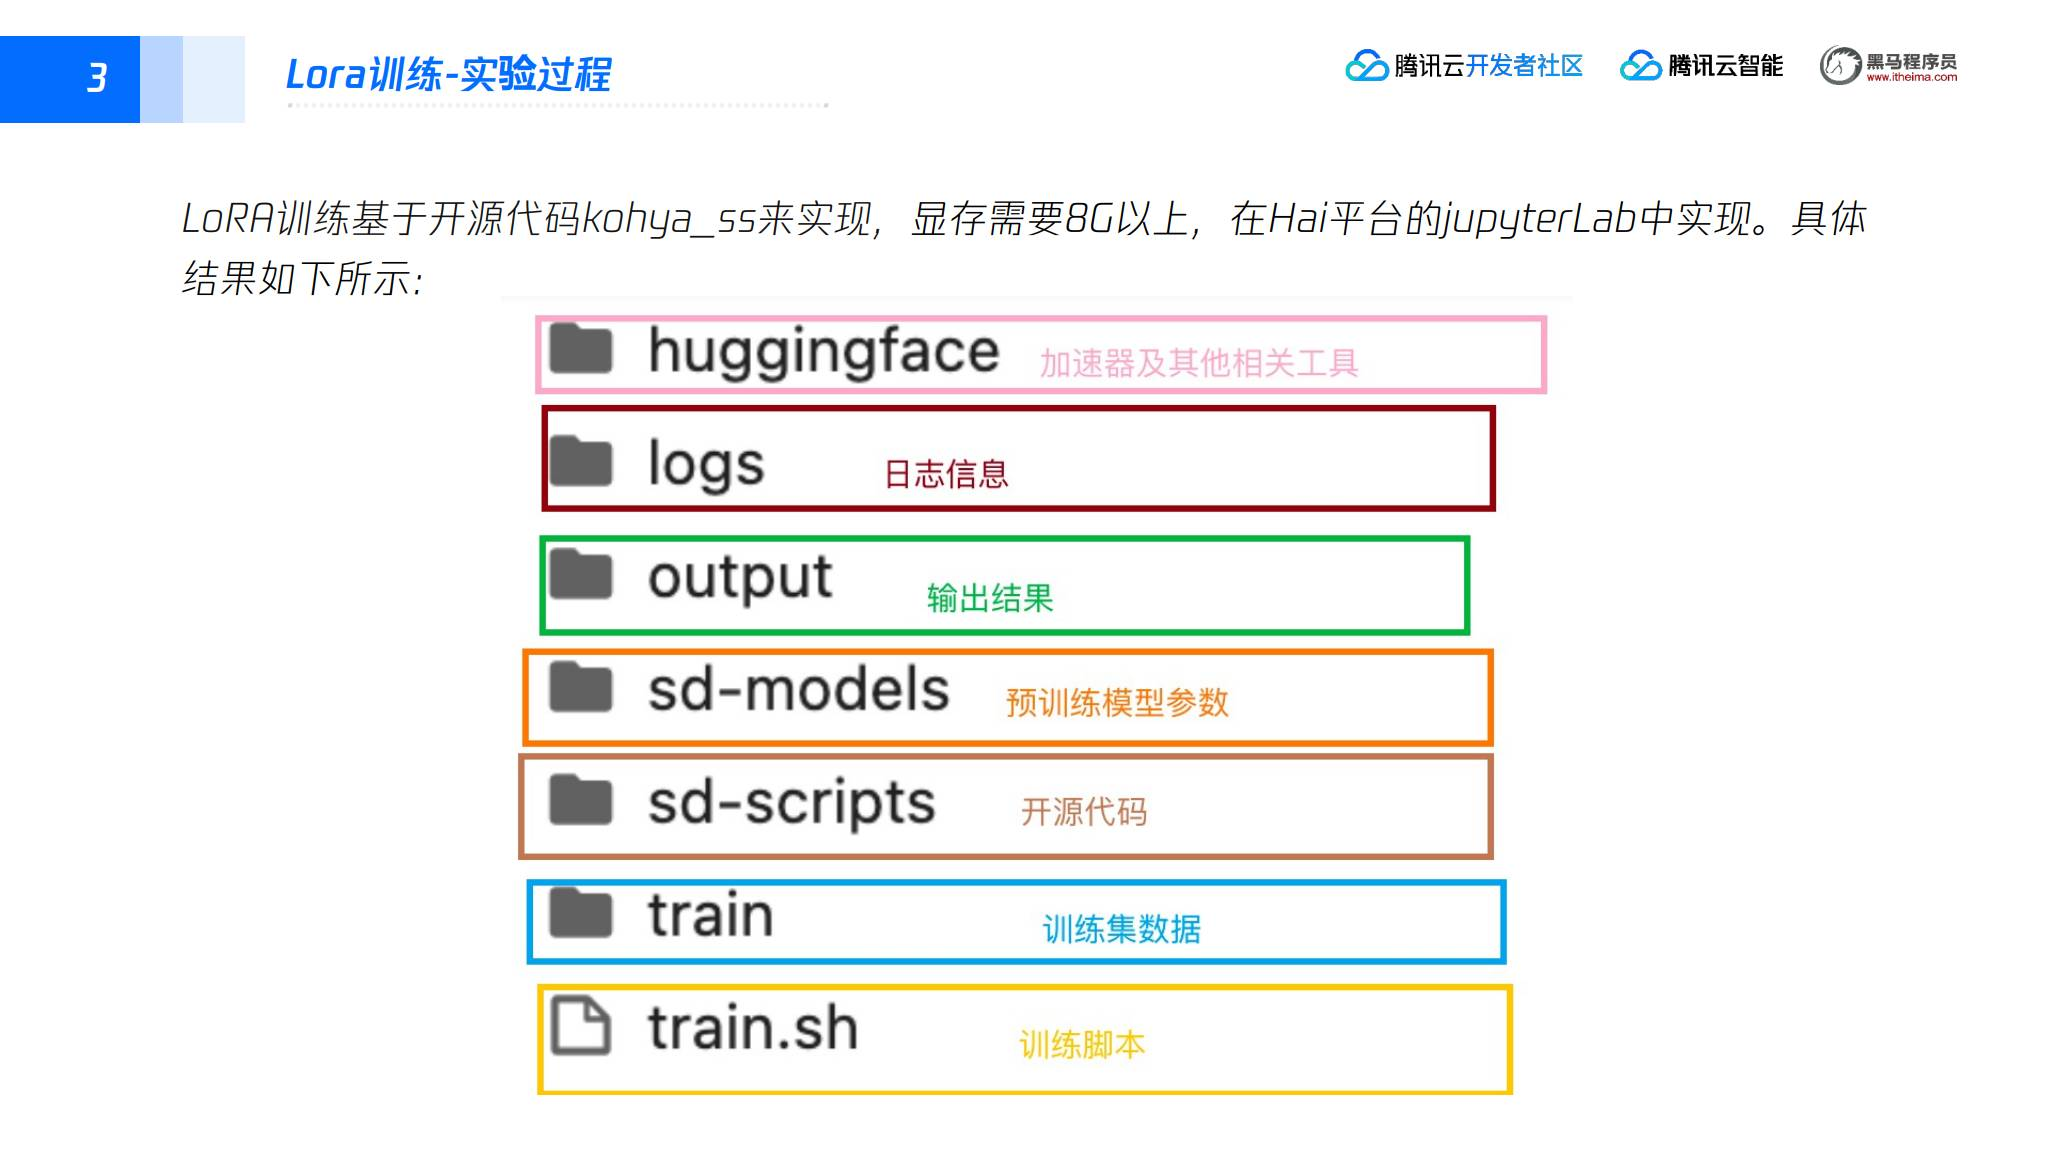

### 2. 数据准备

课程示例使用 LoRA 训练“戴眼镜”的效果：

- 收集 **20 张**图片；
- 每张图片配一个同名 `.txt` 文件；
- 文本文件记录对应图片的文字描述；
- 图片和描述文件统一放入 `train` 文件夹。

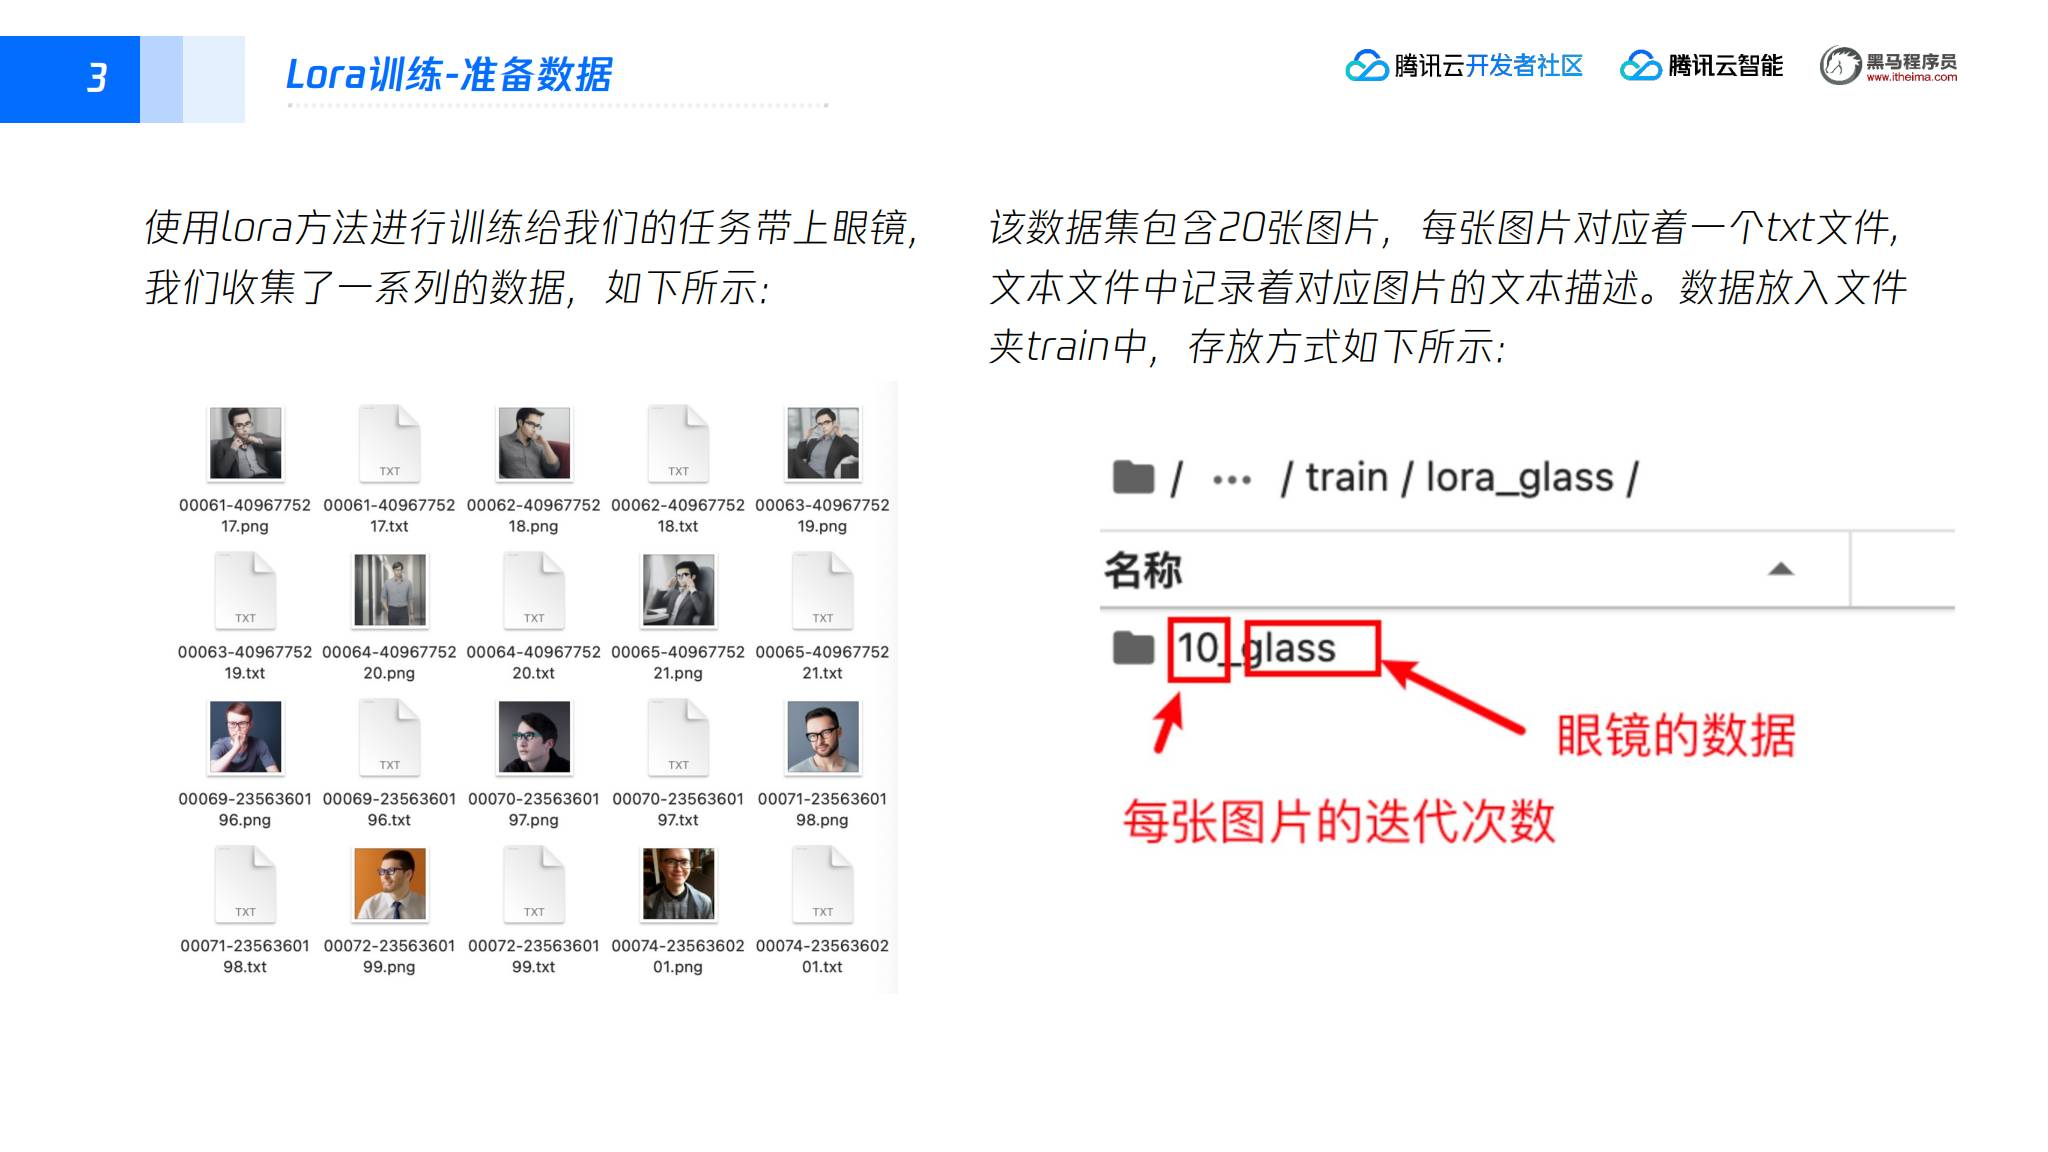

第 39 页的目录图还展示了重复次数这一层：

```text
train/
└── lora_glass/
    └── 10_glass/
        ├── 图片.png
        └── 图片.txt
```

这里“图片”只是表示配对文件的示意名；实际图片和描述文件应使用相同的文件名主体。`10_glass` 的 `10` 表示每张图片的重复次数，`glass` 表示眼镜数据。后面配置截图写的是 `./train/lora-glass`，与目录图中的 `lora_glass` 不一致；训练前要改成实际路径。

### 3. LoRA 参数配置

训练前需要配置：

- 预训练模型路径、模型类型和参数化方式；
- 训练数据集路径；
- 网络结构和超参数；
- 图像分辨率、批次大小、最大训练轮数；
- 模型保存频率；
- 训练模式，例如只训练 U-Net 或只训练文本编码器；
- 模型输出名称、保存格式和是否保存训练状态。

学习率配置包括整体学习率 `lr`、U-Net 学习率 `unet_lr` 和文本编码器学习率 `text_encoder_lr`。课程选择余弦退火重启作为 `lr_scheduler`，并配置 `lr_warmup_steps`、`lr_restart_cycles`；优化器默认使用 `AdamW8bit`。

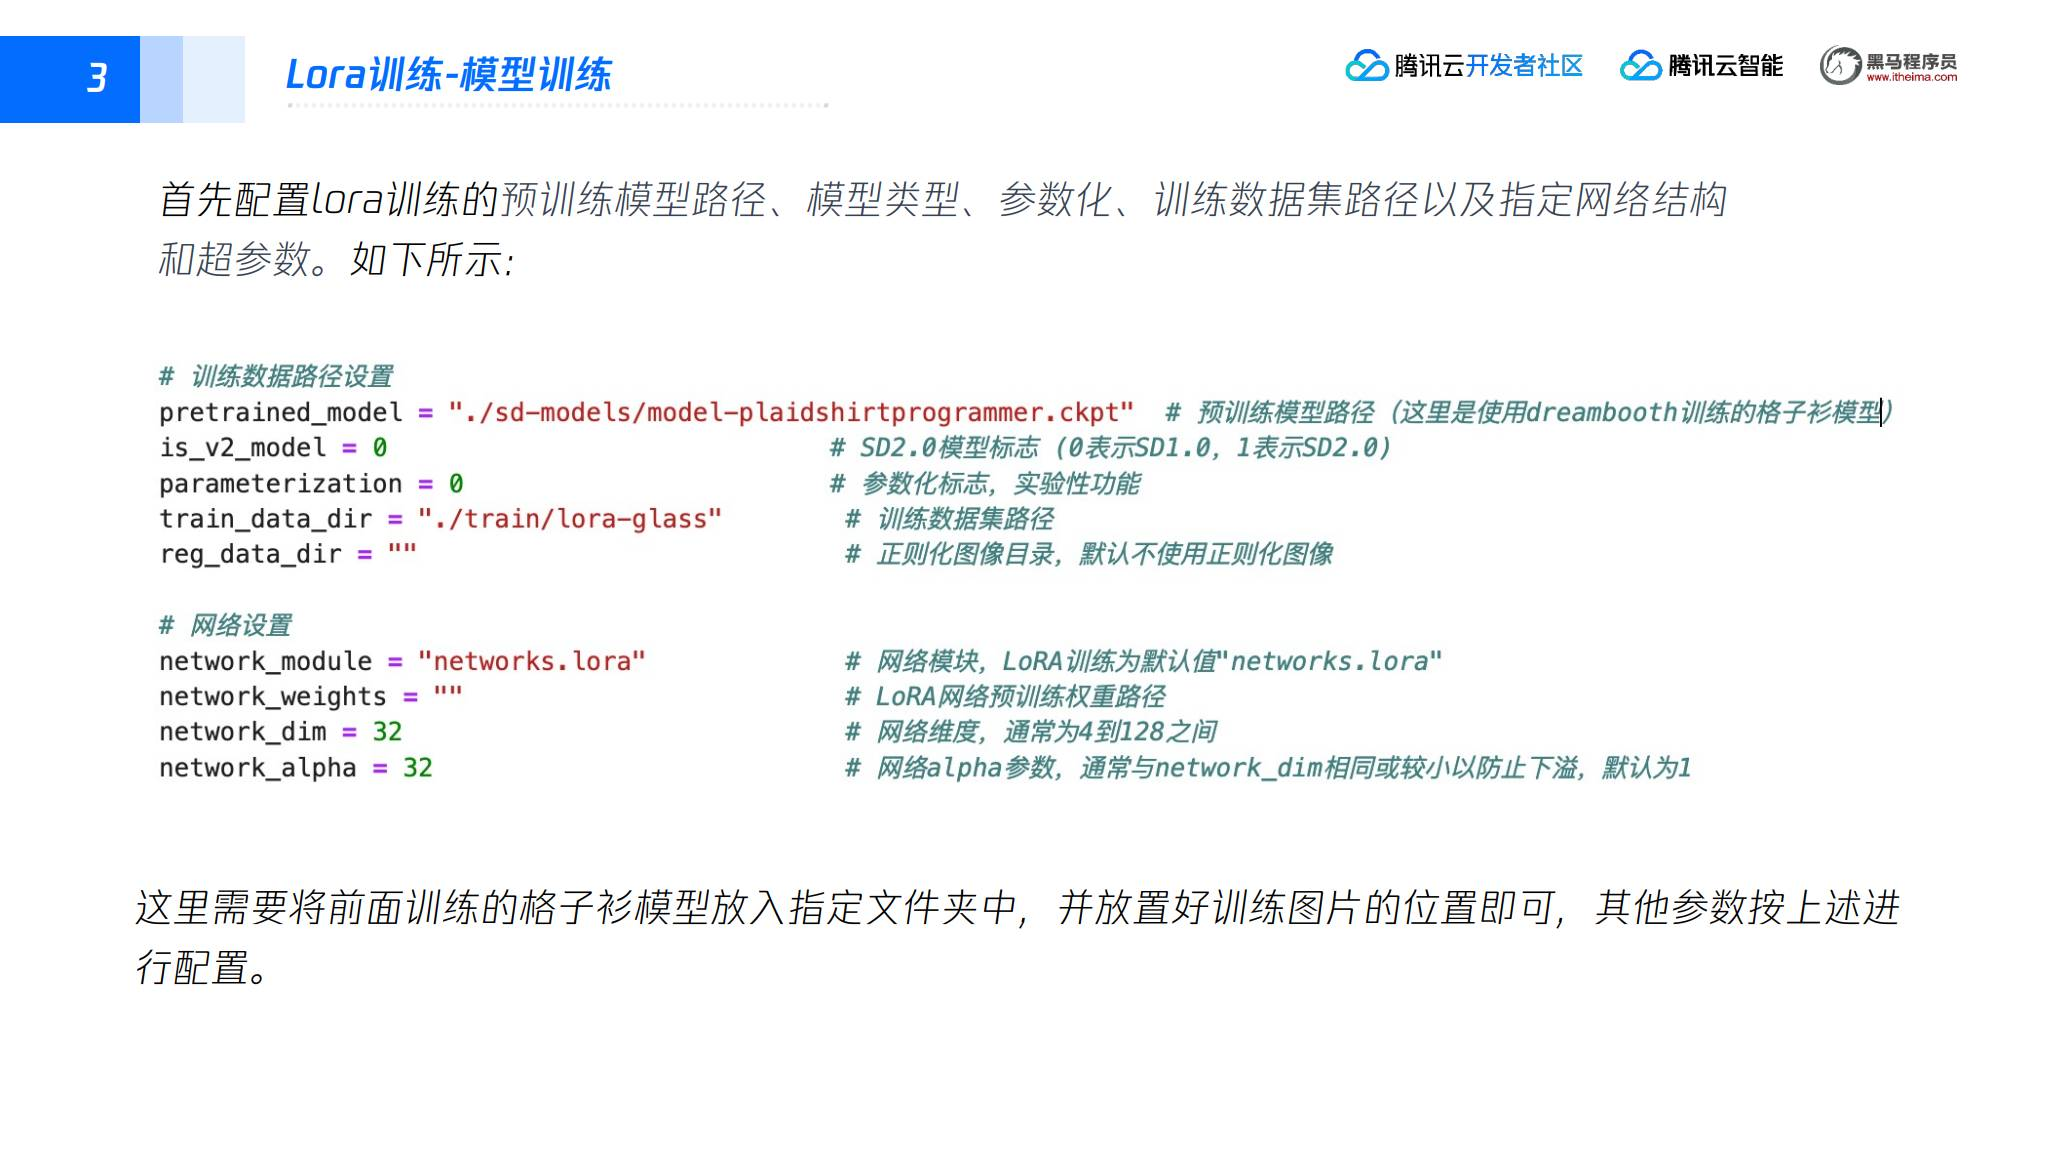

在 LoRA 项目的 `train.sh` 中配置模型路径和低秩网络。课件以 Python 式赋值展示值，这里将字符串写成 Bash 赋值格式，保留值和变量名：

```bash
pretrained_model="./sd-models/model-plaidshirtprogammer.ckpt"
is_v2_model=0
parameterization=0
train_data_dir="./train/lora-glass"
reg_data_dir=""
network_module="networks.lora"
network_weights=""
network_dim=32
network_alpha=32
```

基础权重使用前面 DreamBooth 的格子衫模型；截图的文件名写作 `model-plaidshirtprogammer.ckpt`，后面的 WebUI 图写作 `model-plaidshirtprogrammer.ckpt`，应以真实文件名为准。`network_weights` 留空表示这里没有指定已有 LoRA 权重。`is_v2_model=0` 采用课件的 SD 1.x 配置，低秩维度和 alpha 均为 32。

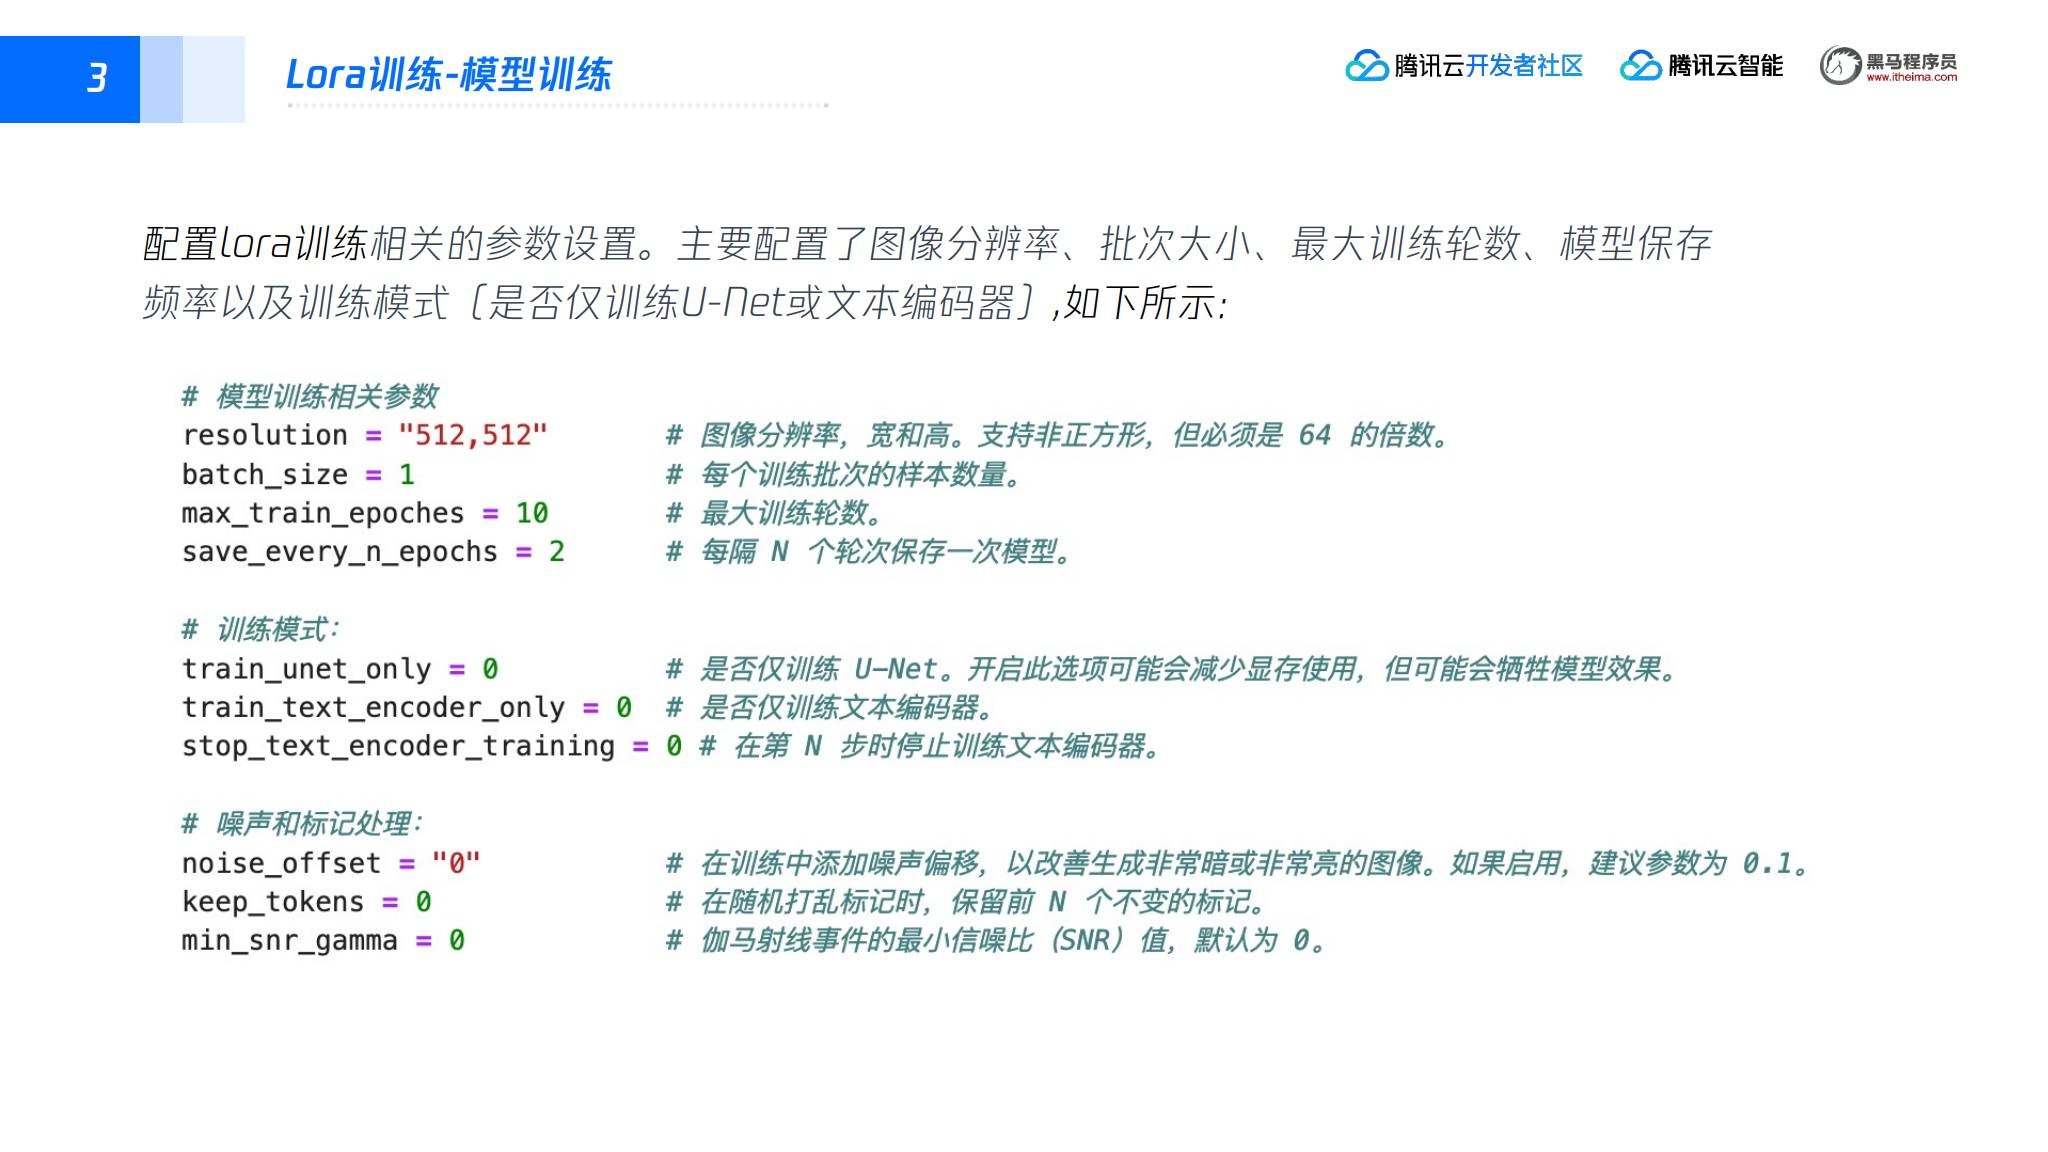

```bash
resolution="512,512"
batch_size=1
max_train_epochs=10
save_every_n_epochs=2
train_unet_only=0
train_text_encoder_only=0
stop_text_encoder_training=0
noise_offset="0"
keep_tokens=0
min_snr_gamma=0
```

训练 10 轮，每 2 轮保存一次。`resolution` 可为非正方形，但课件要求宽、高为 64 的倍数。两个 `only` 开关都关闭；`keep_tokens=0` 不保留固定前缀 token，`noise_offset` 和 `min_snr_gamma` 本示例设为 0。

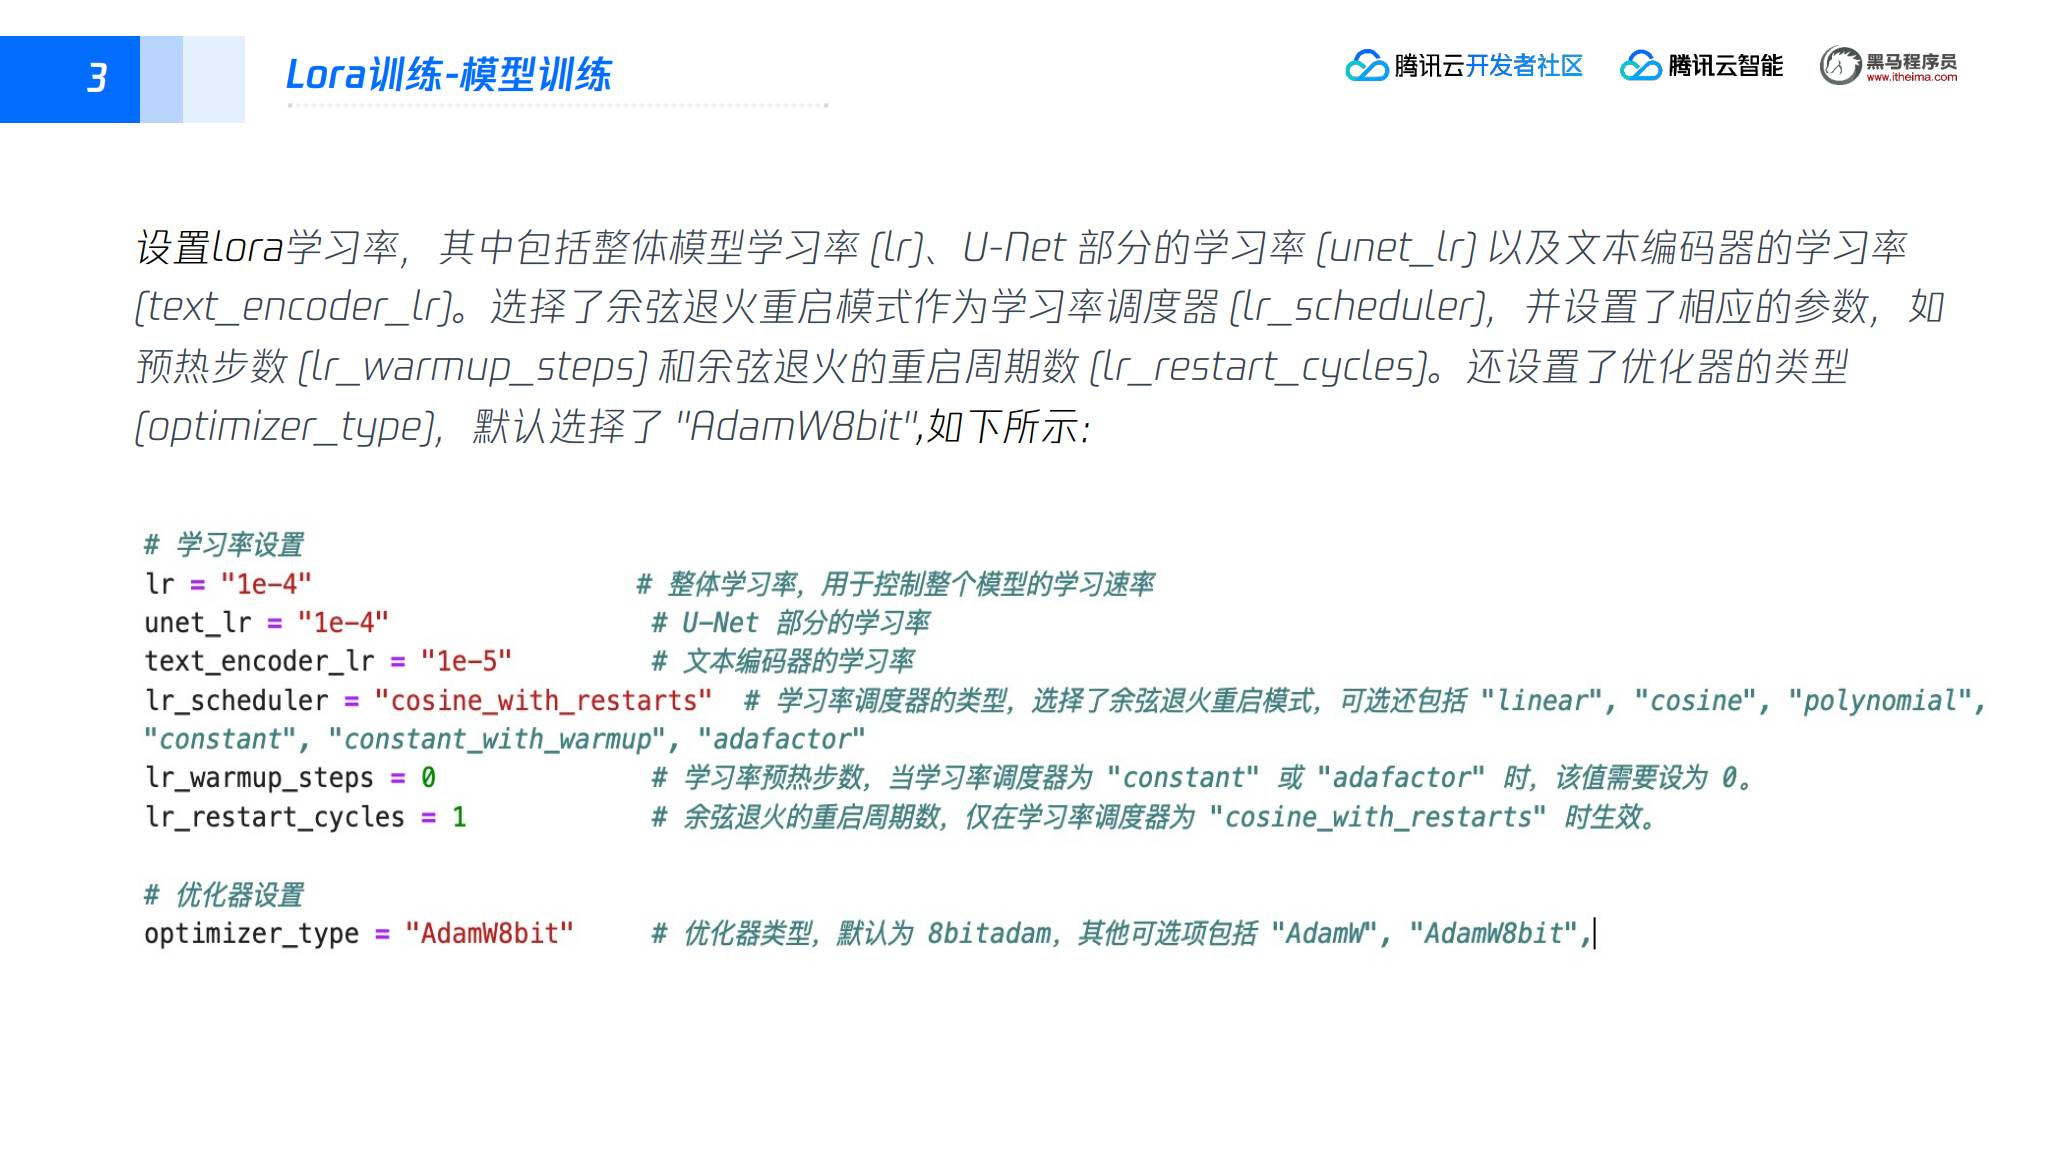

```bash
lr="1e-4"
unet_lr="1e-4"
text_encoder_lr="1e-5"
lr_scheduler="cosine_with_restarts"
lr_warmup_steps=0
lr_restart_cycles=1
optimizer_type="AdamW8bit"
```

文本编码器学习率比 U-Net 小一个数量级；本实验不使用学习率预热，余弦退火重启周期数为 1。

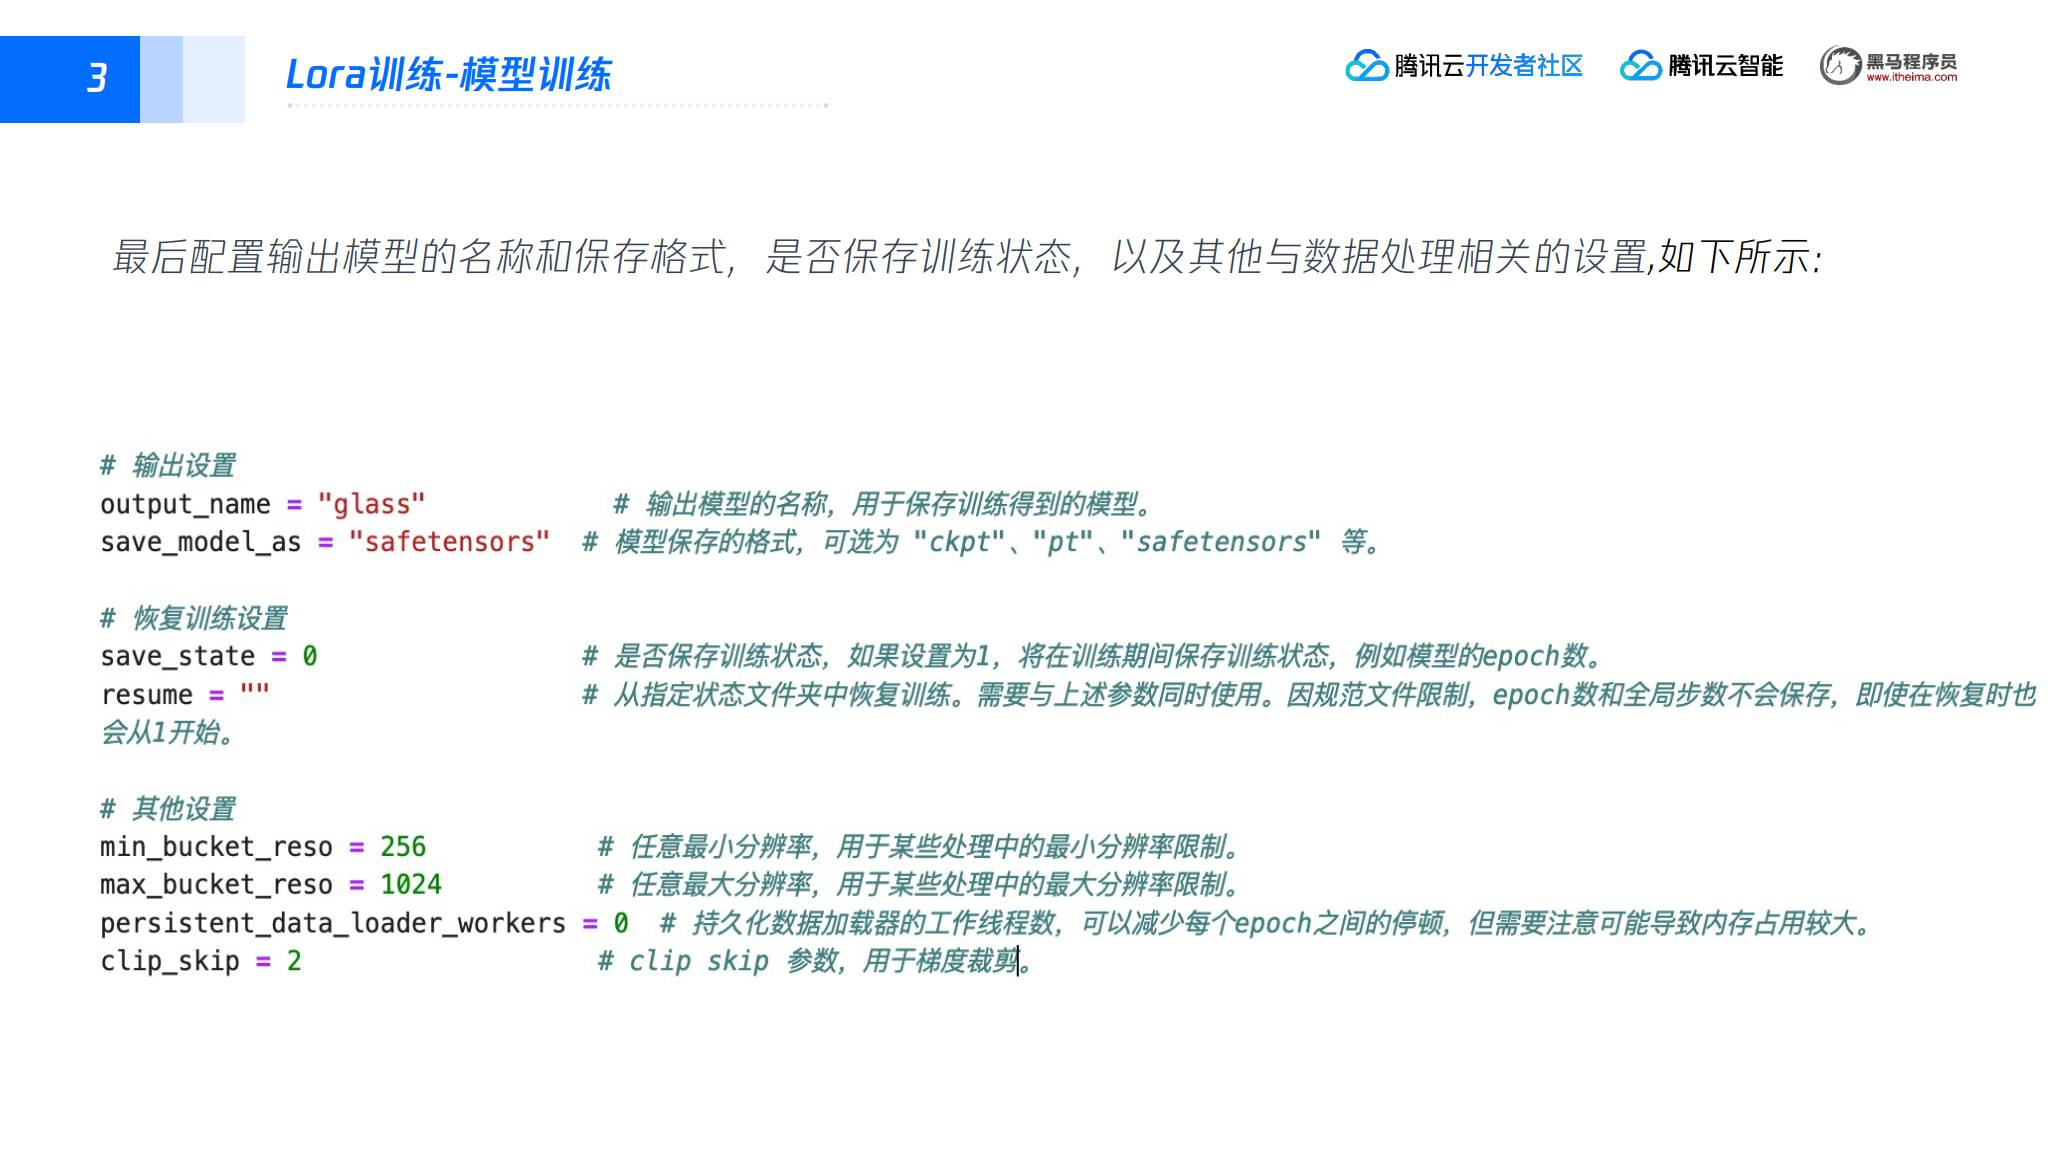

```bash
output_name="glass"
save_model_as="safetensors"
save_state=0
resume=""
min_bucket_reso=256
max_bucket_reso=1024
persistent_data_loader_workers=0
clip_skip=2
```

LoRA 权重使用 `glass` 为输出名称，格式为 `safetensors`，不保存恢复训练状态，也不从已有状态恢复。课件说明：即使使用恢复状态，所展示实现中 epoch 和全局步数也可能重新计数。此处 `clip_skip=2` 与前面 DreamBooth 的值不同，保留各自实验配置。

在完整 `train.sh` 中设置好上述变量和条件参数后，通过 Accelerate 调用 `./sd-scripts/train_network.py`。讲义标题称为分布式启动，但 Accelerate 也可用于单进程，实际模式由启动参数和配置决定。

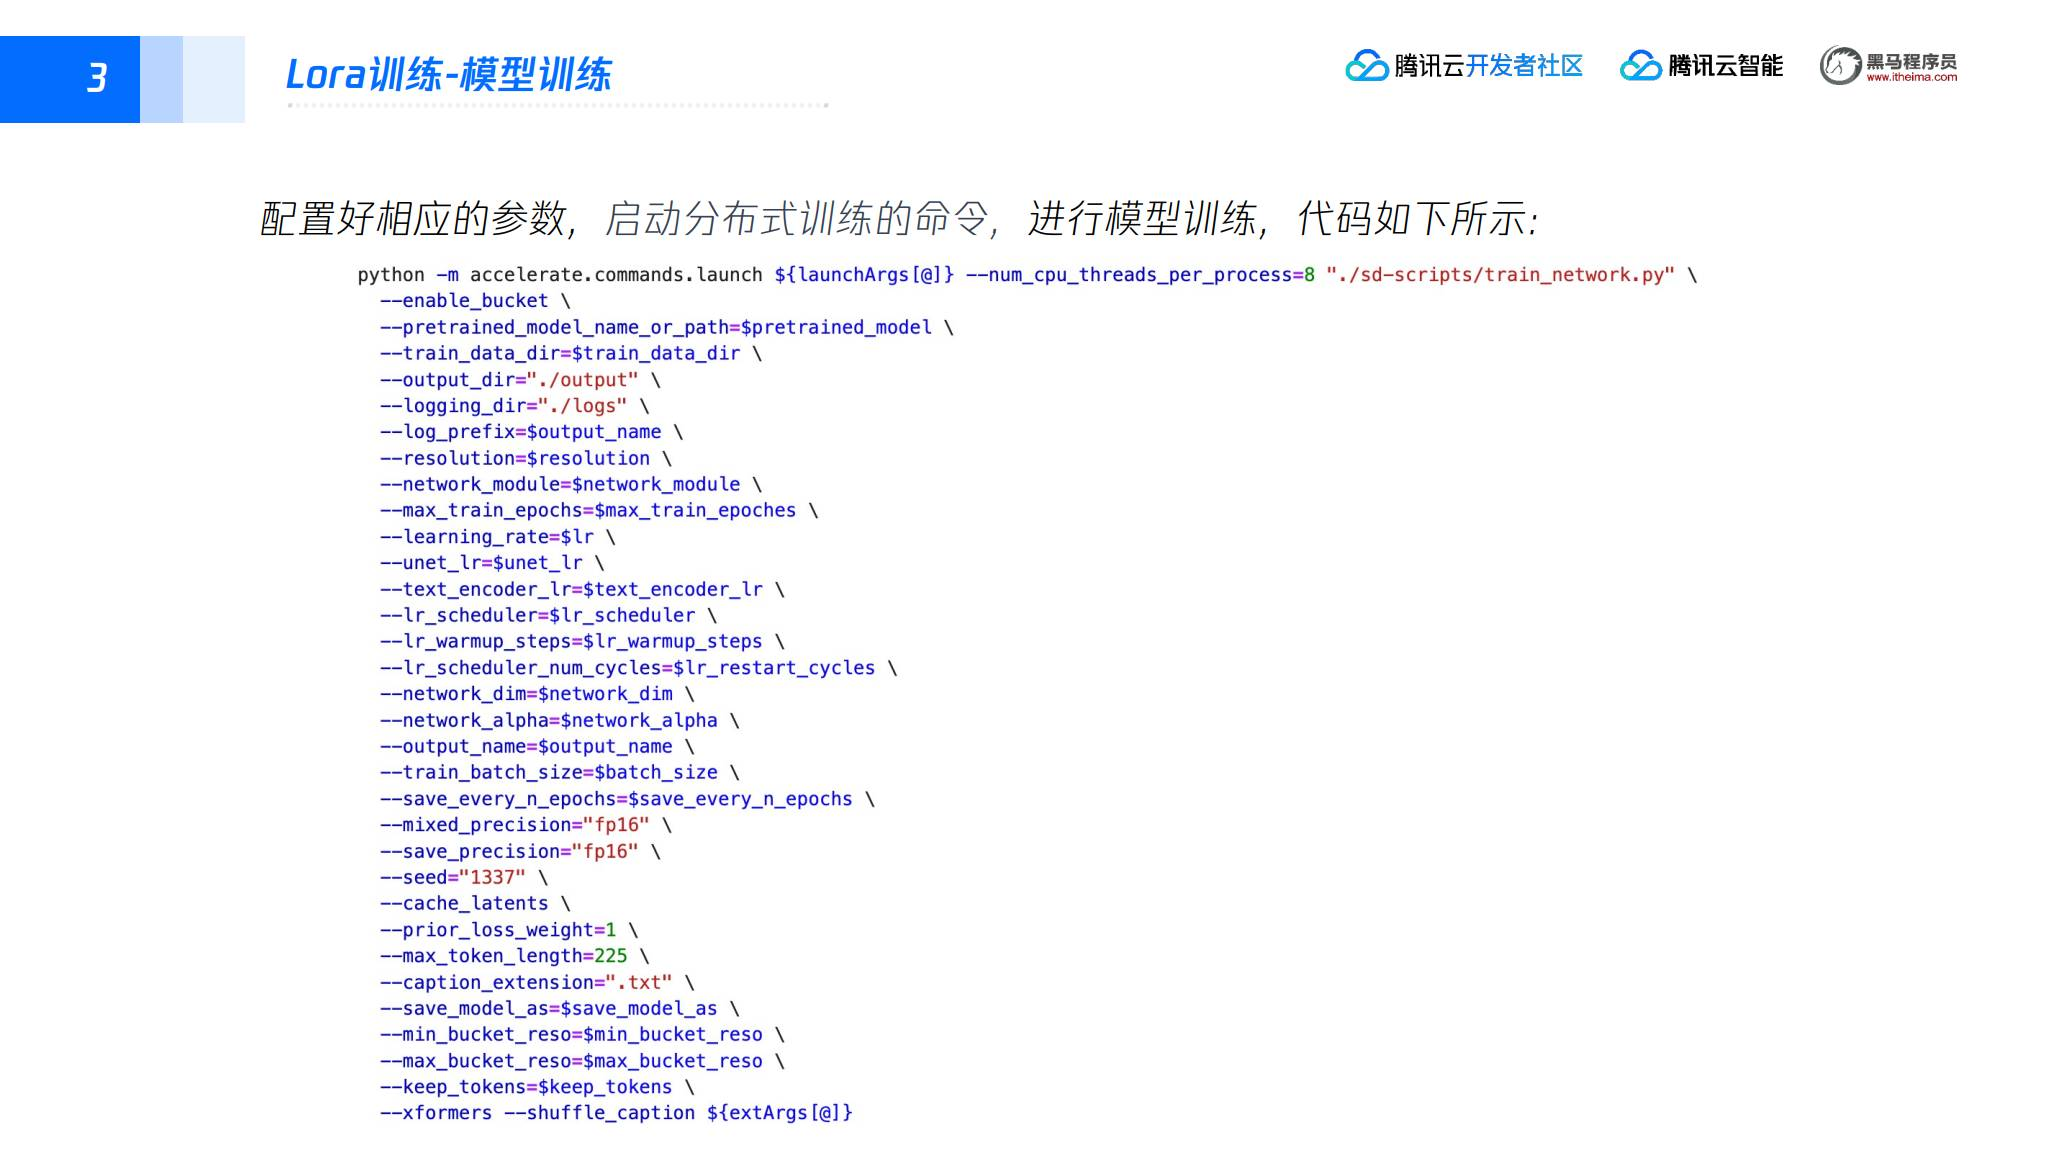

第 44 页展示的启动片段如下（Bash 脚本语法）：

```bash
python -m accelerate.commands.launch ${launchArgs[@]} --num_cpu_threads_per_process=8 "./sd-scripts/train_network.py" \
    --enable_bucket \
    --pretrained_model_name_or_path=$pretrained_model \
    --train_data_dir=$train_data_dir \
    --output_dir="./output" \
    --logging_dir="./logs" \
    --log_prefix=$output_name \
    --resolution=$resolution \
    --network_module=$network_module \
    --max_train_epochs=$max_train_epochs \
    --learning_rate=$lr \
    --unet_lr=$unet_lr \
    --text_encoder_lr=$text_encoder_lr \
    --lr_scheduler=$lr_scheduler \
    --lr_warmup_steps=$lr_warmup_steps \
    --lr_scheduler_num_cycles=$lr_restart_cycles \
    --network_dim=$network_dim \
    --network_alpha=$network_alpha \
    --output_name=$output_name \
    --train_batch_size=$batch_size \
    --save_every_n_epochs=$save_every_n_epochs \
    --mixed_precision="fp16" \
    --save_precision="fp16" \
    --seed="1337" \
    --cache_latents \
    --prior_loss_weight=1 \
    --max_token_length=225 \
    --caption_extension=".txt" \
    --save_model_as=$save_model_as \
    --min_bucket_reso=$min_bucket_reso \
    --max_bucket_reso=$max_bucket_reso \
    --keep_tokens=$keep_tokens \
    --xformers --shuffle_caption ${extraArgs[@]}
```

`launchArgs`、`extraArgs` 是课程脚本中的参数数组，原页没有展开数组构造；上面的配置段加这一命令仍不是独立的完整脚本。输出模型进入 `./output`，日志进入 `./logs`；标签来自图片旁的 `.txt` 文件，命令启用 latent 缓存、caption 打乱和 FP16。

第 45 页日志显示训练到 `epoch 10/10`，在第 2、4、6、8 轮保存 `glass-000002.safetensors` 等文件，最后保存 `glass.safetensors`。日志末尾同时出现 `train.sh: line 154: syntax error near unexpected token '}'`：前面的权重保存记录不等于整个脚本无错误，需检查配套脚本尾部，再验证保存文件能否加载。

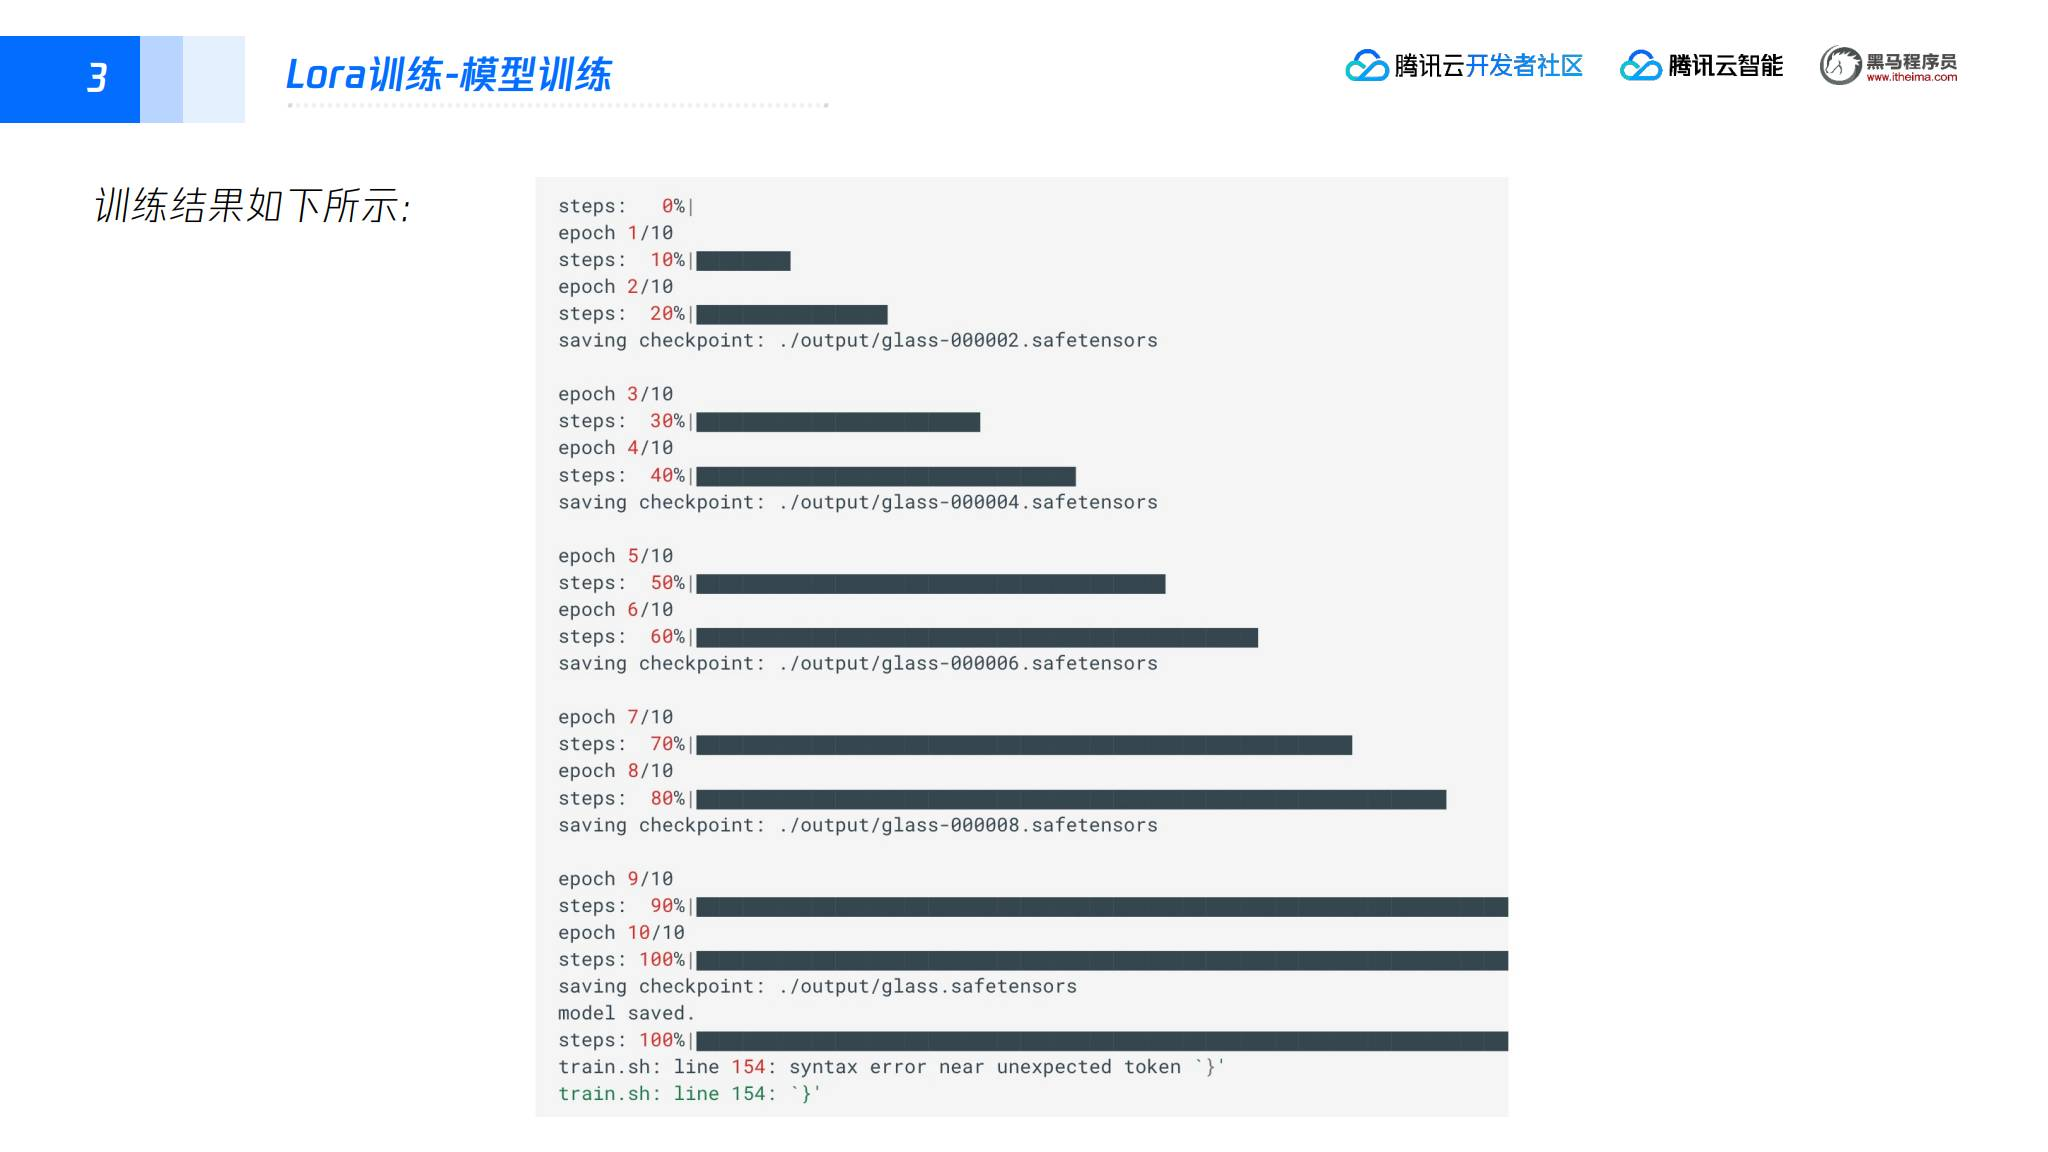

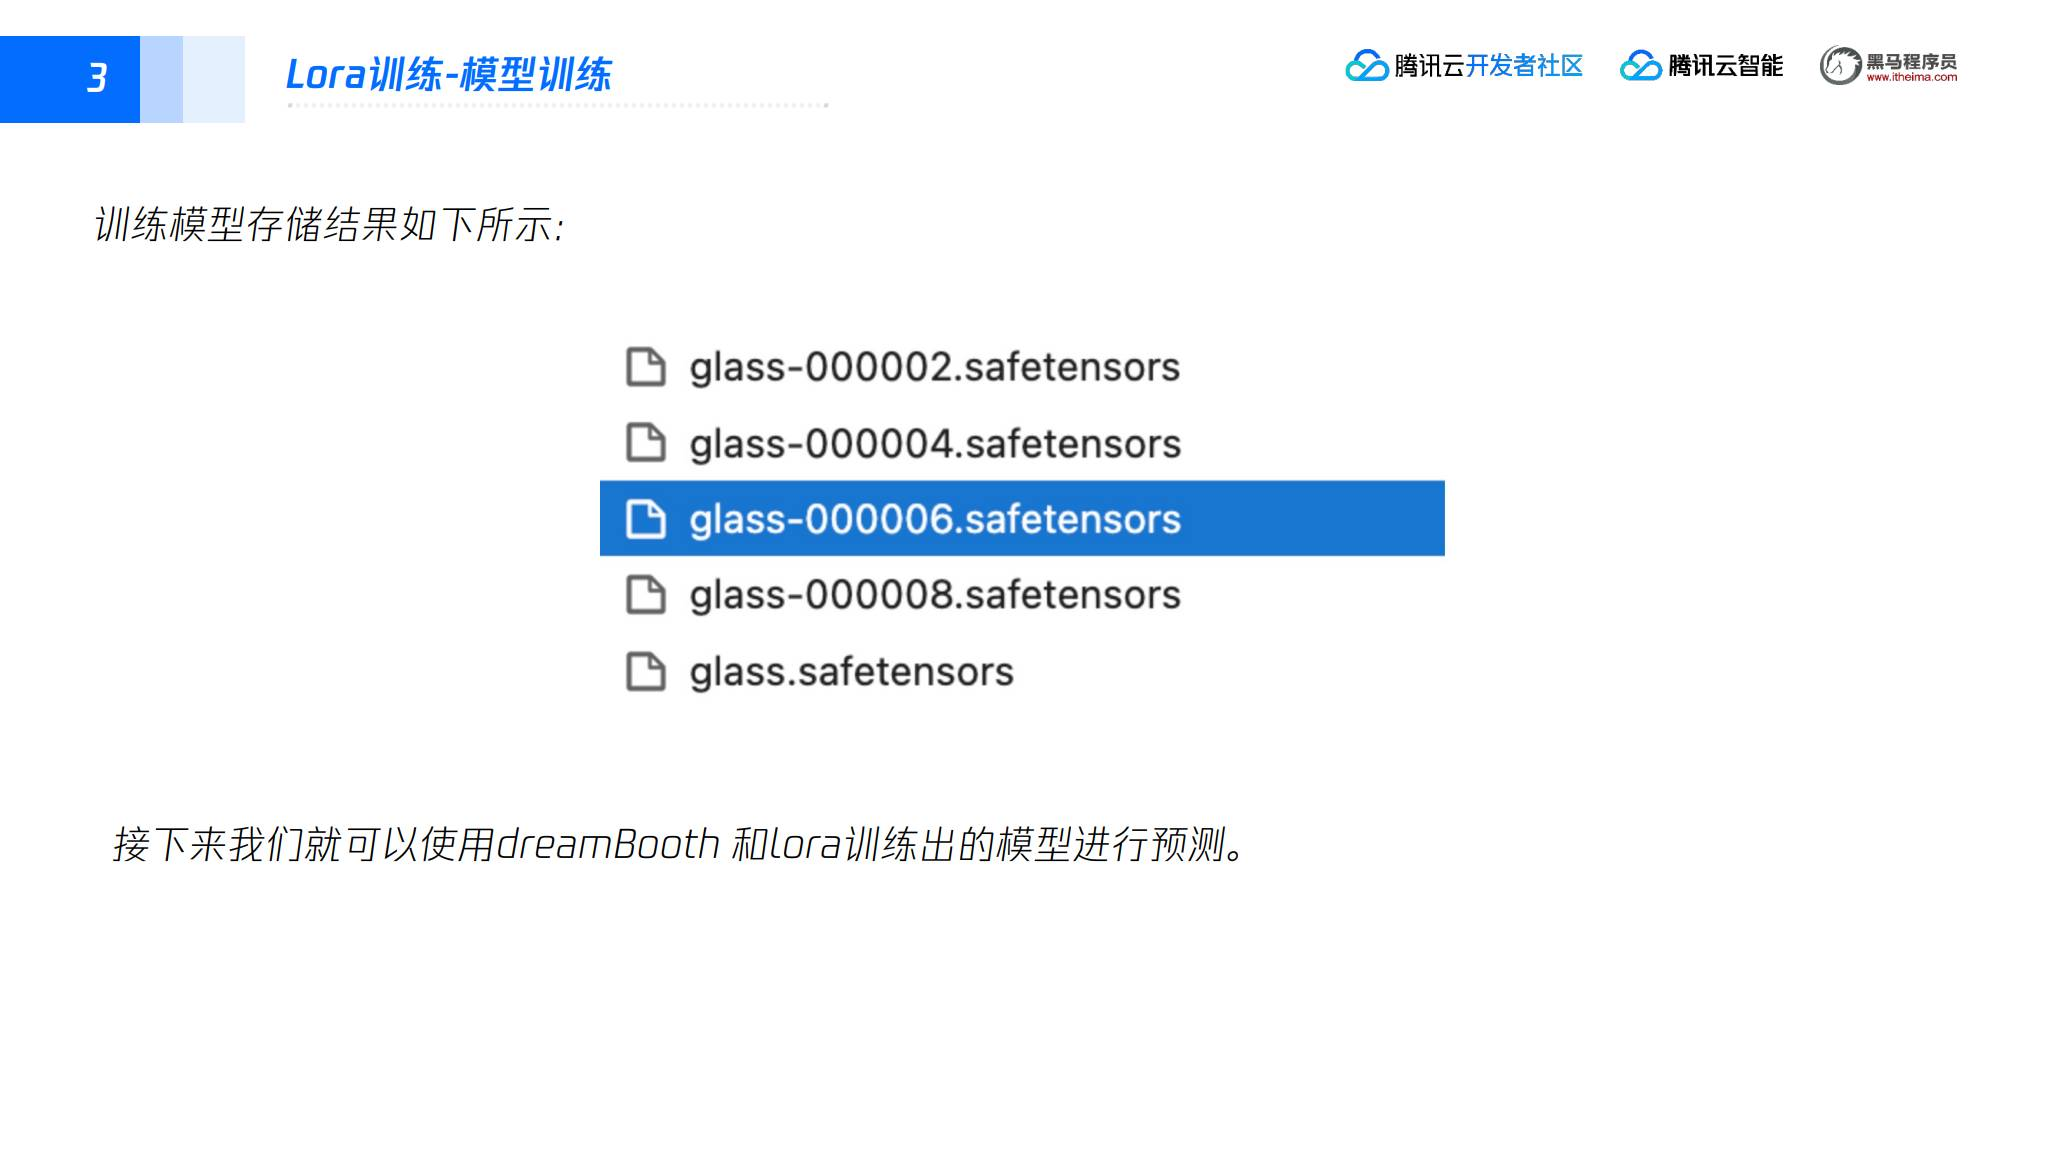

## 六、预训练模型的获取

讲义列出三个模型资源网站：

- [Hugging Face](https://huggingface.co/models)：开源机器学习模型平台；
- [Civitai](https://civitai.com/)：面向 AI 绘画模型的分享平台，包含模型介绍、教程和参考图；
- [哩布哩布 AI](https://www.liblibai.com/)：国内 AI 绘画模型和作品平台，也支持在线 Stable Diffusion 绘图。

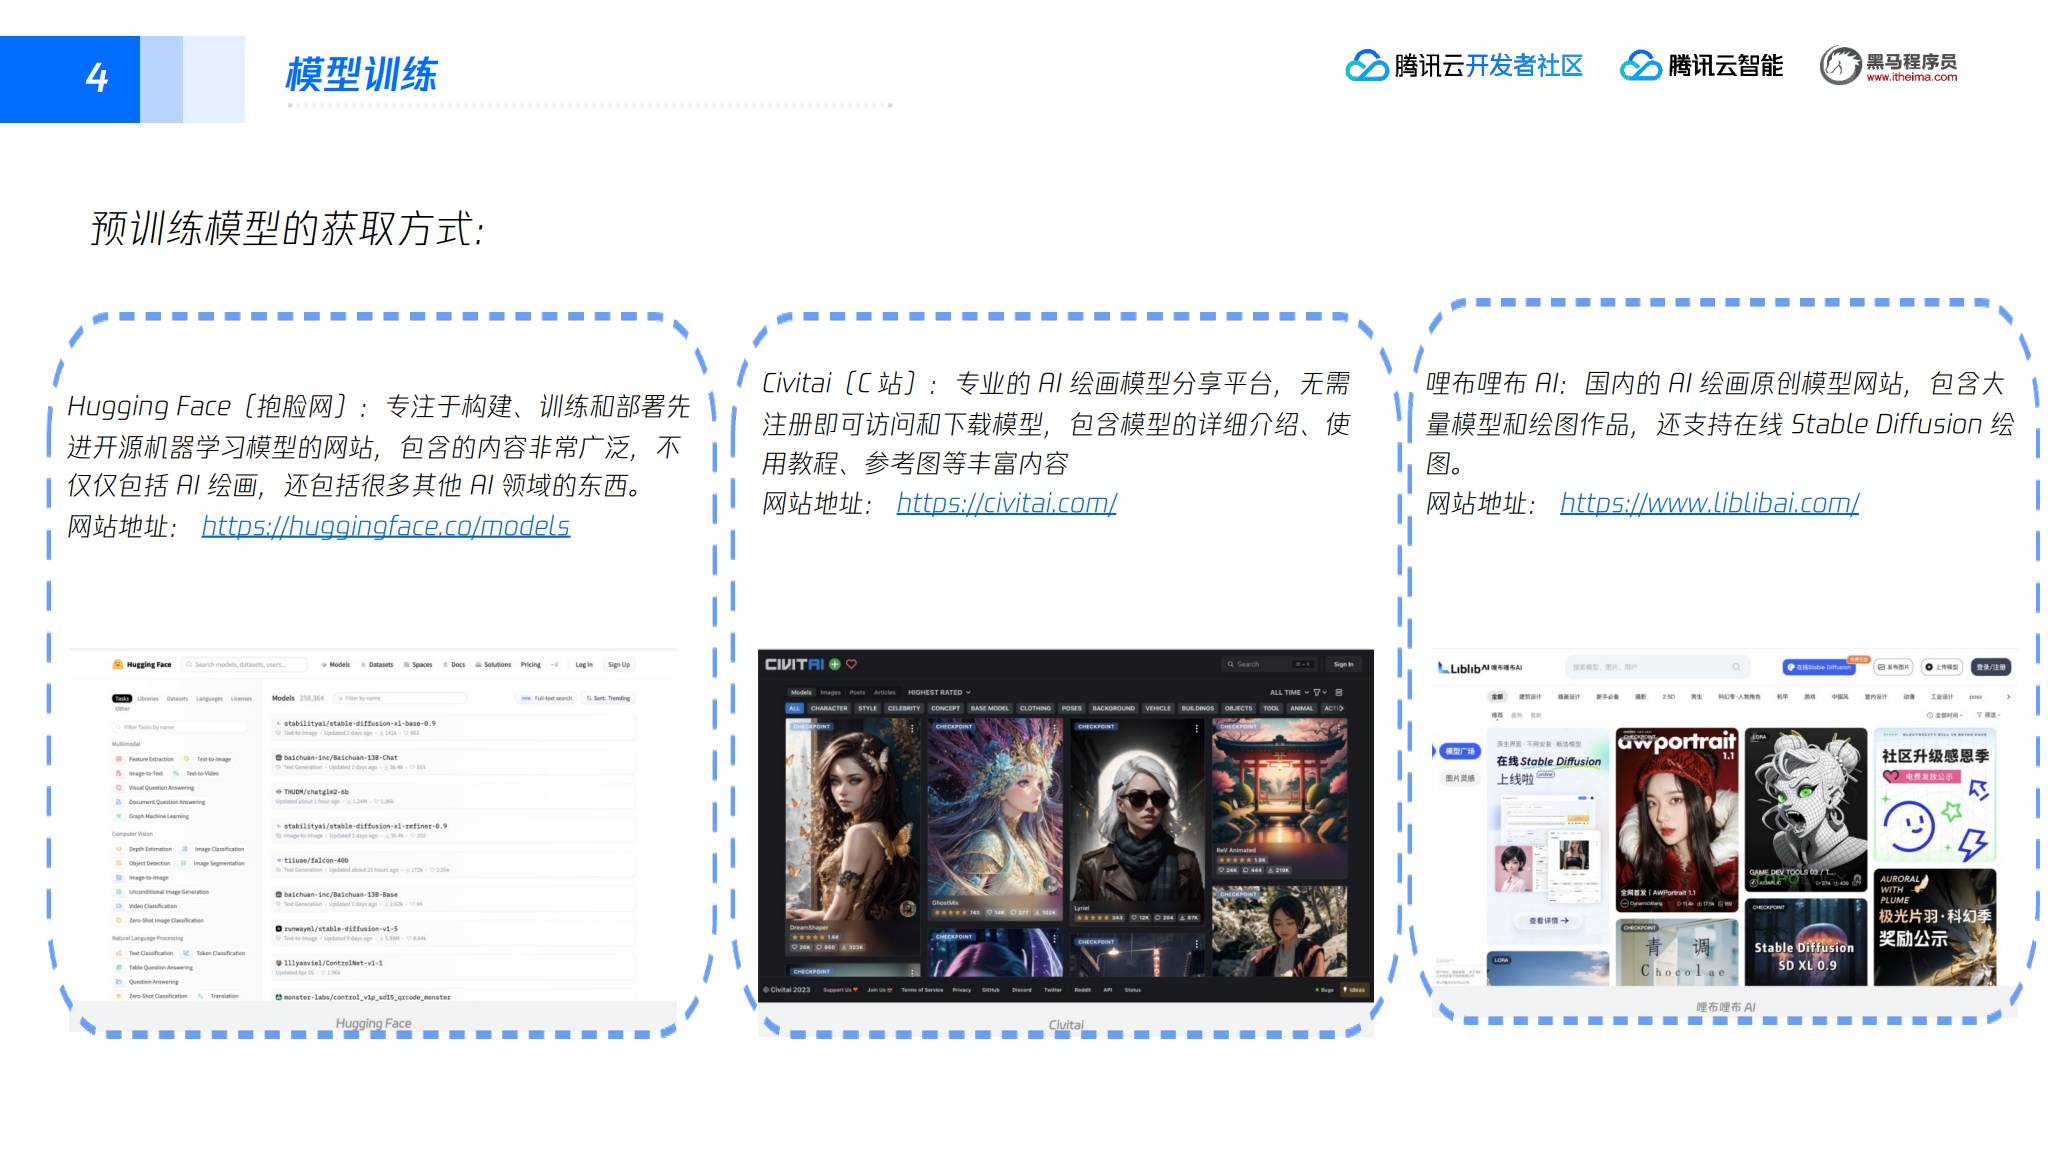

## 七、DreamBooth 和 LoRA 模型预测

### 1. DreamBooth 预测

在 WebUI 中使用 DreamBooth 模型：

1. 将转换后的 `.ckpt` 文件添加到 `stable-diffusion-webui/models/Stable-diffusion`；课件预测界面命名为 `model-plaidshirtprogrammer.ckpt`。
2. 在左上角 `Stable Diffusion checkpoint` 中选择模型，进入 `txt2img`。
3. 填入正向、反向 prompt。课件正向示例为 `masterpiece, best quality, Plaidshirtprogrammer, 1girl`；触发词必须与实际训练配置一致，前文已标注截图拼写差异。
4. 选择 `Generation`，设置图像宽、高。截图示例为 512×512、`DPM++ 2M Karras`、20 步、CFG Scale 7、seed -1。
5. 点击“生成”，在右侧结果区检查是否出现学习到的格子衫特征。截图中的参数和结果是课程演示，不代表每次生成完全相同。


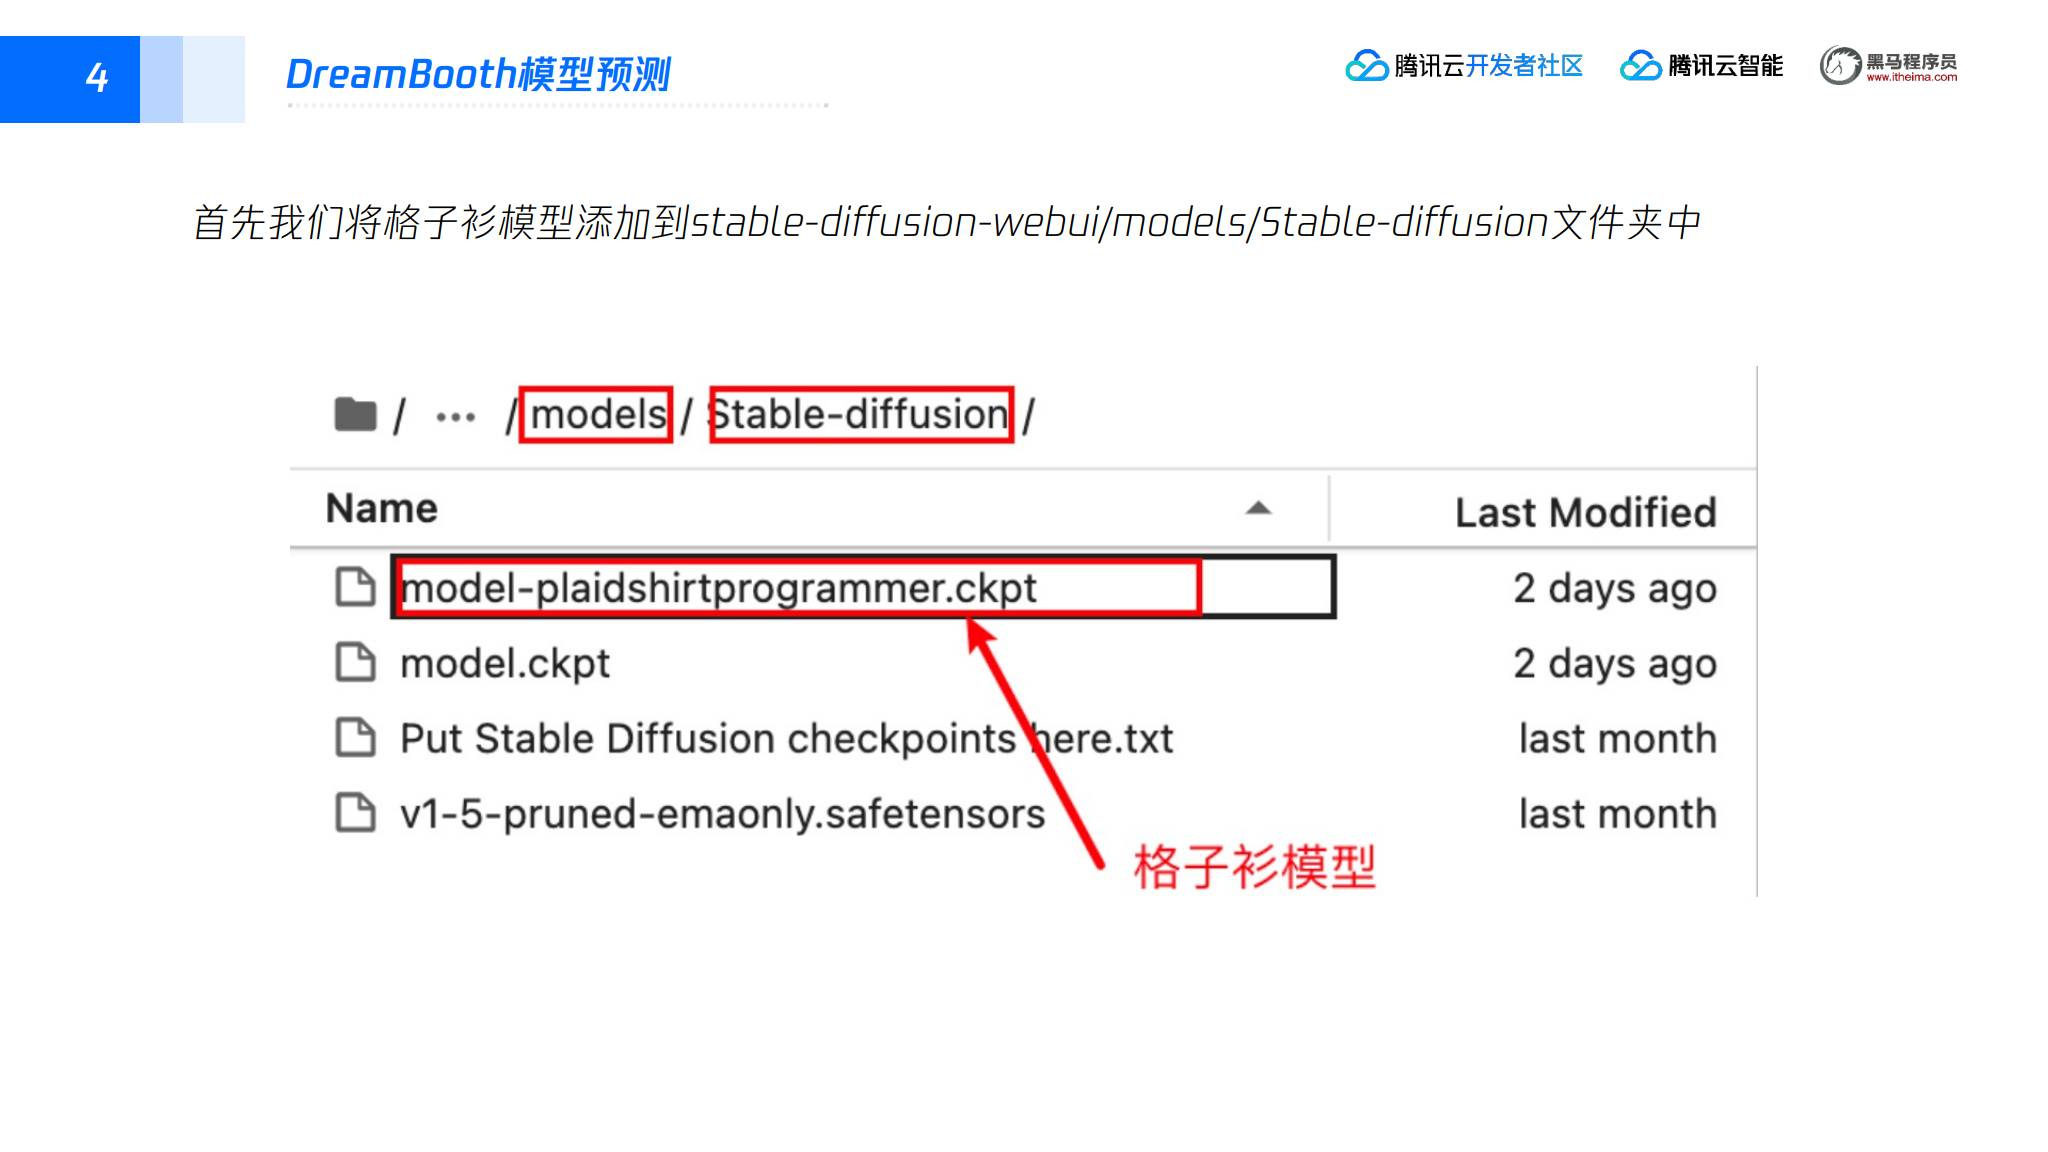

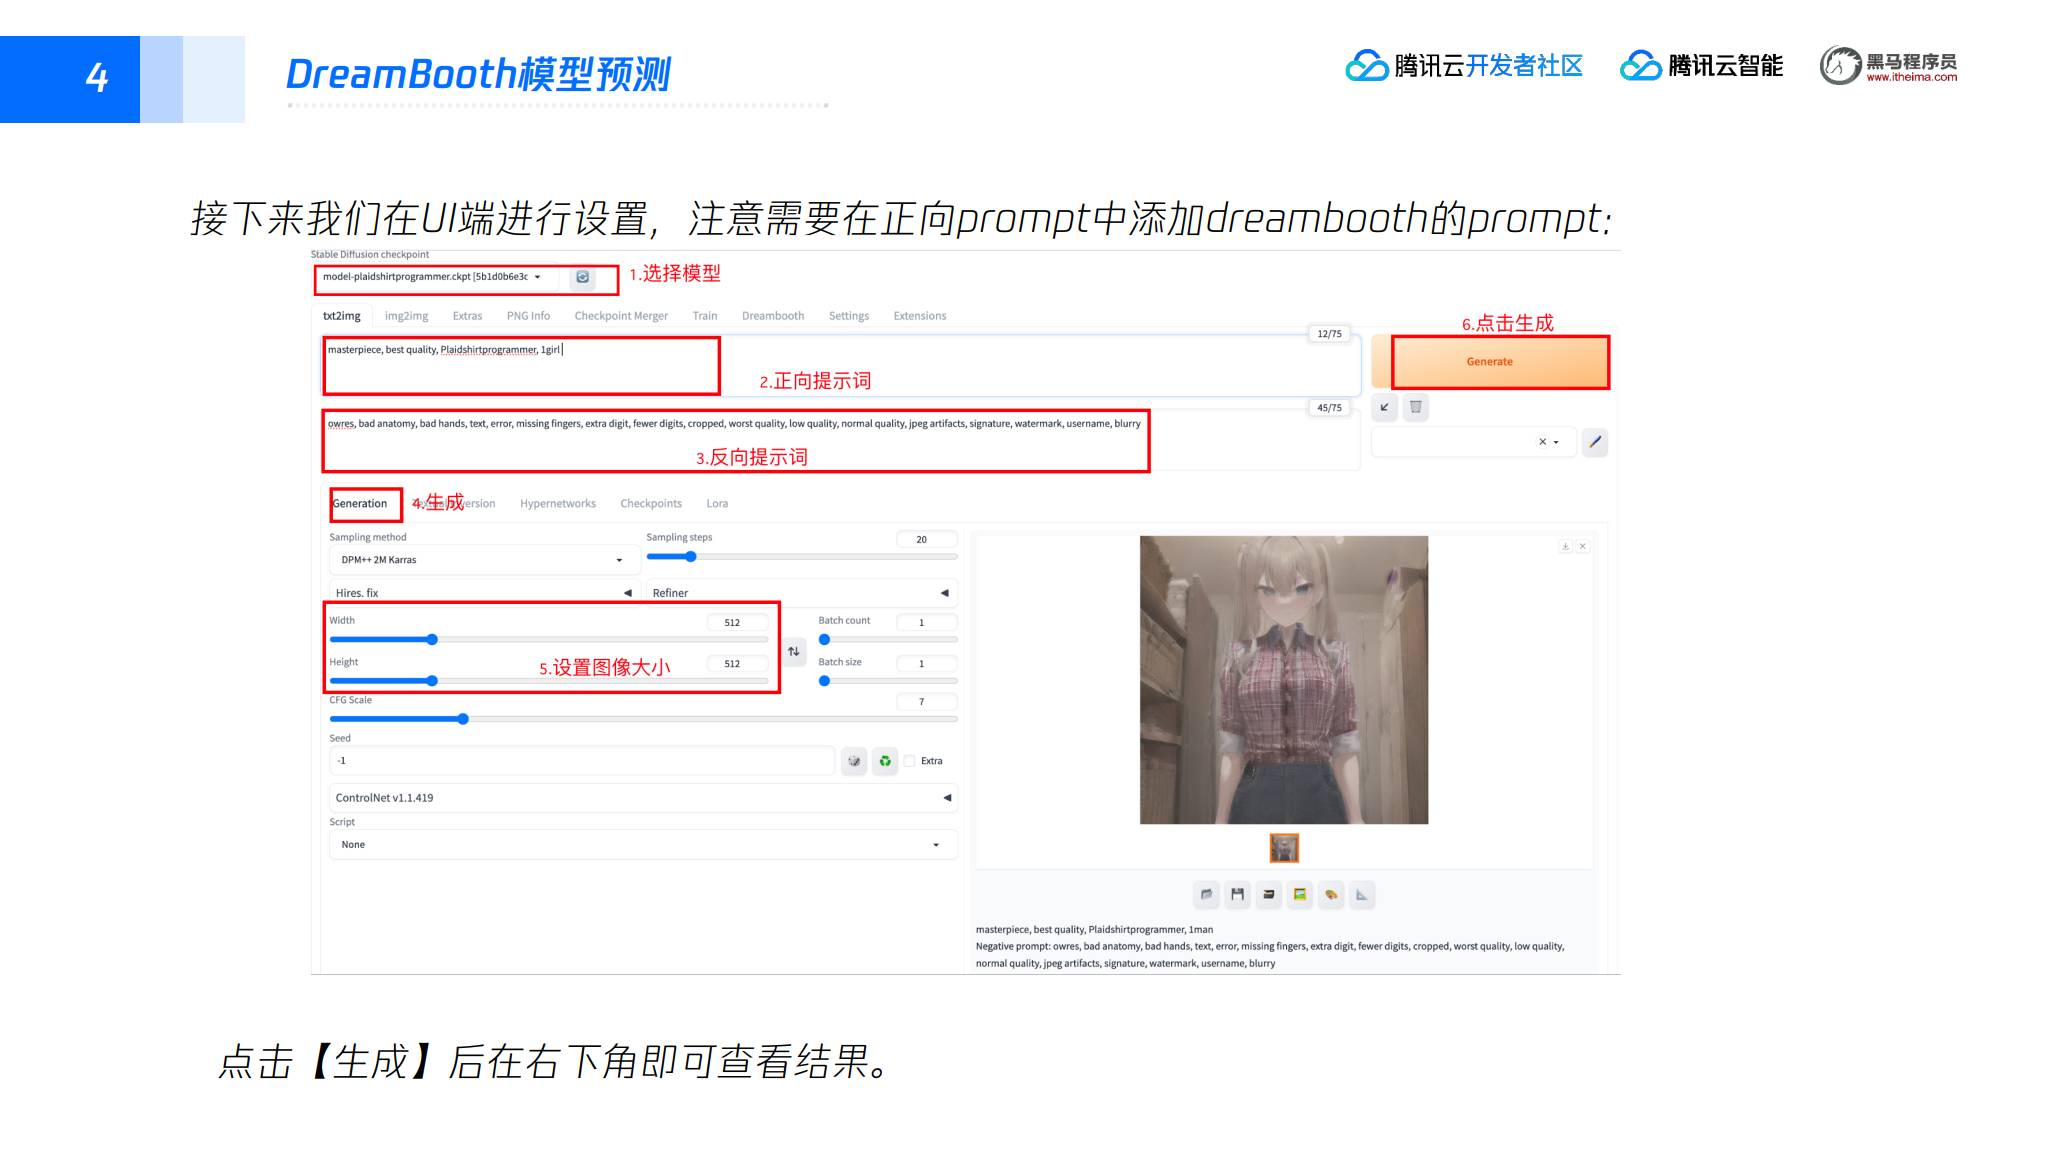

### 2. LoRA 预测

在 WebUI 中使用 LoRA 模型：

1. 将训练结果 `glass.safetensors` 添加到 `stable-diffusion-webui/models/Lora`。
2. 保持格子衫基础 checkpoint，打开文生图界面的 `Lora` 标签，选择 `glass` 模型卡片。
3. 确认正向 prompt 中已插入 `<lora:glass:1>`。`glass` 对应 LoRA 文件名主体，`1` 是截图中使用的权重。
4. 加入与基础模型一致的格子衫触发词和人物描述，切回 `Generation`，设置生成参数并点击“生成”。
5. 在结果区观察格子衫和眼镜是否同时出现。

课件上方 prompt 使用 `<lora:glass:1>`，第 54 页结果区底部却显示 `<lora:aki:1>`。本篇按实际加载的 `glass` 权重整理流程，并保留原截图，不把两者写成同一个模型名。


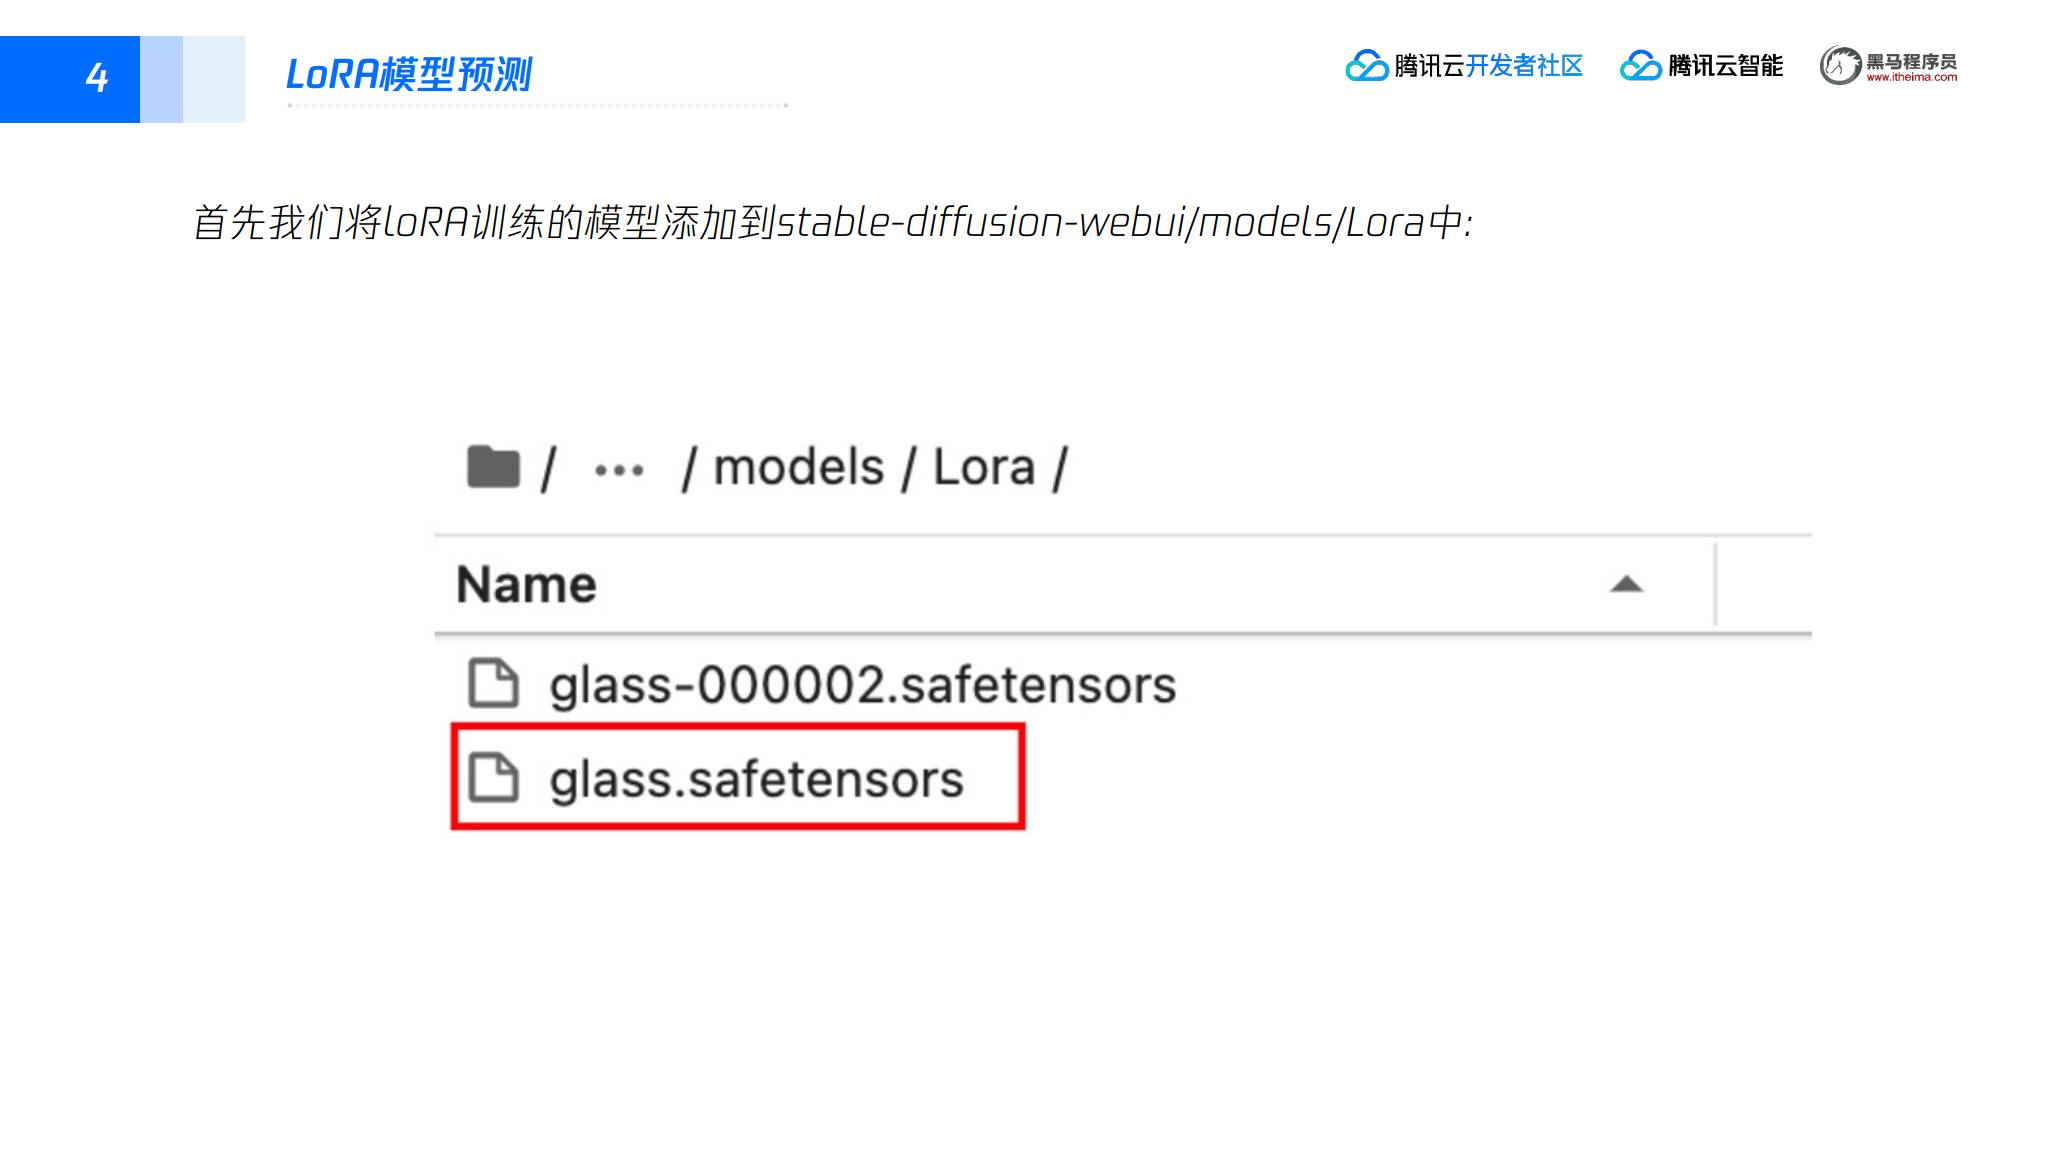

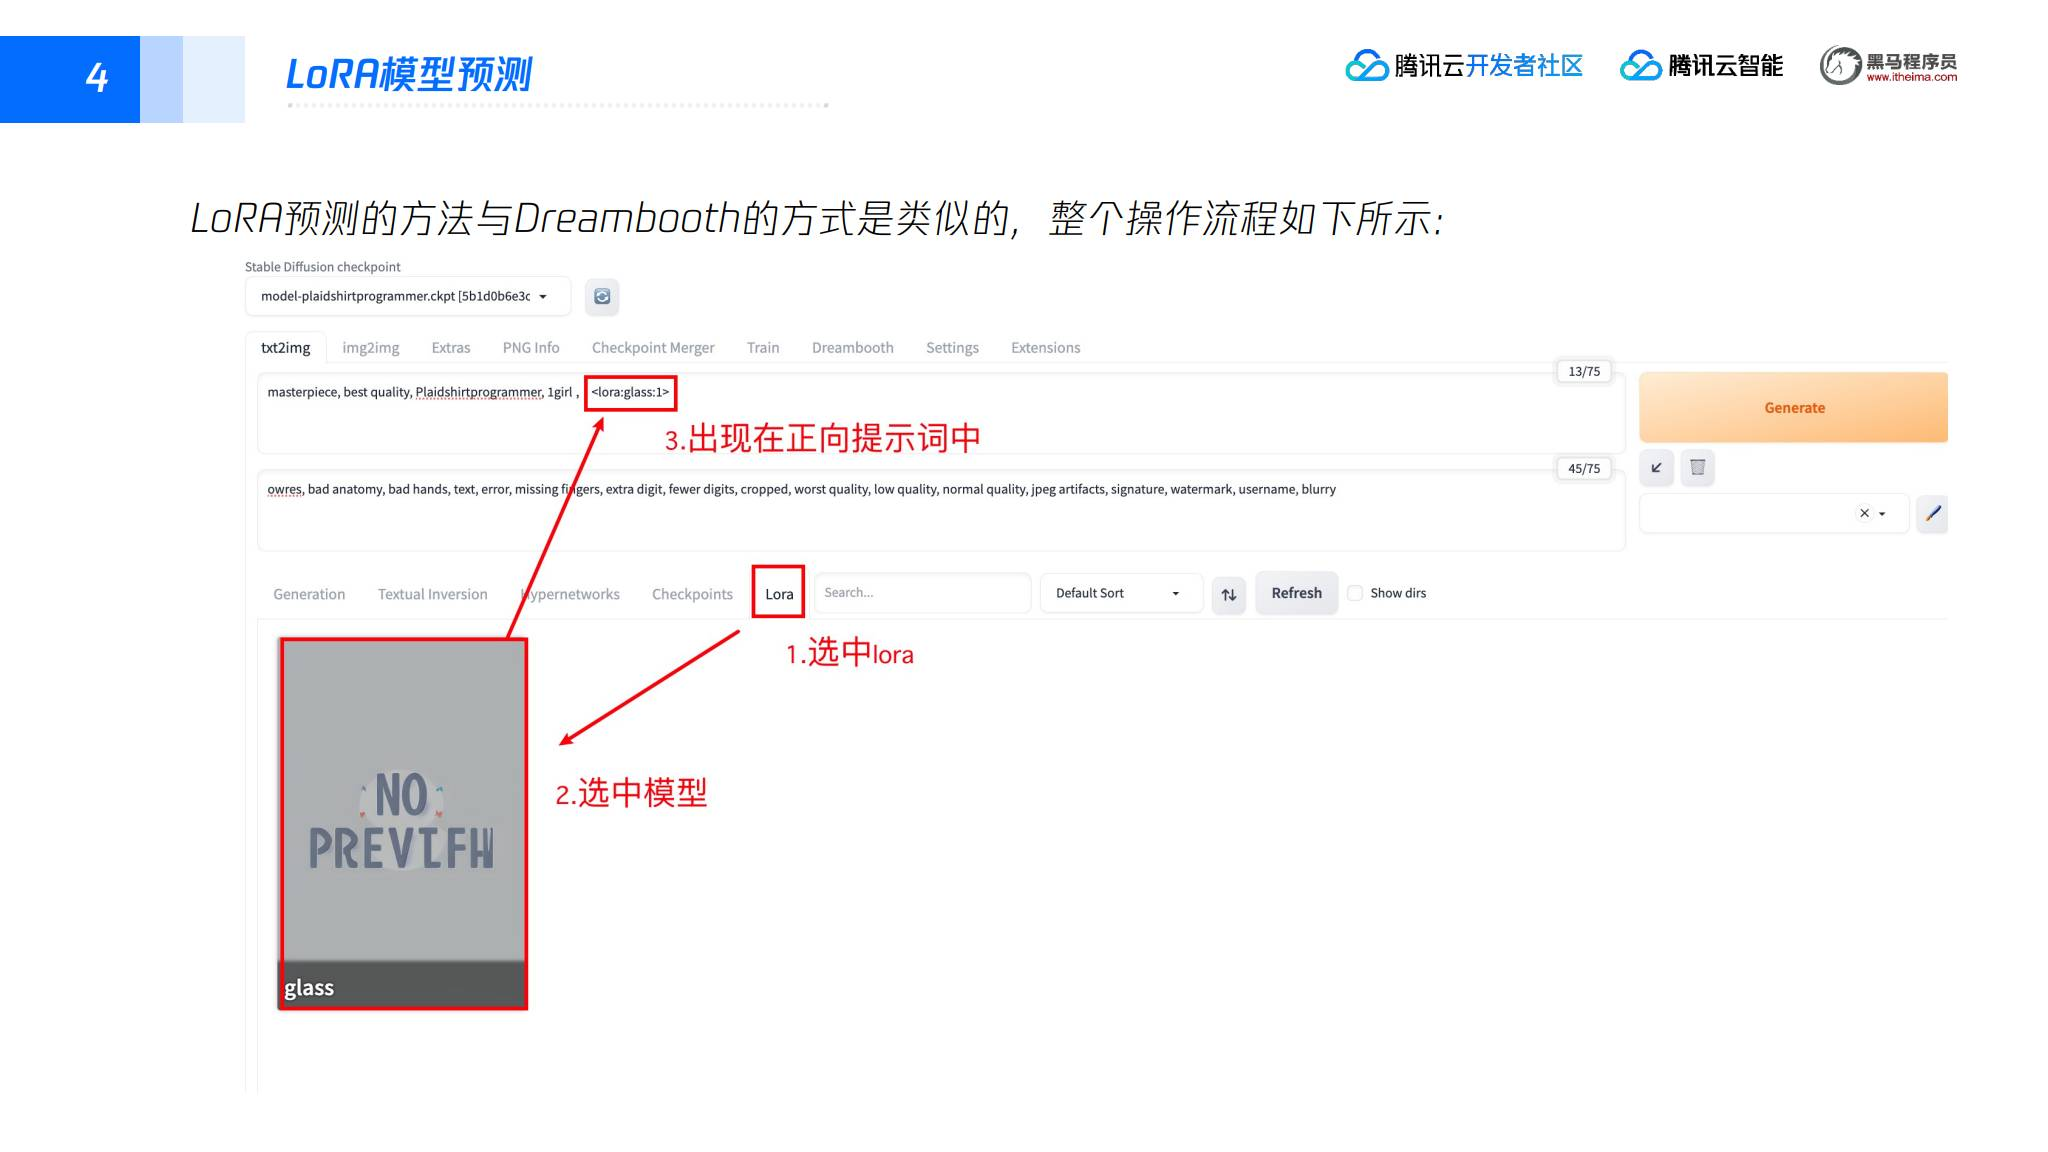

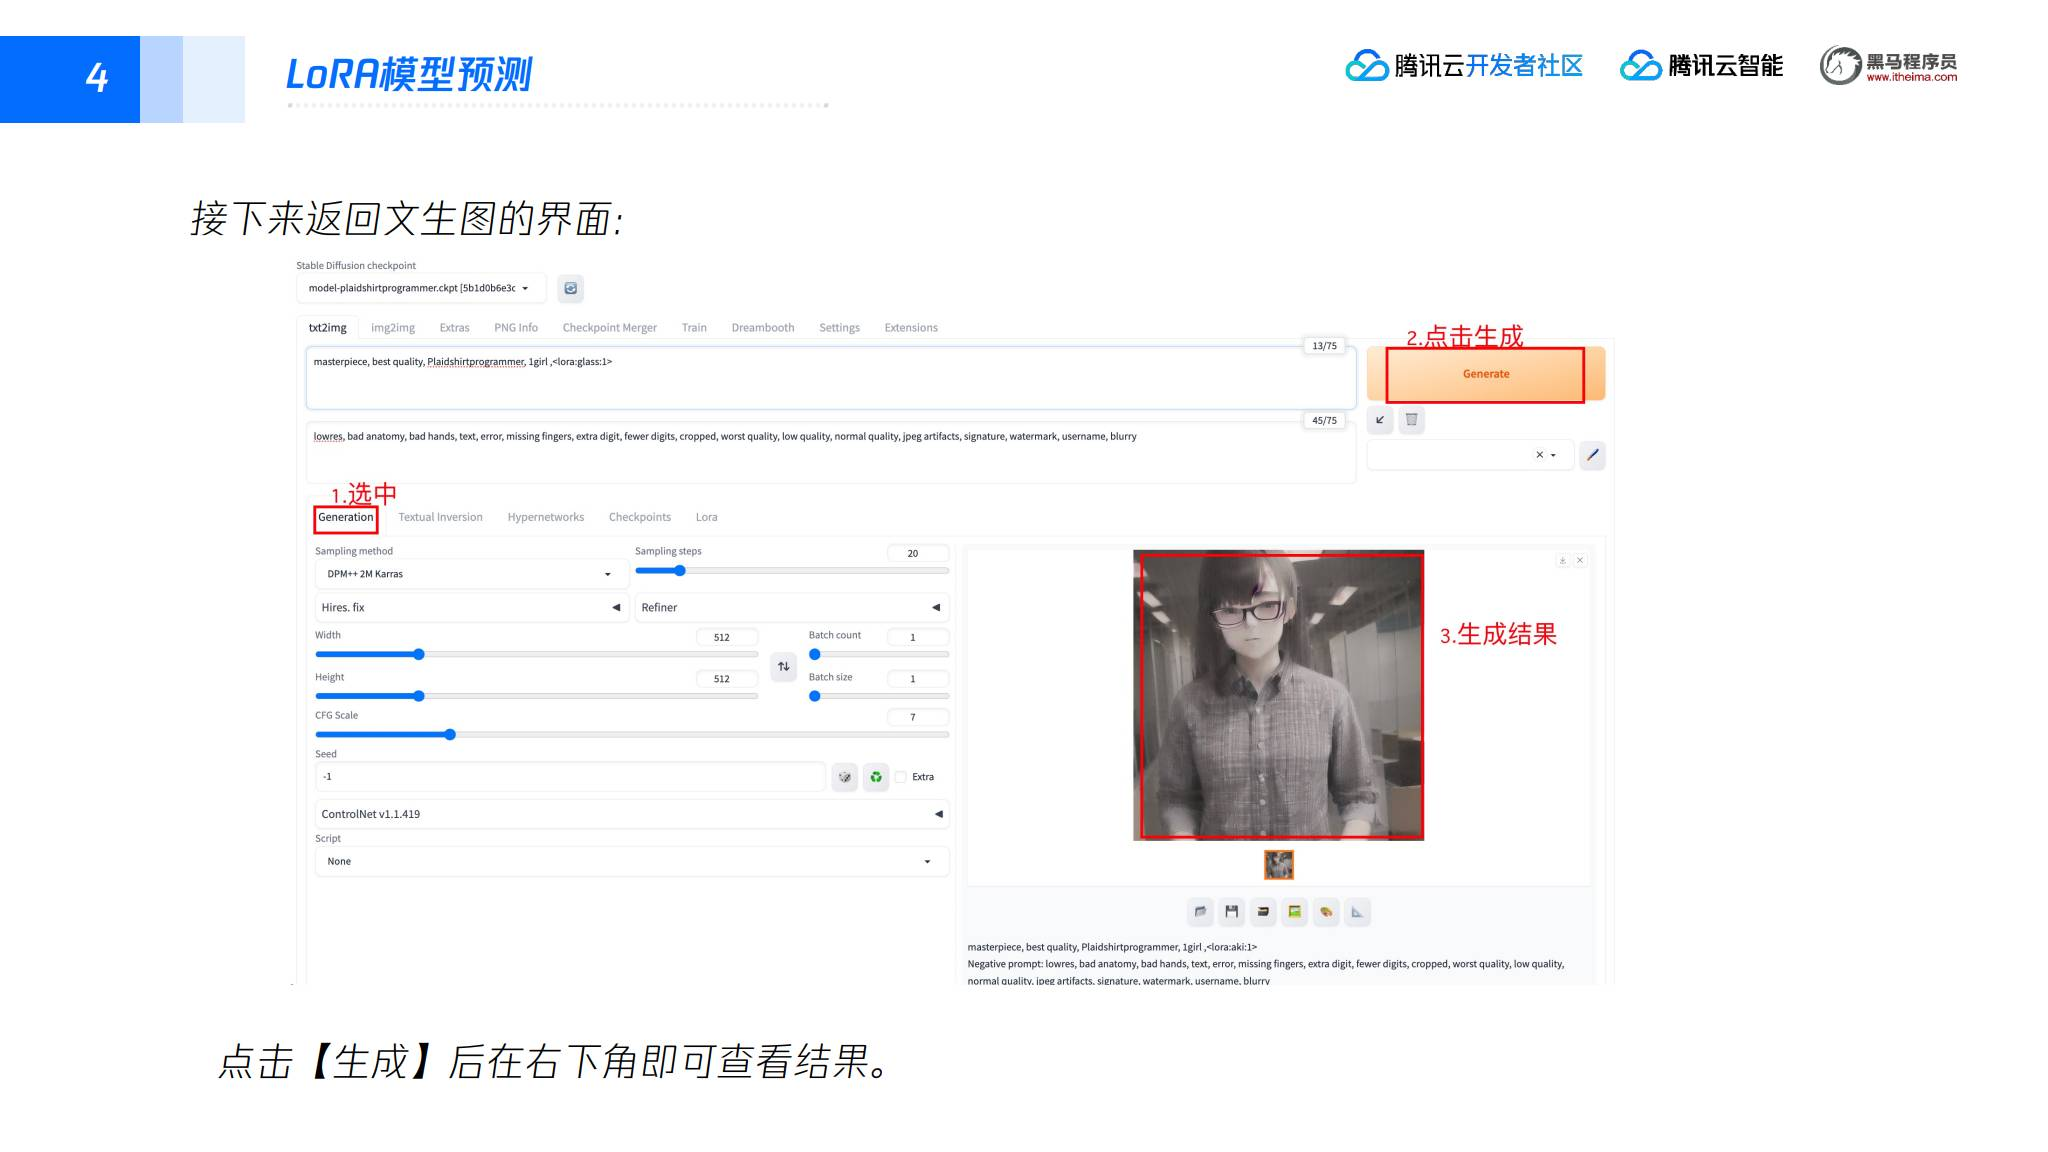

## 八、本篇要点

1. HAI 通过 GPU 云资源、预装环境和可视化入口降低 Stable Diffusion 的部署门槛。
2. WebUI 用于推理出图，JupyterLab 用于训练和调试；使用前需要准备 Python、Git、CUDA 等环境。
3. DreamBooth 适合用少量个性化图片微调专属主体或风格，课程示例使用 103 张格子衫图片，显存要求 24GB 以上。
4. LoRA 只学习部分参数的低秩增量，训练资源较小；课程示例使用 20 张带文字描述的图片，显存要求 8GB 以上。
5. DreamBooth 权重需要转换为 WebUI 可用格式，并放入 `models/Stable-diffusion`；LoRA 模型放入 `models/Lora`，再在 WebUI 中加载预测。